# 136 · How does decres-rescale-aug10-v1 work, and why does it fail where it fails?

Run `decres-rescale-aug10-v1` (src9 transformer4, res decoder, rescaled latent, augs on 10% of samples, ep300). Eval is **eager fp32** (compile eval bug).
100 lasers (10×10 grid on the box wall) × 1170 bins (100–1000 Hz, 2 axes) → per-sample z-score → 18 bands × 65 bins tokens → freq transformer per laser → laser transformer → 512-d latent `u` → conv decoder → 64×64 mask.

Ten questions a CVPR reviewer would ask, each with a measurement, a figure and an answer:

1. **Which parts of the signal does the model read?** Bands, axes, fine spectral structure, spatial pattern across lasers.
2. **Is there a physical object signature (mass loading), and does detectability follow it?** Cylinder mass series, Δ spectrum vs the empty box.
3. **Where is position information in the raw input, and how much does the network add?** Linear probes on raw / empty-subtracted / latent features.
4. **What is the geometry of the latent?** Which factors live in `u`, its effective dimension, and how many dims the decoder actually uses.
5. **Interpolation or lookup?** Model vs nearest-neighbour oracles, IoU vs distance to the nearest training position.
6. **What predicts per-sample success?** A grouped-CV model of per-sample IoU from data/model properties.
7. **Does the model know when it fails?** Confidence, latent-novelty and input-novelty as failure detectors; threshold behaviour.
8. **How invariant is it to the speaker (excitation) and to noise?** Latent variance decomposition, test-time speaker-response and SNR sweeps.
9. **How does the laser array encode space?** Per-laser importance, redundancy, grid shift / mirror tests, why shifted-laser splits break.
10. **What happens off-distribution?** Lid, unseen objects, shifted lasers: latent novelty vs IoU, which known class the model snaps to.

Heavy passes (all 15.9k samples; ~200 perturbations on a 2.1k stratified subset) were computed once by the cache cell below → `runs/_src9_cache/nb136/`.

In [1]:
import sys, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats, ndimage
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src9"))
from dataset import load_splits, CATEGORIES, NOT_OOD
CACHE = ROOT / "runs/_src9_cache/nb136"
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
B, A, INFO = np.load(CACHE / "base.npz"), np.load(CACHE / "ablate.npz"), torch.load(CACHE / "info.pt", weights_only=False)
samples, _ = load_splits(); metas = list(samples.values())
HZ = 100 + (np.arange(18) * 65 + 32) * 900 / 1169                     # band centres, Hz (50 Hz bands)
FHZ = np.linspace(100, 1000, 1170)
BOXC, CMAP = {"plastic": "tab:blue", "gastro": "tab:green", "cardboard": "tab:orange"}, {"plastic": "Blues", "gastro": "Greens", "cardboard": "Oranges"}  # one hue per box, everywhere
def heat(a, v, b, cbar=True, **kw):  # sequential per-box map, light = low; negatives clipped at 0
    v = np.clip(np.atleast_2d(v), 0, None); h = a.imshow(v, cmap=CMAP[b], vmin=v.min(), aspect="auto", **kw)   # floor = the map's own min (0 once clipped)
    if cbar: plt.colorbar(h, ax=a, fraction=.025, pad=.01)
    return h

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

### Cache (run once)
The two passes are standalone scripts kept short; they are reproduced here for the record and only run if the cache is missing.
`base`: every sample → `u`, mask, logits, laser-mean log spectrum `spec` (N,1170,2), per-laser per-band log level `lb` (N,100,18).
`ablate`: stratified eval subset (≤30 object samples / split, 300 train) × perturbations (band / laser / row / column drop, random drops, speaker-response, SNR, grid jitter, mirror, spectral shuffle / smoothing, latent PC truncation) → IoU@.08, area, CoM.

In [2]:
if not (CACHE / "ablate.npz").exists():   # ~1 min + ~8 min on one GPU
    import subprocess
    for f in ("scripts/nb136_base.py", "scripts/nb136_ablate.py"): subprocess.run([sys.executable, f], check=True, cwd=ROOT)

### Per-sample table

In [3]:
BOX = {"2026_09_27_gastronorm_four_objs": "gastro", "2026_10_05_green_plastic_four_objs": "plastic", "2026_10_11_cardboard_four_objs": "cardboard"}
CAT = {(b, s): c for b, cs in CATEGORIES.items() for c, ss in cs.items() for s in ss}
N = len(B["i"]); P = B["p"].astype(np.float32) / 255; Y = B["y"]; Pb = P > 0.08
rr, cc = np.mgrid[:64, :64]
def com(m): a = m.sum((1, 2)).clip(1e-6); return np.stack([(m * rr).sum((1, 2)) / a, (m * cc).sum((1, 2)) / a], 1)
M = [metas[i] for i in B["i"]]
df = pd.DataFrame(dict(split=B["split"], box=[BOX[m["experiment"]] for m in M], obj=["+".join(sorted(m["objects"])) for m in M],
                       n_obj=[m["n_objects"] for m in M], pos=[m["position_id"] for m in M], spk=[m["speaker"] for m in M], exp=[m["experiment"] for m in M]))
df["name"] = [s.split("/")[-1] for s in df.split]
df["cat"] = [("train" if s == "train" else CAT.get((b, n), "?")) for s, b, n in zip(df.split, df.box, df.name)]
df["ood"] = ~df.cat.isin(NOT_OOD + ("train",))
df["area"], df["parea"] = Y.sum((1, 2)), Pb.sum((1, 2))
df["iou"] = (Pb & Y).sum((1, 2)) / np.maximum((Pb | Y).sum((1, 2)), 1)
df[["r", "c"]], df[["pr", "pc"]] = com(Y.astype(float)), com(Pb.astype(float))
df["edge"] = np.minimum.reduce([df.r, df.c, 63 - df.r, 63 - df.c])            # true CoM distance to the box wall, px
df["conf"] = np.where(df.parea > 0, (P * Pb).sum((1, 2)) / np.maximum(df.parea, 1), 0)   # mean prob inside the predicted mask
U = B["u"].astype(np.float32); TR = (df.split == "train").values; EV = ~TR & (df.area > 0).values
print(df[EV].groupby("cat").iou.agg(["mean", "count"]).round(3).T.to_string()); print("train iou", df[TR & (df.area > 0)].iou.mean().round(3))
names = list(A["names"]); I = dict(zip(names, A["iou"])); sel = A["sel"]; sub = df.iloc[sel].reset_index(drop=True)   # ablate.npz (Q3 / Q9)
ev = (sub.split != "train").values
d = lambda k, m=ev: I["clean"][m].mean() - I[k][m].mean()                     # ablate.npz ΔIoU


cat    broken  control  cylinder        id     lid  multiple  rotated  unseen-angle  unseen-laser  unseen-object  unseen-position  unseen-rotated-object  unseen-speaker
mean     0.41    0.652     0.126     0.754   0.076     0.383    0.552         0.497         0.236          0.575            0.686                  0.383           0.432
count   12.00  399.000   331.000  2191.000  83.000   310.000  166.000       108.000       192.000        550.000          197.000                 36.000          85.000
train iou 0.89


## Q1 · Which parts of the signal does the model read?
Five views of frequency-band and laser importance, per box:
- **Masking (occlusion).** One band (of 18 × 50 Hz) or one laser (of 100) is dropped through the model's own token masks, the same baseline as the dropout it was trained with. Importance = **relative IoU drop** (clean − masked) / clean, per box.
- **Attention.** Eager fp32. For every attention block, the attention each key token *receives* (softmax weights, mean over heads and queries), averaged over layers and samples per box: 4 freq blocks (band tokens, also averaged over lasers) and 8 laser blocks. Plain averaged received attention, **not rollout**. The readouts are flatten heads (one weight block per token), so attention does not route information to the output the way a [cls] token would.
- **Merge-block weights.** The flatten readouts, `MergeBlock` in `src9/arch/transformer4.py`: `encoder.freq_enc.read.lin.weight` (256 × 18·256) and `encoder.laser_enc.read.lin.weight` (512 × 100·256), LayerNorm γ folded in.
  - **merge W** = ‖W[:, slot]·γ‖_F. Box-agnostic, so **the same map for every box**.
  - **merge W·act** = mean over samples (and lasers, for bands) of ‖W_slot·LN(h_slot)‖₂, the slot's actual contribution.
- **SVD of the input.** Model-agnostic. Per box, PCA of the input as the encoder sees it (per-sample z-score), pooled to (100 lasers × 18 bands × 2 axes). Ridge from the top 64 PC scores to the object CoM gives each PC's share r_k of the linear position prediction; importance = Σ_k r_k |v_k|², summed onto bands or lasers.

**One sample set.** `SET` at the top of the code picks the set (`"train"` here; **Q1-eval** below re-runs the same code with `"eval"`); every Q1 / Q1b / Q1c number and figure uses only that set: masking, attention, SVD (fit and curves), merge W·act, heads, head ablation, top-K curves, the input-signal views and the empty-box captures for σ_empty. The set is fixed: **60 single-object samples (object present) of each of candle, red-cube, soap dispenser and vase, per box**, i.e. 240 per box and 720 per set, drawn with seed 0 from the samples already evaluated in `q1_single.npz` (`subset720.npz`). Per-sample masking and attention are indexed from that cache; `scripts/nb136_set.py SET` recomputes only what is not stored per sample → `q1_{SET}.npz`, `heads_{SET}.npz`.

**Top-K curves.** Rank units by each measure, keep only the top K (mask the rest), and plot IoU_K / IoU_clean as K grows, with random order (mean of 3) as the baseline. **The curves are graded on the same samples that built the ranking, on purpose**: they show how well each ranking describes the model on this set, not how it transfers. **On train, IoU is near ceiling** (clean IoU ≈ .91–.93), so these are the memorised-regime rankings.

Laser maps are drawn on the 10×10 grid in the dataset's laser order (row 0 = top ROI row of the wall camera, column 0 = left). **Layout.** One block per method: band heatmap → laser maps → top-K bands | top-K lasers (all 3 boxes on one axis, box hues, dashed = random). Then a 2×3 method comparison: lines coloured by method, random in grey, columns tinted by box.

**Colours:** one sequential map per box (plastic = blues, gastro = greens, cardboard = oranges; light = low, dark = high), each with its own colorbar. **Negative values (masking helped) are clipped at 0.**

In [4]:
SET, SRC = "train", {}   # "train" | "eval": every Q1 / Q1b / Q1c number and figure below uses only this sample set

train subset: single-object, object present, 60 per box × object (seed 0, drawn from q1_single.npz)
col_0      candle  red-cube  soap dispenser  vase  All
row_0                                                 
plastic        60        60              60    60  240
gastro         60        60              60    60  240
cardboard      60        60              60    60  240
All           180       180             180   180  720
clean IoU: {'plastic': 0.926, 'gastro': 0.911, 'cardboard': 0.909} 



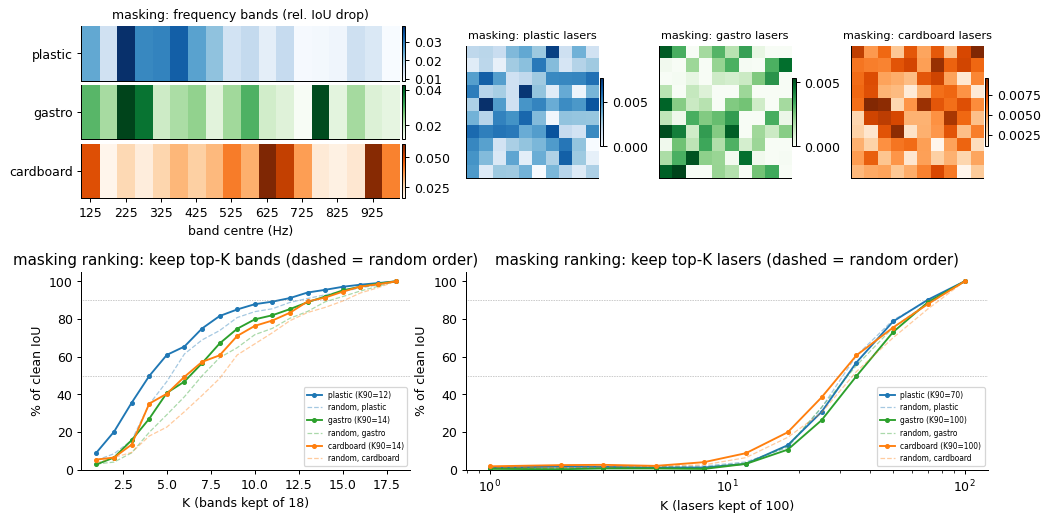

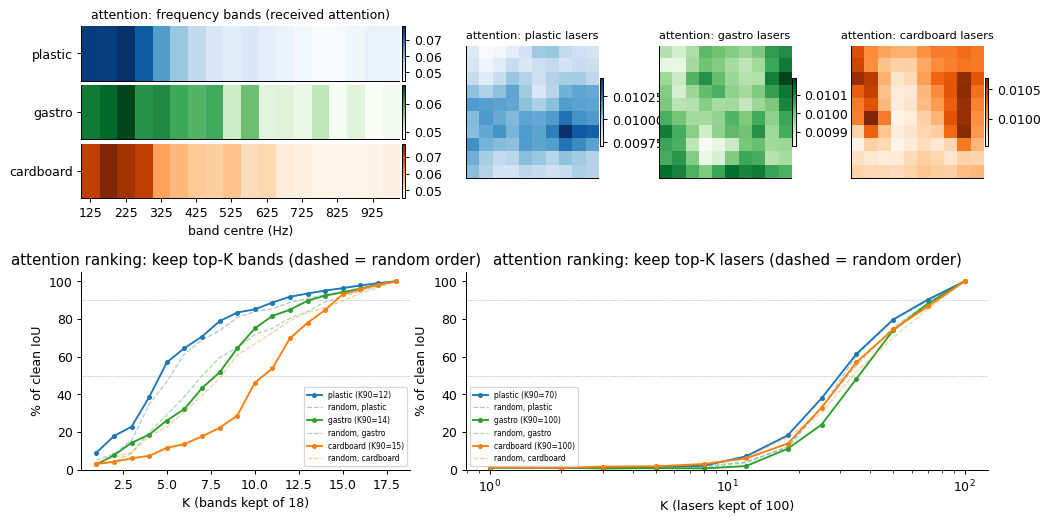

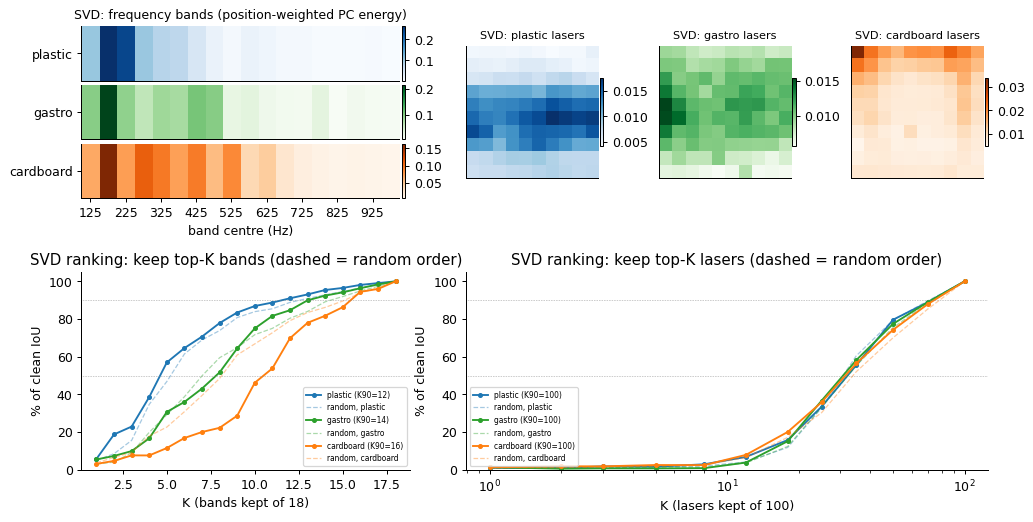

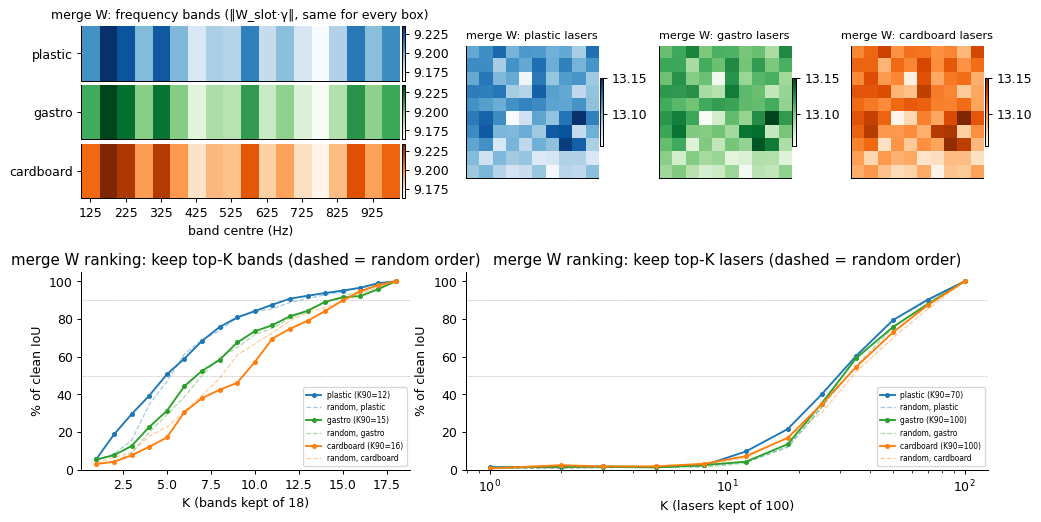

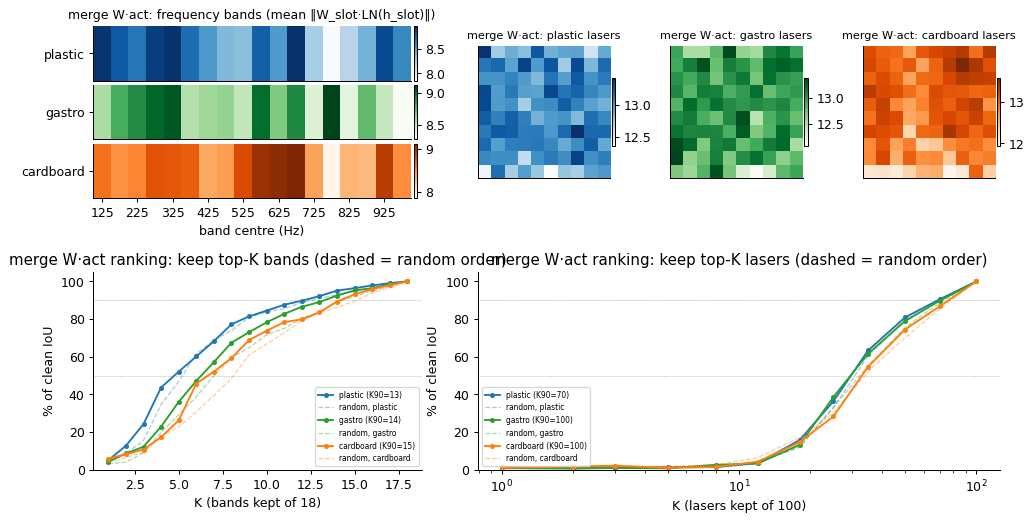

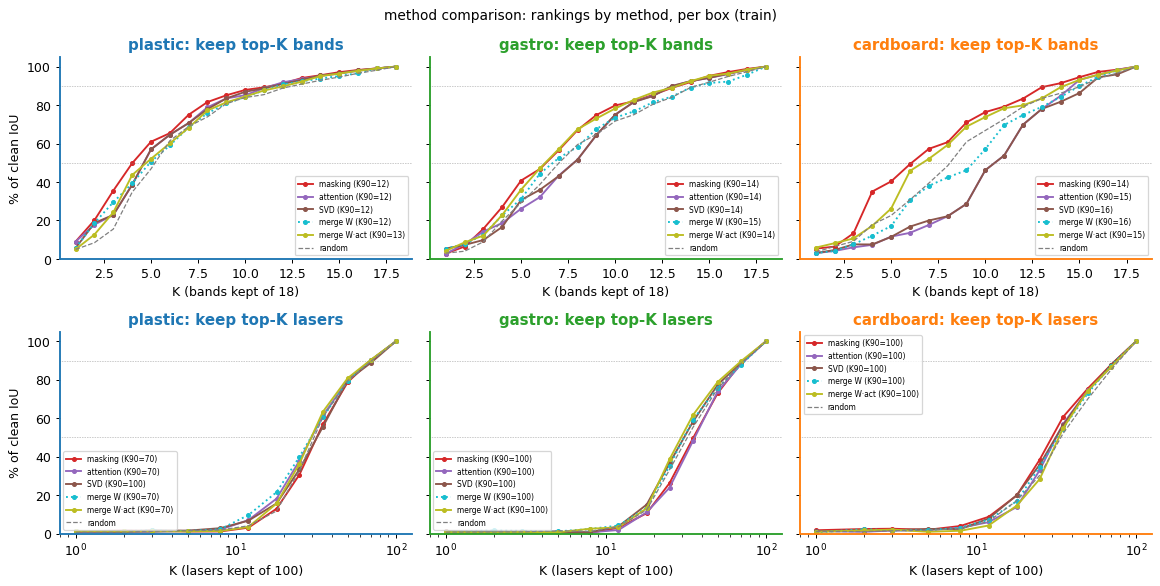

                        AUC                      K50                      K90               
box               cardboard gastro plastic cardboard gastro plastic cardboard gastro plastic
unit  ranking                                                                               
band  SVD             0.460  0.599   0.716        11      8       5        16     14      12
      attention       0.463  0.596   0.717        11      8       5        15     14      12
      masking         0.638  0.643   0.742         7      7       5        14     14      12
      merge W         0.527  0.604   0.704        10      7       5        16     15      12
      merge W·act     0.603  0.638   0.704         7      7       5        15     14      13
      random          0.560  0.590   0.681         9      8       6        16     15      13
laser SVD             0.327  0.320   0.323        35     35      35       100    100     100
      attention       0.316  0.293   0.334        35     50      35   

In [5]:
SRC.setdefault("q1", In[-1])   # keep this cell's source: Q1-eval re-runs it with SET = "eval"
if not (CACHE / f"q1_{SET}.npz").exists():   # scripts/nb136_set.py: subset720.npz + masking/attention indexed from q1_single.npz; heads, merge W·act, SVD, top-K, input views
    import subprocess; subprocess.run([sys.executable, "scripts/nb136_set.py", SET], check=True, cwd=ROOT)
Q = np.load(CACHE / f"q1_{SET}.npz")
BX = ["plastic", "gastro", "cardboard"]; qbox, KB, KL = Q["box"], Q["KB"], Q["KL"]
print(f"{SET} subset: single-object, object present, 60 per box × object (seed 0, drawn from q1_single.npz)"); print(pd.crosstab(qbox, Q["obj"], margins=True).reindex(BX + ["All"]).to_string())
c0 = {b: Q["clean"][qbox == b].mean() for b in BX}; print("clean IoU:", {b: round(float(c0[b]), 3) for b in BX}, "\n")
rel = lambda D, b: D[qbox == b].mean(0) / c0[b]                                 # relative IoU drop per unit, per box (D = clean − masked, per sample)
nrm = lambda v: v / v.sum()
IMP = {"masking": {"band": {b: rel(Q["mask_b"], b) for b in BX}, "laser": {b: rel(Q["mask_l"], b) for b in BX}},
       "attention": {"band": {b: Q["att_b"][qbox == b].mean(0) for b in BX}, "laser": {b: Q["att_l"][qbox == b].mean(0) for b in BX}},
       "SVD": {"band": {b: nrm(Q[f"imp_b|{b}"]) for b in BX}, "laser": {b: nrm(Q[f"imp_l|{b}"]) for b in BX}},
       "merge W": {"band": {b: Q["w_b"] for b in BX}, "laser": {b: Q["w_l"] for b in BX}},                       # ||W[:, slot]·γ_LN||, box-agnostic
       "merge W·act": {"band": {b: Q["c_b"][qbox == b].mean(0) for b in BX}, "laser": {b: Q["c_l"][qbox == b].mean(0) for b in BX}}}  # mean ||W_slot LN(h_slot)||
UNIT = {"masking": "rel. IoU drop", "attention": "received attention", "SVD": "position-weighted PC energy", "merge W": "‖W_slot·γ‖, same for every box", "merge W·act": "mean ‖W_slot·LN(h_slot)‖"}
RK = list(IMP)
cv = lambda b, u, r: Q[f"c|{b}|{u}|" + {"SVD": "svd", "merge W": "weight", "merge W·act": "contribution"}.get(r, r)]
rnd = lambda b, u: np.mean([Q[f"c|{b}|{u}|random{k}"] for k in range(3)], 0)
k90 = lambda c, Ks, b: next((f"K90={int(k)}" for k, v in zip(Ks, c / c0[b]) if v >= .9), f"K90>{Ks[-1]}")  # first K reaching 90% of clean IoU
for nm, dd in IMP.items():   # one block per method: band heatmap | laser maps, then top-K bands | top-K lasers (all boxes, box hues)
    fig = plt.figure(figsize=(13, 6.4)); gs = fig.add_gridspec(2, 4, width_ratios=[2.4, 1, 1, 1], height_ratios=[1, 1.15], hspace=.4, wspace=.3)
    sg = gs[0, 0].subgridspec(3, 1, hspace=.08)
    for j, b in enumerate(BX):
        a = fig.add_subplot(sg[j]); heat(a, dd["band"][b], b); a.set_yticks([0], [b]); a.set_xticks([])
        if j == 0: a.set_title(f"{nm}: frequency bands ({UNIT[nm]})", fontsize=10)
    a.set_xticks(range(0, 18, 2), [f"{HZ[k]:.0f}" for k in range(0, 18, 2)]); a.set_xlabel("band centre (Hz)")
    for j, b in enumerate(BX):
        a = fig.add_subplot(gs[0, j + 1]); heat(a, dd["laser"][b].reshape(10, 10), b); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([]); a.set_title(f"{nm}: {b} lasers", fontsize=9)
    for a, u, Ks in ((fig.add_subplot(gs[1, 0]), "band", KB), (fig.add_subplot(gs[1, 1:]), "laser", KL)):
        for b in BX:
            a.plot(Ks, 100 * cv(b, u, nm) / c0[b], "o-", ms=3, c=BOXC[b], label=f"{b} ({k90(cv(b, u, nm), Ks, b)})")
            a.plot(Ks, 100 * rnd(b, u) / c0[b], "--", lw=1, c=BOXC[b], alpha=.4, label=f"random, {b}")
        a.axhline(50, c="gray", lw=.5, ls=":"); a.axhline(90, c="gray", lw=.5, ls=":")
        a.set(title=f"{nm} ranking: keep top-K {u}s (dashed = random order)", xlabel=f"K ({u}s kept of {Ks[-1]})", ylabel="% of clean IoU", xscale="log" if u == "laser" else "linear", ylim=(0, 105))
        a.legend(fontsize=6)
    plt.show()

MC = {"masking": "tab:red", "attention": "tab:purple", "SVD": "tab:brown", "merge W": "tab:cyan", "merge W·act": "tab:olive"}   # method comparison: lines by method
fig, ax = plt.subplots(2, 3, figsize=(13, 6.6), sharey=True)
for i, (u, Ks) in enumerate((("band", KB), ("laser", KL))):
    for j, b in enumerate(BX):
        a = ax[i, j]
        for r in RK: a.plot(Ks, 100 * cv(b, u, r) / c0[b], "o-" if r != "merge W" else "o:", ms=3, c=MC[r], label=f"{r} ({k90(cv(b, u, r), Ks, b)})")
        a.plot(Ks, 100 * rnd(b, u) / c0[b], "--", c="gray", lw=1, label="random")
        a.legend(fontsize=6)
        a.axhline(50, c="gray", lw=.5, ls=":"); a.axhline(90, c="gray", lw=.5, ls=":")
        a.set(xlabel=f"K ({u}s kept of {Ks[-1]})", xscale="log" if u == "laser" else "linear", ylim=(0, 105)); a.set_title(f"{b}: keep top-K {u}s", color=BOXC[b], fontweight="bold")
        for sp in a.spines.values(): sp.set_edgecolor(BOXC[b]); sp.set_linewidth(1.5)
    ax[i, 0].set_ylabel("% of clean IoU")
plt.suptitle(f"method comparison: rankings by method, per box ({SET})", fontsize=11); plt.tight_layout(); plt.show()

def kneed(c, Ks, c0, f): return int(Ks[np.argmax(c / c0 >= f)]) if (c / c0 >= f).any() else None
rows = []
for b in BX:
    for u, Ks in (("band", KB), ("laser", KL)):
        for r in RK + ["random"]:
            c = cv(b, u, r) if r != "random" else rnd(b, u)
            rows.append(dict(box=b, unit=u, ranking=r, K50=kneed(c, Ks, c0[b], .5), K90=kneed(c, Ks, c0[b], .9), AUC=round(float(np.mean(c / c0[b])), 3)))
print(pd.DataFrame(rows).pivot_table(index=["unit", "ranking"], columns="box", values=["K50", "K90", "AUC"], aggfunc="first").to_string())
PAIRS = [(p, q) for i, p in enumerate(RK) for q in RK[i + 1:]]
print(f"\nSpearman ρ between rankings (all on the same {SET} samples):")
print(pd.DataFrame({(u, b): {f"{p} ~ {q}": stats.spearmanr(IMP[p][u][b], IMP[q][u][b])[0] for p, q in PAIRS} for u in ("band", "laser") for b in BX}).round(2).to_string())
print("peak band (Hz) per box:", {nm: {b: int(HZ[np.argmax(dd["band"][b])]) for b in BX} for nm, dd in IMP.items()})
print("importance-weighted mean band freq (Hz):", {nm: {b: int((dd["band"][b].clip(0) * HZ).sum() / dd["band"][b].clip(0).sum()) for b in BX} for nm, dd in IMP.items()})
print("largest single unit, rel. IoU drop:", {b: (round(float(IMP["masking"]["band"][b].max()), 3), round(float(IMP["masking"]["laser"][b].max()), 4)) for b in BX})


### Q1b · Input-signal band profiles
Five views of the input on the same 18 × 50 Hz band axis, on the same `SET` samples, one row of panels per box. Each title carries **r = Pearson r with that box's masking band importance**.
- **Vibration (normalised):** per-band mean of |X| / σ_sample, the model's input before its mean shift (`transformer4.py:139` z-scores each sample over all lasers, bins and both axes together, so this equals the z-score plus a per-sample constant). The dataset already stores |X| / σ_sample, so there is no separate raw-magnitude view.
- **Level (dB):** 20·log10 of the above.
- **Resonance density (%):** relaxed nb109 §12 rule (savgol σ(f), prominence ≥ 2 × MAD of the residual from a 60 Hz baseline, present in ≥ 50% of the captures of an (object, speaker) group). Share of the box's resonances in each band.
- **Peaks / sample:** relaxed peaks per capture, no presence rule.
- **Position sensitivity:** the best of the variants in the table, scored by mean r over boxes. Variants: σ_pos / σ_empty on dB, linear v or the z-scored encoder input, per laser or on the laser mean (σ_pos = std over captures within (object, speaker), each at its own position; σ_empty = std over the set's empty-box captures within speaker); the Fisher ratio between-position variance / repeat variance (no capture is repeated at one position, so the repeat variance is the empty-box variance within speaker); a single-band linear probe R² from that band's 100 laser levels to the CoM (5-fold, grouped by position); and neighbour-position |Δspectrum| / repeat |Δ| (nearest-CoM capture of the same object and speaker vs pairs of empty captures). **Picking the max r over 9 variants on the same samples is optimistic.**

position sensitivity variants: Pearson r with masking band importance (max over 9 variants is optimistic: selected on these samples)
                                              plastic  gastro  cardboard  mean
single-band linear probe R² → (x, y)             0.58   -0.02       0.09  0.21
σ_pos/σ_empty, dB, per-laser                    -0.12    0.01       0.21  0.03
Fisher ratio (between-pos / repeat var), dB     -0.17   -0.03       0.24  0.02
σ_pos/σ_empty, linear v, per-laser              -0.22   -0.02       0.20 -0.01
σ_pos/σ_empty, z (encoder input), per-laser     -0.06    0.14      -0.26 -0.06
neighbour |Δ| / repeat |Δ|, dB                  -0.09   -0.09       0.01 -0.06
σ_pos/σ_empty, linear v, laser-mean             -0.38   -0.10       0.20 -0.10
σ_pos/σ_empty, dB, laser-mean                   -0.41   -0.07       0.10 -0.13
σ_pos/σ_empty, z (encoder input), laser-mean    -0.19    0.11      -0.37 -0.15


/tmp/ipykernel_2548919/419652244.py:52: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  VT = pd.DataFrame({b: {k: pr(v[b], b) for k, v in POSV.items()} for b in BX}); VT["mean"] = VT.mean(1)


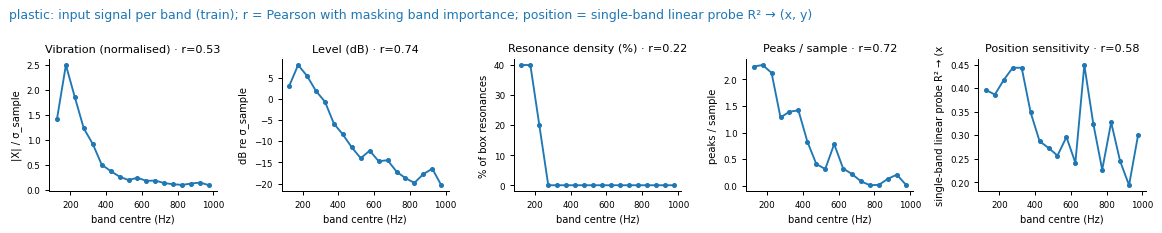

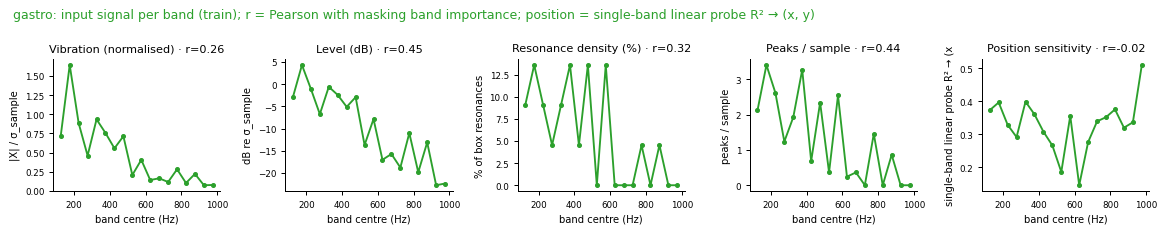

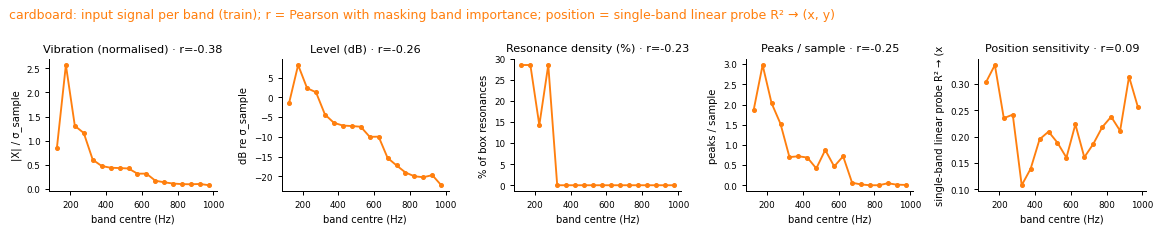

box resonances, relaxed (Hz): {'plastic': [113, 140, 155, 195, 213], 'gastro': [124, 134, 150, 172, 184, 222, 247, 271, 309, 321, 364, 384, 398, 432, 453, 473, 495, 565, 577, 595, 784, 862], 'cardboard': [114, 140, 159, 173, 236, 260, 285]}
peaks per sample, total and share above 500 Hz: {'plastic': (np.float64(14.1), '15%'), 'gastro': (np.float64(23.4), '25%'), 'cardboard': (np.float64(13.1), '17%')}
empty captures used for σ_empty: {'plastic': 60, 'gastro': 36, 'cardboard': 73}
Pearson r of each input view with each importance view (bands):
                       plastic                                      gastro                                     cardboard                                    
                       masking attention   SVD merge W merge W·act masking attention   SVD merge W merge W·act   masking attention   SVD merge W merge W·act
Vibration (normalised)    0.53      0.95  0.97    0.67        0.47    0.26      0.87  0.96    0.62        0.34     -0.38      0.91  0.85 

In [6]:
SRC.setdefault("q1b", In[-1])
from scipy.signal import savgol_filter, find_peaks
from scipy.ndimage import maximum_filter1d
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold, cross_val_predict
VB, SIG, BIN = Q["vb"].astype(np.float64), Q["sigma"], np.arange(1170) // 65      # (n,100,18) per-laser band mean of v = |X|/σ_sample; σ(f) (n,1170); band of each bin
EVB, ebox, espk = Q["emp_vb"].astype(np.float64), Q["emp_box"], Q["emp_spk"]      # the set's empty-box captures (σ_empty, repeat noise)
qobj, qspk, qpos, qcom = Q["obj"], Q["spk"], Q["pos"], Q["com"]
def peaks(sig, k_prom=2., baseline_hz=60., distance_hz=5., smooth_hz=5.):    # nb109 §12 / viz2 rule, relaxed defaults: savgol σ(f), prominence ≥ k × MAD of the residual from a baseline
    nb = lambda hz: max(1, int(round(hz * 1.3))); odd = lambda n: n + 1 - n % 2
    sig = savgol_filter(sig, odd(2 * nb(smooth_hz) + 1), 3); r = sig - savgol_filter(sig, odd(2 * nb(baseline_hz) + 1), 3)
    return find_peaks(sig, distance=nb(distance_hz), prominence=max(1e-12, k_prom * 1.4826 * np.median(np.abs(r - np.median(r)))), wlen=odd(2 * nb(baseline_hz) + 1))[0]
RES, CNT = {}, {}
for b in BX:
    O, Sg, n = [], [], []
    for o in np.unique(qobj):
        for s in np.unique(qspk):
            g = (qbox == b) & (qobj == o) & (qspk == s)
            if g.sum() < 3: continue
            pk = [peaks(x) for x in SIG[g]]; hit = np.zeros(SIG[g].shape, np.uint8)
            for i, p in enumerate(pk): hit[i, p] = 1
            O.append(maximum_filter1d(hit, 7, axis=1).mean(0)); Sg.append(SIG[g].mean(0)); n.append(np.mean([np.bincount(BIN[p], minlength=18) for p in pk], 0))
    occ = np.mean(O, 0); RES[b] = np.array([k for k in peaks(np.mean(Sg, 0)) if occ[k] >= .5]); CNT[b] = np.mean(n, 0)   # resonances: in ≥ 50% of captures per (object, speaker)

# position sensitivity variants (per band): groups = (object, speaker) within a box, every capture at its own position; empties grouped by speaker
FEAT = {"dB": lambda v: 20 * np.log10(v), "linear v": lambda v: v, "z (encoder input)": lambda v: v - v.mean((1, 2), keepdims=True)}
def grp_sd(F, m, keys, lmean):  # std over captures within each group, mean over groups (and lasers)
    F = F.mean(1, keepdims=True) if lmean else F
    return np.mean([F[m & (keys == k)].std(0).mean(0) for k in np.unique(keys[m]) if (m & (keys == k)).sum() >= 3], 0)
gkey, POSV = np.array([f"{o}|{s}" for o, s in zip(qobj, qspk)]), {}
for fn, f in FEAT.items():
    for lm, ln in ((False, "per-laser"), (True, "laser-mean")):
        POSV[f"σ_pos/σ_empty, {fn}, {ln}"] = {b: grp_sd(f(VB), qbox == b, gkey, lm) / grp_sd(f(EVB), ebox == b, espk, lm) for b in BX}
def fisher(b):  # between-position var / repeat var per (laser, band), dB; no capture is repeated at one position, so repeat var = empty-box var within speaker
    F, E = FEAT["dB"](VB), FEAT["dB"](EVB)
    vb_ = np.mean([F[(qbox == b) & (gkey == k)].var(0) for k in np.unique(gkey[qbox == b])], 0); ve = np.mean([E[(ebox == b) & (espk == s)].var(0) for s in np.unique(espk[ebox == b])], 0)
    return (vb_ / ve).mean(0)
POSV["Fisher ratio (between-pos / repeat var), dB"] = {b: fisher(b) for b in BX}
def probe(b):  # single-band linear probe: ridge from the 100 lasers' dB in that band -> CoM (row, col), 5-fold grouped by position, R²
    m = qbox == b; F, yy, g = FEAT["dB"](VB[m]), qcom[m], qpos[m]
    return np.array([1 - ((cross_val_predict(RidgeCV(alphas=np.logspace(-1, 4, 6)), F[:, :, k], yy, groups=g, cv=GroupKFold(5)) - yy) ** 2).sum() / ((yy - yy.mean(0)) ** 2).sum() for k in range(18)])
POSV["single-band linear probe R² → (x, y)"] = {b: probe(b) for b in BX}
def neigh(b):  # |Δ dB| to the nearest-position capture of the same (object, speaker) / |Δ dB| between empty captures of one speaker
    F, E, d = FEAT["dB"](VB), FEAT["dB"](EVB), []
    for k in np.unique(gkey[qbox == b]):
        ix = np.nonzero((qbox == b) & (gkey == k))[0]; D = np.linalg.norm(qcom[ix, None] - qcom[None, ix], axis=2) + np.eye(len(ix)) * 1e9
        d += [np.abs(F[i] - F[ix[D[a].argmin()]]).mean(0) for a, i in enumerate(ix)]
    rep = [np.abs(E[i] - E[j]).mean(0) for s in np.unique(espk[ebox == b]) for i, j in __import__("itertools").combinations(np.nonzero((ebox == b) & (espk == s))[0], 2)]
    return np.mean(d, 0) / np.mean(rep, 0)
POSV["neighbour |Δ| / repeat |Δ|, dB"] = {b: neigh(b) for b in BX}
pr = lambda v, b: stats.pearsonr(v, IMP["masking"]["band"][b])[0]
VT = pd.DataFrame({b: {k: pr(v[b], b) for k, v in POSV.items()} for b in BX}); VT["mean"] = VT.mean(1)
print("position sensitivity variants: Pearson r with masking band importance (max over 9 variants is optimistic: selected on these samples)"); print(VT.round(2).sort_values("mean", ascending=False).to_string())
BEST = VT["mean"].idxmax()

mvb = {b: VB[qbox == b].mean((0, 1)) for b in BX}                             # per-band mean of |X|/σ_sample
REF = {"Vibration (normalised)": ({b: mvb[b] for b in BX}, "|X| / σ_sample"),
       "Level (dB)": ({b: 20 * np.log10(mvb[b]) for b in BX}, "dB re σ_sample"),
       "Resonance density (%)": ({b: 100 * np.bincount(BIN[RES[b]], minlength=18) / max(len(RES[b]), 1) for b in BX}, "% of box resonances"),
       "Peaks / sample": ({b: CNT[b] for b in BX}, "peaks / sample"),
       "Position sensitivity": ({b: POSV[BEST][b] for b in BX}, BEST.split(",")[0])}
for b in BX:   # one row per box: the 5 input views on the band axis
    fig, ax = plt.subplots(1, 5, figsize=(13, 2.6))
    for a, (nm, (v, un)) in zip(ax, REF.items()):
        a.plot(HZ, v[b], "o-", ms=3, c=BOXC[b]); a.set_title(f"{nm} · r={pr(v[b], b):.2f}", fontsize=9); a.set_ylabel(un, fontsize=8); a.set_xlabel("band centre (Hz)", fontsize=8); a.tick_params(labelsize=7)
    fig.suptitle(f"{b}: input signal per band ({SET}); r = Pearson with masking band importance; position = {BEST}", x=.01, ha="left", fontsize=10, color=BOXC[b]); plt.tight_layout(); plt.show()
print("box resonances, relaxed (Hz):", {b: [int(FHZ[k]) for k in RES[b]] for b in BX})
print("peaks per sample, total and share above 500 Hz:", {b: (round(CNT[b].sum(), 1), f"{CNT[b][HZ > 500].sum() / CNT[b].sum():.0%}") for b in BX})
print("empty captures used for σ_empty:", {b: int((ebox == b).sum()) for b in BX})
print("Pearson r of each input view with each importance view (bands):")
print(pd.DataFrame({(b, r): {nm: stats.pearsonr(v[b], IMP[r]["band"][b])[0] for nm, (v, _) in REF.items()} for b in BX for r in IMP}).round(2).to_string())


### Q1b′ · Input views vs **attention**
Same band strips as Q1b, but each panel title gives Pearson r with that box's **attention** band score (Q1, mean received attention), not masking. The second number, *detr*, is r after removing a quadratic trend in frequency from both curves. Every input view falls smoothly with frequency, so a raw r over 18 bands is easy to get, and the detrended r is the stricter test. The dashed black line (right axis) is the box's attention, normalised to sum 1.

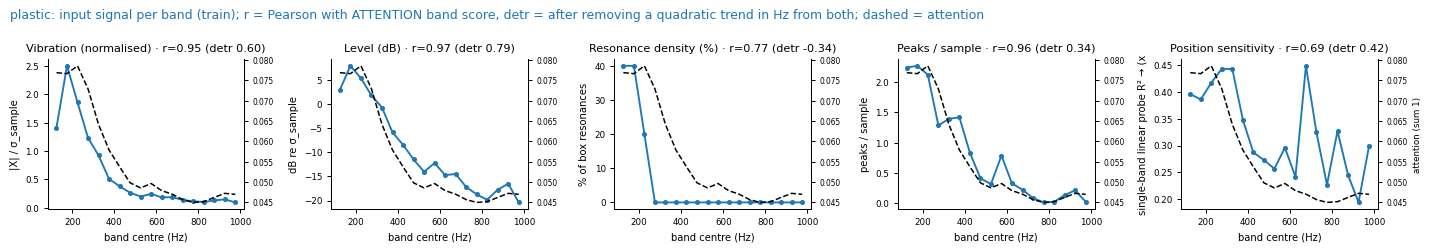

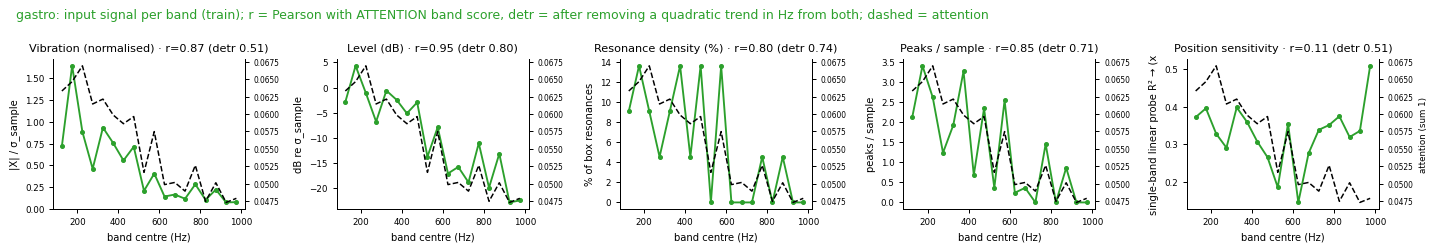

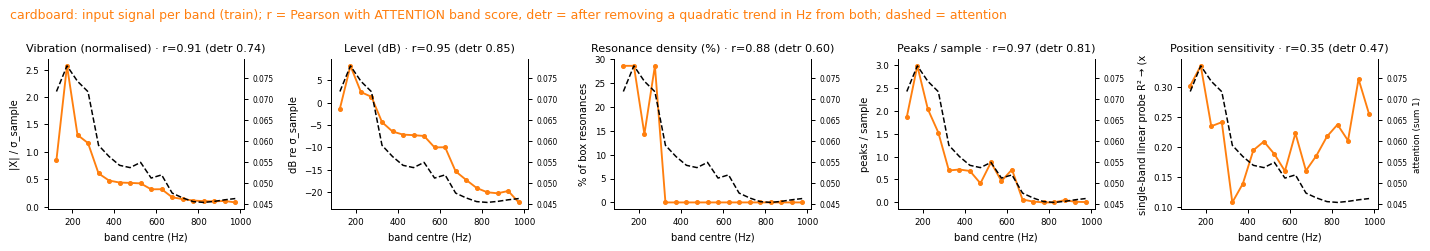

Pearson r of attention with each input view, raw (detrended quadratic):
                             plastic       gastro    cardboard
Vibration (normalised)   0.95 (0.60)  0.87 (0.51)  0.91 (0.74)
Level (dB)               0.97 (0.79)  0.95 (0.80)  0.95 (0.85)
Resonance density (%)   0.77 (-0.34)  0.80 (0.74)  0.88 (0.60)
Peaks / sample           0.96 (0.34)  0.85 (0.71)  0.97 (0.81)
Position sensitivity     0.69 (0.42)  0.11 (0.51)  0.35 (0.47)


In [7]:
q1b_att = {b: IMP["attention"]["band"][b] / IMP["attention"]["band"][b].sum() for b in BX}   # attention band score, sums to 1 per box
q1b_f = (HZ - 550) / 450
q1b_dt = lambda y: y - np.polyval(np.polyfit(q1b_f, y, 2), q1b_f)                          # remove a quadratic trend in frequency
q1b_r = lambda v, b: (stats.pearsonr(v, q1b_att[b])[0], stats.pearsonr(q1b_dt(v), q1b_dt(q1b_att[b]))[0])
q1b_R = {}
for b in BX:   # one row per box: the 5 input views (box colour) with attention overlaid (dashed black, right axis)
    fig, ax = plt.subplots(1, 5, figsize=(16, 2.8))
    for a, (nm, (v, un)) in zip(ax, REF.items()):
        r, rd = q1b_r(v[b], b); q1b_R[b, nm] = (r, rd)
        a.plot(HZ, v[b], "o-", ms=3, c=BOXC[b]); a.set_ylabel(un, fontsize=8); a.set_xlabel("band centre (Hz)", fontsize=8); a.tick_params(labelsize=7)
        t = a.twinx(); t.plot(HZ, q1b_att[b], "--", c="k", lw=1.2); t.spines["right"].set_visible(True); t.tick_params(labelsize=6)
        if nm == list(REF)[-1]: t.set_ylabel("attention (sum 1)", fontsize=7)
        a.set_title(f"{nm} · r={r:.2f} (detr {rd:.2f})", fontsize=9)
    fig.suptitle(f"{b}: input signal per band ({SET}); r = Pearson with ATTENTION band score, detr = after removing a quadratic trend in Hz from both; dashed = attention",
                 x=.01, ha="left", fontsize=10, color=BOXC[b]); plt.tight_layout(); plt.show()
print("Pearson r of attention with each input view, raw (detrended quadratic):")
print(pd.DataFrame({b: {nm: f"{q1b_R[b, nm][0]:.2f} ({q1b_R[b, nm][1]:.2f})" for nm in REF} for b in BX}).to_string())

### Q1b″ · Input views as band heatmaps, next to attention
The same five input views drawn the same way as the Q1 frequency-band heatmaps: one single-row heatmap per box, with the box colormap. The bottom row is the Q1 attention band score. Columns are boxes. `heat()` stretches every row to its **own** min–max, as in Q1, so a nearly flat row looks as contrasted as a strongly peaked one. Each row's label therefore gives its actual range.
- Linear rows show `min–max (×max/min)`.
- Level (dB) shows the span in dB. It is drawn relative to its own minimum, because the dB zero (re σ_sample) is arbitrary and `heat()` would otherwise clip negative dB to 0.
- Rows with negative values (e.g. probe R² < 0) are clipped at 0 by `heat()`, and the label counts how many bands were clipped.

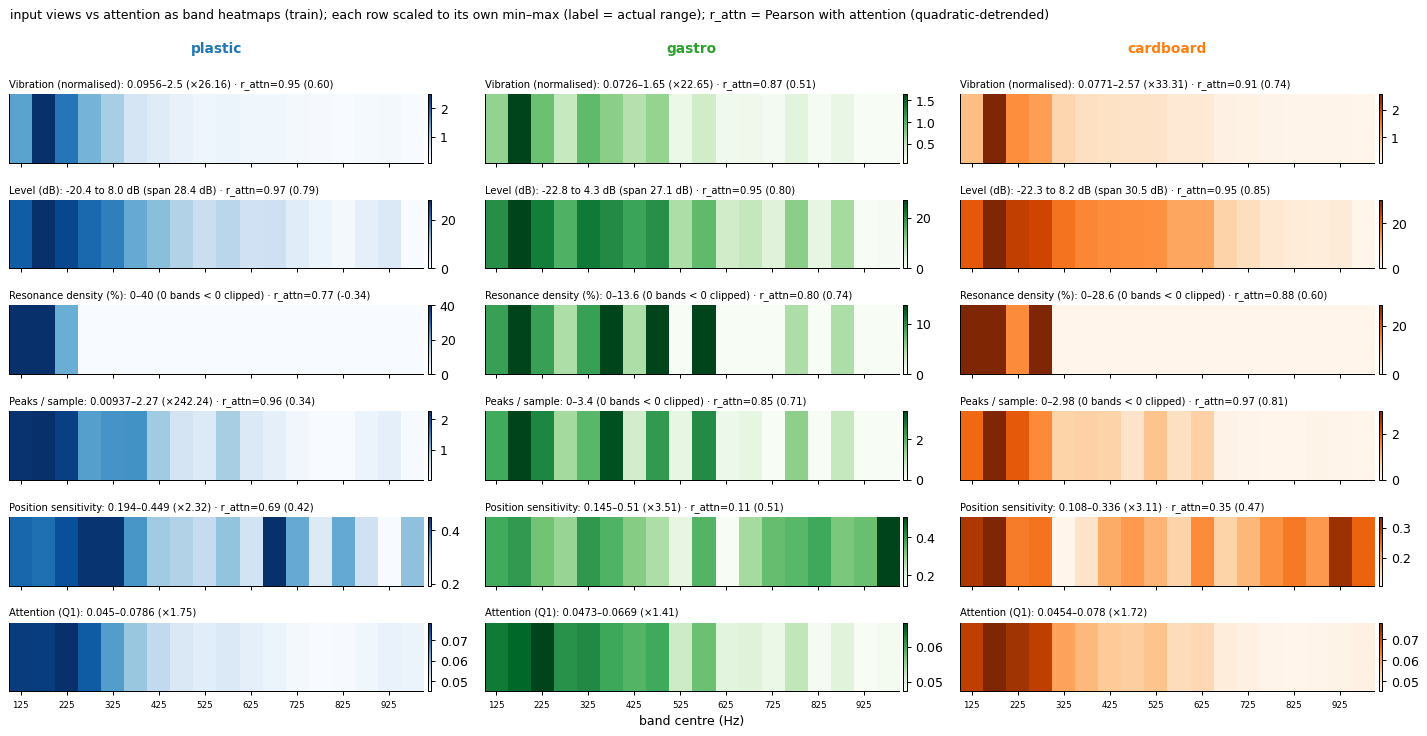

In [8]:
q1b_rows = {nm: v for nm, (v, _) in REF.items()} | {"Attention (Q1)": q1b_att}
fig, ax = plt.subplots(len(q1b_rows), 3, figsize=(16, 1.25 * len(q1b_rows) + .8))
for i, (nm, v) in enumerate(q1b_rows.items()):
    for j, b in enumerate(BX):
        a, x = ax[i, j], np.asarray(v[b], float); lo, hi = x.min(), x.max()
        if nm == "Level (dB)": heat(a, x - lo, b); lab = f"{lo:.1f} to {hi:.1f} dB (span {hi - lo:.1f} dB)"
        else:
            heat(a, x, b); lab = f"{lo:.3g}–{hi:.3g}" + (f" (×{hi / lo:.2f})" if lo > 0 else f" ({(x < 0).sum()} bands < 0 clipped)")
        if nm != "Attention (Q1)": lab += f" · r_attn={q1b_R[b, nm][0]:.2f} ({q1b_R[b, nm][1]:.2f})"
        a.set_yticks([]); a.set_title(f"{nm}: {lab}", fontsize=8, loc="left")
        a.set_xticks(range(0, 18, 2), [f"{HZ[k]:.0f}" for k in range(0, 18, 2)] if i == len(q1b_rows) - 1 else [], fontsize=7)
        if i == 0: a.text(.5, 1.6, b, transform=a.transAxes, ha="center", fontsize=11, fontweight="bold", color=BOXC[b])
    ax[-1, 1].set_xlabel("band centre (Hz)")
fig.suptitle(f"input views vs attention as band heatmaps ({SET}); each row scaled to its own min–max (label = actual range); r_attn = Pearson with attention (quadratic-detrended)", x=.01, ha="left", fontsize=10)
plt.tight_layout(); plt.show()

**Answer** (SET = train, 720 single-object samples, 240 per box). **Train IoU is near ceiling**: clean IoU .93 / .91 / .91 (plastic / gastro / cardboard), so these rankings describe the memorised regime, and the top-K curves grade each ranking on the samples that built it.

**No single unit matters much.** The largest single band costs 3.8 / 4.3 / 6.1% of clean IoU, the largest single laser ≤ 1.0%.

**Which bands**
- **Masking** peaks at 224 Hz in plastic and gastro and at 625 Hz in cardboard. Importance-weighted mean band frequency 463 / 508 / 576 Hz: cardboard sits highest, as before.
- **Attention and SVD** put the mass on the loud 125–275 Hz bands in every box (peaks 174–224 Hz, SVD weighted means 273 / 348 / 375 Hz). They agree with each other (ρ .94 / .90 / .90). Masking ~ attention ρ is .81 / .62 / −.11, masking ~ SVD .76 / .53 / −.27: they agree where use and loudness coincide (plastic, partly gastro) and not in cardboard.
- **Merge W** is box-agnostic and nearly flat (weighted mean 549 Hz). **Merge W·act** is also flat (545–548 Hz) but is the view closest to masking in cardboard (ρ .64; .54 / .62 in plastic / gastro).

**Top-K bands** (K90 = bands kept for 90% of clean IoU; random 13 / 15 / 16)
- Masking: K90 12 / 14 / 14, AUC .74 / .64 / .64 (random .68 / .59 / .56). Best in every box, but by only 1–2 bands, even though it is graded on its own samples.
- Attention / SVD: K90 12 / 14 / 15–16; in cardboard both are **worse than random** (AUC .46 vs .56): keeping the loud low bands first discards what cardboard uses.
- Merge W·act: K90 13 / 14 / 15, AUC .70 / .64 / .60. Merge W: K90 12 / 15 / 16, ≈ random.
- Even the best ranking needs 5–7 bands for half the IoU: the information is spread over many bands.

**Lasers.** No ranking beats random. K50 35–50 and K90 70–100 everywhere (random 35 and 100 / 100 / 100), AUC .29–.34 for every method vs random .31–.32. Laser rankings barely agree with masking (|ρ| ≤ .37). The array is used as a redundant set.

**Q1b · input views vs masking** (Pearson r, plastic / gastro / cardboard)
- Vibration (normalised) .53 / .26 / −.38; Level (dB) .74 / .45 / −.26; Resonance density .22 / .32 / −.23; Peaks / sample .72 / .44 / −.25. The input views follow loudness, so they track attention (r .85–.97) and SVD (.76–.97) in every box, and masking only in plastic (and weakly gastro). In cardboard every loudness view is *anti*-correlated with use.
- **Position sensitivity.** Of 9 variants, the single-band linear probe R² → (x, y) has the best mean r: .58 / −.02 / .09. Every σ_pos / σ_empty variant (dB, linear v, encoder z; per laser or laser mean), the Fisher ratio and the neighbour / repeat ratio sit at |r| ≤ .41 with inconsistent signs; their best cardboard r is .24 (Fisher). Taking the max over 9 variants on the same samples is optimistic, so even .58 in plastic is an upper bound. On train, band position information does not explain cardboard's high-band use.
- Relaxed resonances: plastic 5 (113–213 Hz), gastro 22 (up to 862 Hz), cardboard 7 (≤ 285 Hz). Peaks per sample 14.1 / 23.4 / 13.1, 15 / 25 / 17% above 500 Hz. Plastic has no high-frequency resonances, and its masking peak is low (224 Hz).

Conclusion: attention, SVD and the input views measure loudness. They match use only where use is loud (plastic). Use masking for attribution.

## Q1c · Does averaging attention hide structure?
Q1 averaged attention over layers, heads and queries. Here the same received attention is kept **separately for every (layer, head)**: freq encoder 4 layers × 8 heads over 18 band tokens, laser encoder 8 × 8 over 100 laser tokens, plus the full query → key band maps and whole-head ablations (one head's output set to 0). Eager fp32, same `SET` samples as Q1 (`heads_{SET}.npz`). Agreement with masking is measured on the same samples, so it describes this set rather than generalisation. ρ maps use a diverging map (−1 … 1); importance maps use the box colormaps.

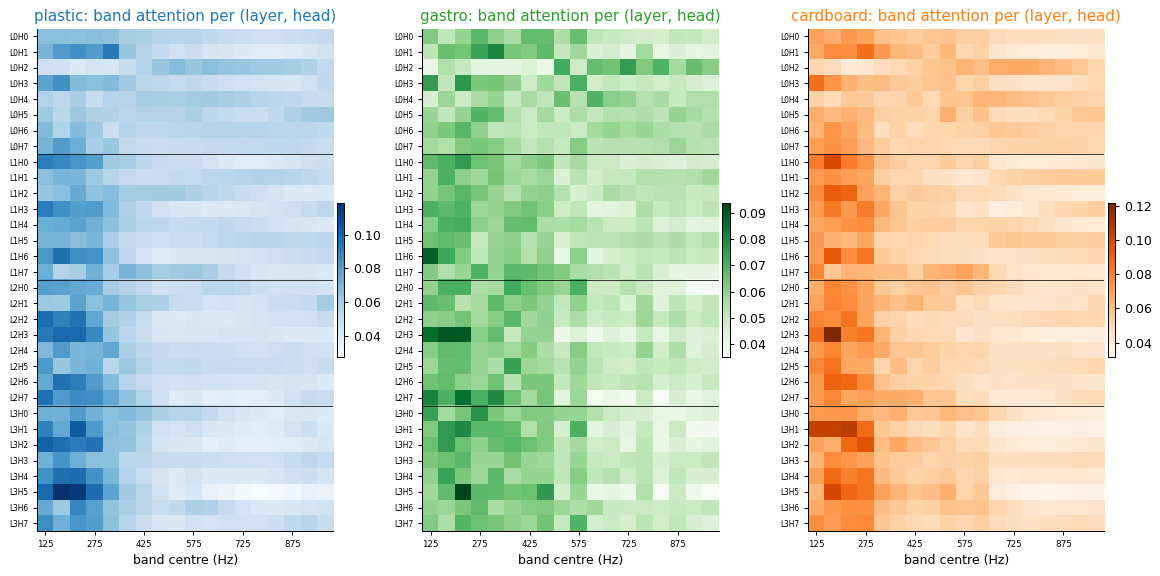

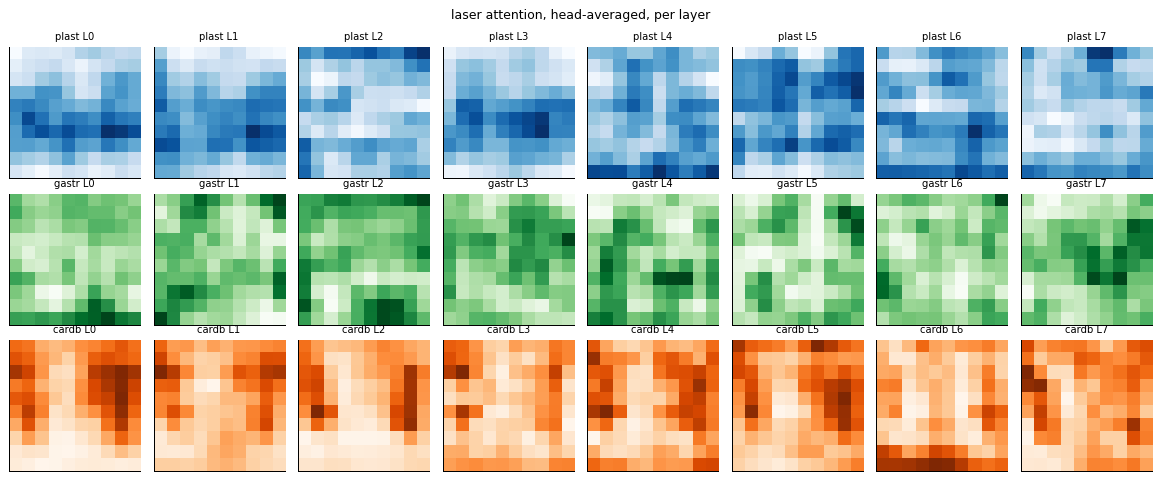

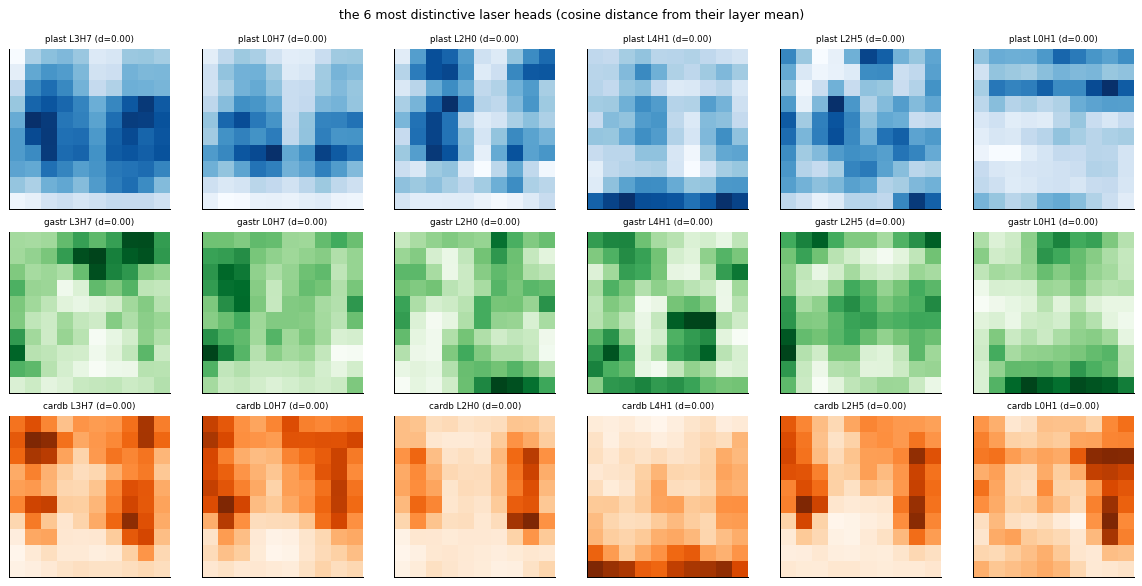

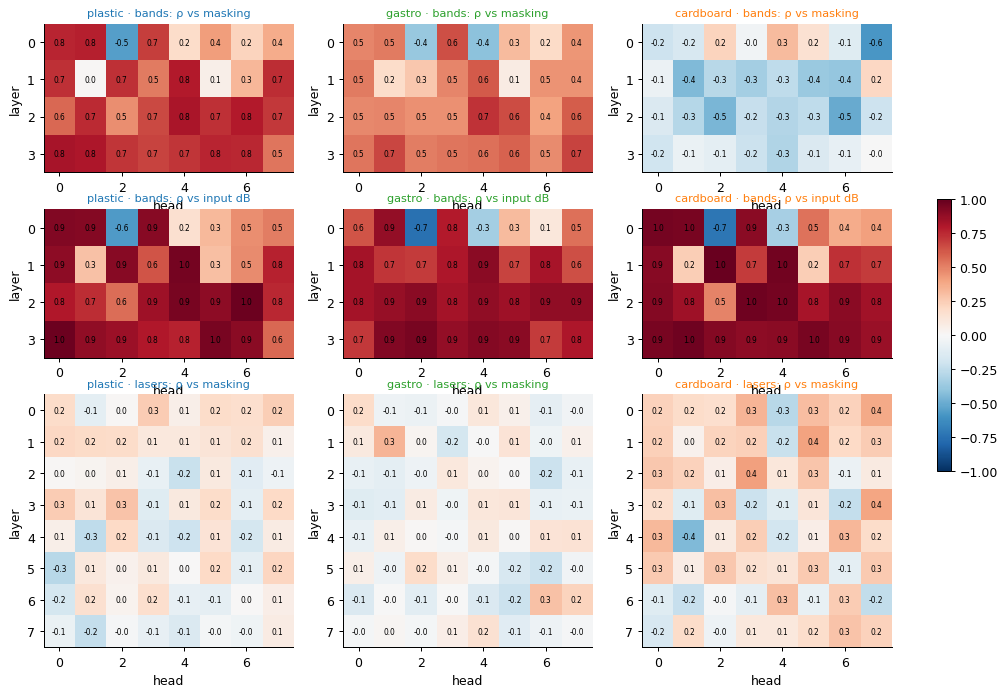

band ρ vs masking — head-averaged: {'plastic': np.float64(0.81), 'gastro': np.float64(0.62), 'cardboard': np.float64(-0.11)} | best head: {'plastic': ('L3H0', np.float64(0.82)), 'gastro': ('L2H4', np.float64(0.72)), 'cardboard': ('L0H4', np.float64(0.32))} | mean over heads: {'plastic': np.float64(0.56), 'gastro': np.float64(0.43), 'cardboard': np.float64(-0.18)}
band ρ vs input dB per head: median {'plastic': np.float64(0.8), 'gastro': np.float64(0.83), 'cardboard': np.float64(0.9)} | share of heads with ρ_dB > .8: {'plastic': np.float64(0.5), 'gastro': np.float64(0.59), 'cardboard': np.float64(0.66)}
laser ρ vs masking: max {'plastic': np.float64(0.29), 'gastro': np.float64(0.34), 'cardboard': np.float64(0.41)} | mean {'plastic': np.float64(0.04), 'gastro': np.float64(0.0), 'cardboard': np.float64(0.11)}


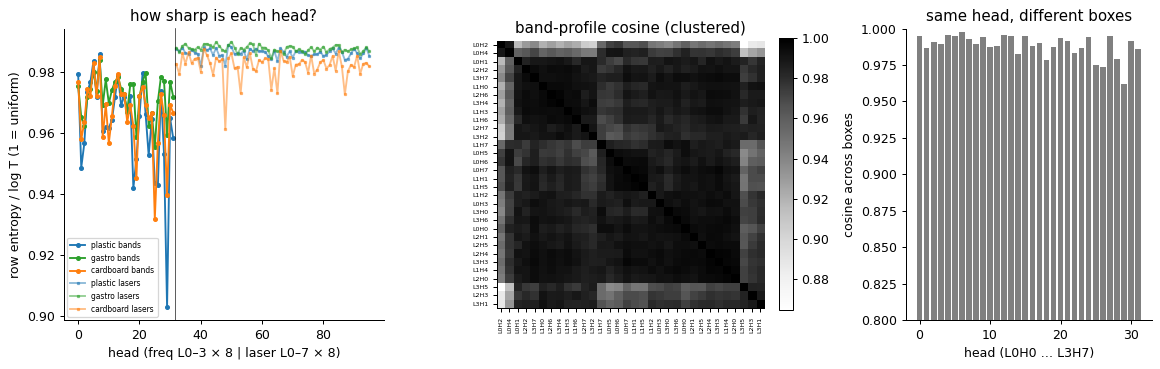

band entropy (mean, min): {'plastic': (np.float32(0.963), np.float32(0.903)), 'gastro': (np.float32(0.972), np.float32(0.955)), 'cardboard': (np.float32(0.966), np.float32(0.932))} | laser entropy (mean, min): {'plastic': (np.float32(0.986), np.float32(0.982)), 'gastro': (np.float32(0.987), np.float32(0.984)), 'cardboard': (np.float32(0.982), np.float32(0.961))}
clusters (4): [ 0  2 27  2  1] | head band-profile cosine across boxes: min 0.962 median 0.99


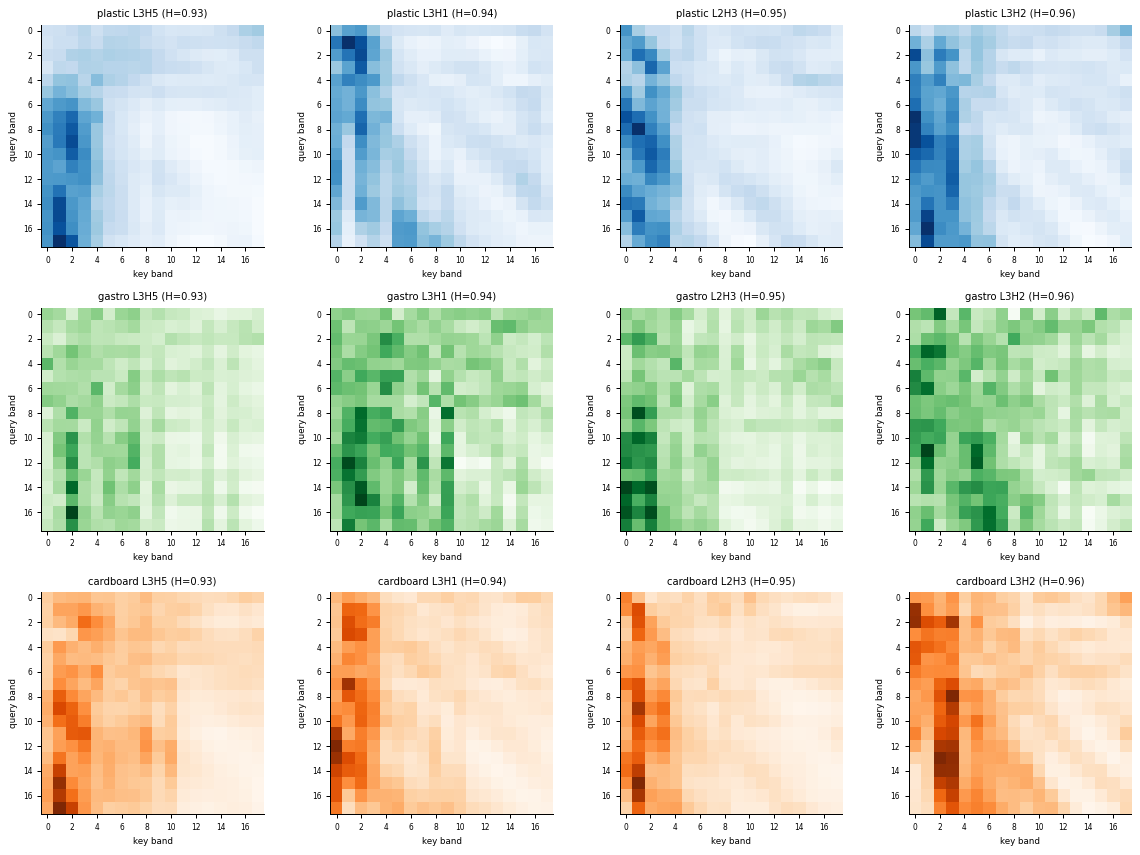

head  self  neighbours  top_column  query_dep  entropy
L3H5 0.047       0.092       0.104      0.095    0.934
L3H1 0.049       0.105       0.096      0.087    0.943
L2H3 0.054       0.100       0.104      0.074    0.952
L0H1 0.049       0.102       0.087      0.098    0.957
L3H2 0.053       0.104       0.091      0.068    0.957
L2H7 0.052       0.097       0.087      0.090    0.960
L2H2 0.050       0.097       0.083      0.084    0.960
L0H2 0.095       0.164       0.069      0.142    0.961
L1H2 0.057       0.115       0.078      0.078    0.963
L1H0 0.048       0.099       0.089      0.079    0.963
query-dependence (TV of rows from the mean row): median 0.075 max 0.142 | uniform self-attention would be 0.056


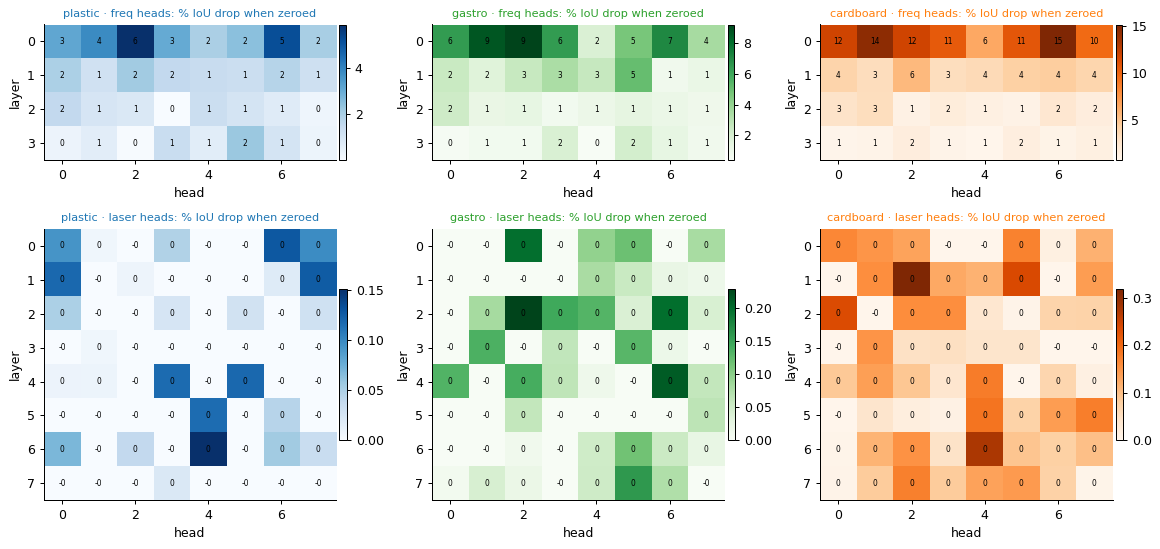

plastic   freq-head drop: max 5.9% (L0H2), median 1.4% | laser-head max 0.2% median -0.0% | ρ(drop, entropy) +0.36  ρ(drop, ρ_masking) -0.25  ρ(drop, ρ_dB) -0.12
gastro    freq-head drop: max 9.2% (L0H2), median 1.8% | laser-head max 0.2% median 0.0% | ρ(drop, entropy) +0.13  ρ(drop, ρ_masking) -0.35  ρ(drop, ρ_dB) -0.50
cardboard freq-head drop: max 15.1% (L0H6), median 3.2% | laser-head max 0.3% median 0.1% | ρ(drop, entropy) +0.31  ρ(drop, ρ_masking) +0.19  ρ(drop, ρ_dB) -0.30


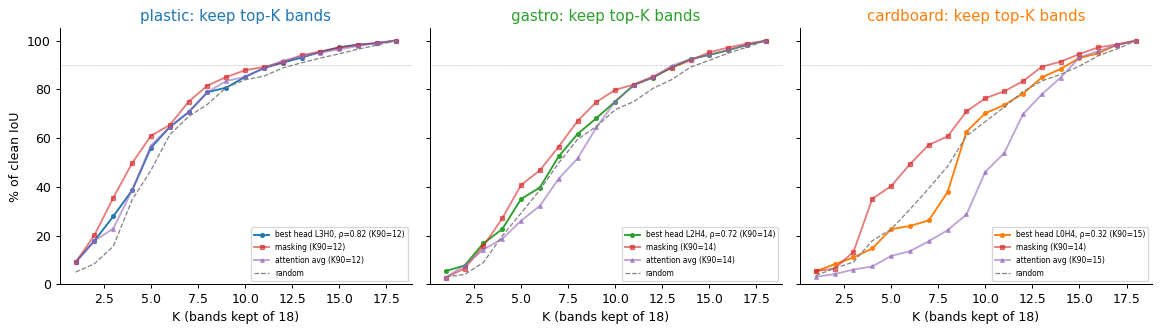

In [9]:
SRC.setdefault("q1c", In[-1])
HD = np.load(CACHE / f"heads_{SET}.npz"); NH = HD["rb"].shape[2]
rb, eb, el, fmap = HD["rb"], HD["eb"], HD["el"], HD["fmap"]; rl = HD["rl"].astype(np.float32)           # (n,4,H,18), (n,4,H), (n,8,H), (3,4,H,18,18); rl (n,8,H,100)
inbox = lambda b: qbox == b                                                         # every view on the same samples (no halves)
mB = {b: Q["mask_b"][inbox(b)].mean(0) for b in BX}; mlB = {b: Q["mask_l"][inbox(b)].mean(0) for b in BX}
DB = {b: REF["Level (dB)"][0][b] for b in BX}
rho = lambda x, y: stats.spearmanr(x, y)[0]
RB = {b: np.array([[rho(rb[inbox(b), l, h].mean(0), mB[b]) for h in range(NH)] for l in range(4)]) for b in BX}     # band ρ vs masking
RD = {b: np.array([[rho(rb[inbox(b), l, h].mean(0), DB[b]) for h in range(NH)] for l in range(4)]) for b in BX}         # band ρ vs input dB
RL = {b: np.array([[rho(rl[inbox(b), l, h].mean(0), mlB[b]) for h in range(NH)] for l in range(8)]) for b in BX}     # laser ρ vs masking
LH = [f"L{l}H{h}" for l in range(4) for h in range(NH)]

# 1 · per-head band profiles (rows = layer × head) and per-layer laser grids
fig, ax = plt.subplots(1, 3, figsize=(13, 6.5))
for a, b in zip(ax, BX):
    heat(a, rb[inbox(b)].mean(0).reshape(-1, 18), b); a.set_yticks(range(32), LH, fontsize=6); a.set_xticks(range(0, 18, 3), [f"{HZ[k]:.0f}" for k in range(0, 18, 3)], fontsize=7)
    [a.axhline(8 * l - .5, c="k", lw=.6) for l in range(1, 4)]; a.set_title(f"{b}: band attention per (layer, head)", color=BOXC[b]); a.set_xlabel("band centre (Hz)")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(3, 8, figsize=(13, 5.4))
for i, b in enumerate(BX):
    for l in range(8): a = ax[i, l]; heat(a, rl[inbox(b), l].mean((0, 1)).reshape(10, 10), b, cbar=False); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([]); a.set_title(f"{b[:5]} L{l}", fontsize=8)
plt.suptitle("laser attention, head-averaged, per layer", fontsize=10); plt.tight_layout(); plt.show()
# most distinctive laser heads: largest cosine distance of the head's grid (all boxes) from its layer's mean grid
G = rl.mean(0)                                                                    # (8,H,100)
dist = 1 - np.einsum("lhk,lk->lh", G, G.mean(1)) / (np.linalg.norm(G, axis=2) * np.linalg.norm(G.mean(1), axis=1)[:, None])
top = np.dstack(np.unravel_index(np.argsort(-dist.ravel())[:6], dist.shape))[0]
fig, ax = plt.subplots(3, 6, figsize=(13, 6.6))
for i, b in enumerate(BX):
    for j, (l, h) in enumerate(top): a = ax[i, j]; heat(a, rl[inbox(b), l, h].mean(0).reshape(10, 10), b, cbar=False); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([]); a.set_title(f"{b[:5]} L{l}H{h} (d={dist[l, h]:.2f})", fontsize=7)
plt.suptitle("the 6 most distinctive laser heads (cosine distance from their layer mean)", fontsize=10); plt.tight_layout(); plt.show()

# 2 · agreement: band ρ vs masking, band ρ vs input dB, laser ρ vs masking, per (layer, head)
fig, ax = plt.subplots(3, 3, figsize=(13, 9), gridspec_kw=dict(height_ratios=[1, 1, 1.7]))
for j, b in enumerate(BX):
    for i, (M, t) in enumerate(((RB[b], "bands: ρ vs masking"), (RD[b], "bands: ρ vs input dB"), (RL[b], "lasers: ρ vs masking"))):
        h = ax[i, j].imshow(M, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto"); ax[i, j].set(xlabel="head", ylabel="layer"); ax[i, j].set_title(f"{b} · {t}", color=BOXC[b], fontsize=9)
        for (y, x), v in np.ndenumerate(M): ax[i, j].text(x, y, f"{v:.1f}", ha="center", va="center", fontsize=6)
plt.colorbar(h, ax=ax, fraction=.015); plt.show()
print("band ρ vs masking — head-averaged:", {b: round(rho(rb[inbox(b)].mean((0, 1, 2)), mB[b]), 2) for b in BX},
      "| best head:", {b: (LH[int(np.nanargmax(RB[b]))], round(np.nanmax(RB[b]), 2)) for b in BX}, "| mean over heads:", {b: round(np.nanmean(RB[b]), 2) for b in BX})
print("band ρ vs input dB per head: median", {b: round(np.median(RD[b]), 2) for b in BX}, "| share of heads with ρ_dB > .8:", {b: round((RD[b] > .8).mean(), 2) for b in BX})
print("laser ρ vs masking: max", {b: round(np.nanmax(RL[b]), 2) for b in BX}, "| mean", {b: round(np.nanmean(RL[b]), 2) for b in BX})

# 3 · specialisation: entropy, head clusters, cross-box stability
Pf = np.stack([rb[inbox(b)].mean(0).reshape(-1, 18) for b in BX])                 # (3,32,18) band profiles
Pfn = Pf / np.linalg.norm(Pf, axis=2, keepdims=True)
cosH = np.einsum("bik,bjk->ij", Pfn, Pfn) / 3                                       # head x head cosine, mean over boxes
from scipy.cluster.hierarchy import linkage, leaves_list, fcluster
Zh = linkage(Pf.transpose(1, 0, 2).reshape(32, -1), "average", metric="cosine"); oh = leaves_list(Zh)
xbox = np.array([np.mean([Pfn[i, k] @ Pfn[j, k] for i in range(3) for j in range(i + 1, 3)]) for k in range(32)])   # same head across boxes
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.3, 1.2, 1]))
for b in BX: ax[0].plot(range(32), eb[inbox(b)].mean(0).ravel(), "o-", ms=3, c=BOXC[b], label=f"{b} bands")
for b in BX: ax[0].plot(range(32, 96), el[inbox(b)].mean(0).ravel(), "s-", ms=2, c=BOXC[b], alpha=.5, label=f"{b} lasers")
ax[0].axvline(31.5, c="k", lw=.5); ax[0].set(xlabel="head (freq L0–3 × 8 | laser L0–7 × 8)", ylabel="row entropy / log T (1 = uniform)", title="how sharp is each head?"); ax[0].legend(fontsize=6)
h = ax[1].imshow(cosH[np.ix_(oh, oh)], cmap="Greys", vmin=cosH.min(), vmax=1); ax[1].set_xticks(range(32), [LH[i] for i in oh], rotation=90, fontsize=5); ax[1].set_yticks(range(32), [LH[i] for i in oh], fontsize=5); ax[1].set_title("band-profile cosine (clustered)"); plt.colorbar(h, ax=ax[1], fraction=.046)
ax[2].bar(range(32), xbox, color="gray"); ax[2].set(ylim=(min(.8, xbox.min() - .02), 1), xlabel="head (L0H0 … L3H7)", ylabel="cosine across boxes", title="same head, different boxes")
plt.tight_layout(); plt.show()
print("band entropy (mean, min):", {b: (round(eb[inbox(b)].mean(), 3), round(eb[inbox(b)].mean(0).min(), 3)) for b in BX}, "| laser entropy (mean, min):", {b: (round(el[inbox(b)].mean(), 3), round(el[inbox(b)].mean(0).min(), 3)) for b in BX})
print("clusters (4):", np.bincount(fcluster(Zh, 4, "maxclust")), "| head band-profile cosine across boxes: min", xbox.min().round(3), "median", np.median(xbox).round(3))

# 4 · query dependence: full band->band maps of the 4 sharpest freq heads, per box; pattern scores
sharp = np.argsort(eb.mean(0).ravel())[:4]
fig, ax = plt.subplots(3, 4, figsize=(13, 9.6))
for i, b in enumerate(BX):
    for j, k in enumerate(sharp):
        l, h = divmod(k, NH); a = ax[i, j]; heat(a, fmap[i, l, h], b, cbar=False); a.set_aspect("equal"); a.set_title(f"{b} {LH[k]} (H={eb.mean(0).ravel()[k]:.2f})", fontsize=8)
        a.set_xlabel("key band", fontsize=7); a.set_ylabel("query band", fontsize=7); a.tick_params(labelsize=6)
plt.tight_layout(); plt.show()
diag = np.einsum("bLhii->Lh", fmap) / 18 / 3                                      # mean self-attention
nbr = np.mean([fmap[..., i, i + d] for i in range(18) for d in (-1, 1) if 0 <= i + d < 18], 0).mean(0) * 2   # ~ mass on ±1 neighbours
colmax = (fmap.mean(3).max(-1)).mean(0)                                           # largest column share = "everyone attends to one band"
qdep = np.abs(fmap - fmap.mean(3, keepdims=True)).sum(-1).mean((0, 3)) / 2       # total-variation distance of a query row from the head's mean row
pat = pd.DataFrame(dict(head=LH, self=diag.ravel(), neighbours=nbr.ravel(), top_column=colmax.ravel(), query_dep=qdep.ravel(), entropy=eb.mean(0).ravel())).round(3)
print(pat.sort_values("entropy").head(10).to_string(index=False)); print("query-dependence (TV of rows from the mean row): median", np.median(qdep).round(3), "max", qdep.max().round(3), "| uniform self-attention would be", round(1 / 18, 3))

# 5 · causal: relative IoU drop when one head's output is zeroed
cl = HD["clean"]; ABL = {b: (cl[inbox(b)].mean() - HD["abl"][:, :, inbox(b)].mean(2)) / cl[inbox(b)].mean() for b in BX}   # (12 blocks, H)
fig, ax = plt.subplots(2, 3, figsize=(13, 6.2), gridspec_kw=dict(height_ratios=[1, 2]))
for j, b in enumerate(BX):
    for i, (M, t) in enumerate(((ABL[b][:4], "freq heads"), (ABL[b][4:], "laser heads"))):
        heat(ax[i, j], 100 * M, b); ax[i, j].set(xlabel="head", ylabel="layer"); ax[i, j].set_title(f"{b} · {t}: % IoU drop when zeroed", color=BOXC[b], fontsize=9)
        for (y, x), v in np.ndenumerate(100 * M): ax[i, j].text(x, y, f"{v:.0f}", ha="center", va="center", fontsize=6)
plt.tight_layout(); plt.show()
for b in BX:
    fa = ABL[b][:4].ravel()
    print(f"{b:9s} freq-head drop: max {100 * fa.max():.1f}% ({LH[fa.argmax()]}), median {100 * np.median(fa):.1f}% | laser-head max {100 * ABL[b][4:].max():.1f}% median {100 * np.median(ABL[b][4:]):.1f}%"
          f" | ρ(drop, entropy) {rho(fa, eb[inbox(b)].mean(0).ravel()):+.2f}  ρ(drop, ρ_masking) {rho(fa, RB[b].ravel()):+.2f}  ρ(drop, ρ_dB) {rho(fa, RD[b].ravel()):+.2f}")

# 6 · band top-K with the head that best agrees with masking (chosen and graded on the same samples)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a, b in zip(ax, BX):
    (l, h, r), hb = Q[f"best|{b}"], cv(b, "band", "head"); lab = f"L{int(l)}H{int(h)}"
    a.plot(KB, 100 * hb / c0[b], "o-", ms=3, c=BOXC[b], label=f"best head {lab}, ρ={r:.2f} ({k90(hb, KB, b)})")
    a.plot(KB, 100 * cv(b, "band", "masking") / c0[b], "s-", ms=3, c="tab:red", alpha=.6, label=f"masking ({k90(cv(b, 'band', 'masking'), KB, b)})")
    a.plot(KB, 100 * cv(b, "band", "attention") / c0[b], "^-", ms=3, c="tab:purple", alpha=.6, label=f"attention avg ({k90(cv(b, 'band', 'attention'), KB, b)})")
    a.plot(KB, 100 * rnd(b, "band") / c0[b], "--", c="gray", lw=1, label="random")
    a.axhline(90, c="gray", lw=.5, ls=":"); a.set(xlabel="K (bands kept of 18)", ylim=(0, 105)); a.set_title(f"{b}: keep top-K bands", color=BOXC[b]); a.legend(fontsize=6)
ax[0].set_ylabel("% of clean IoU"); plt.tight_layout(); plt.show()

**Answer** (SET = train, same 720 samples). Averaging did **not** hide a masking-like head.

- **Heads track input loudness.** Per-head band attention vs Level (dB): median ρ .80 / .83 / .90 (plastic / gastro / cardboard), 50–66% of the 32 freq heads above .8. Agreement with masking on the same samples:

| | plastic | gastro | cardboard |
|---|---|---|---|
| head-averaged ρ | .81 | .62 | −.11 |
| mean over heads | .56 | .43 | −.18 |
| best single head | .82 (L3H0) | .72 (L2H4) | .32 (L0H4) |

  The best head is picked on these samples, so its ρ is optimistic. Laser heads vs masking reach at most ρ .41.
- **No specialisation.** Band row entropy is ≥ .90 of the maximum (mean .96–.97) and laser entropy ≥ .96. Head band profiles are almost identical across boxes (cosine ≥ .962, median .99); 27 of 32 heads fall in one cluster.
- **Weak query dependence.** Median row-vs-mean TV distance .075 (max .14). The exception is **L0H2**, the local head: self .095 vs .056 uniform, ±1 neighbours .164, most query-dependent (.14).
- **Causal check.** Zeroing one freq head costs at most 5.9% (L0H2, plastic), 9.2% (L0H2, gastro), 15.1% (L0H6, cardboard), medians 1.4–3.2%. Any single laser head costs ≤ 0.3%. Head importance anti-correlates with loudness tracking (ρ(drop, ρ_dB) −.12 / −.50 / −.30).
- **Top-K with the best head** does not beat masking: K90 12 / 14 / 15 (AUC .72 / .62 / .55) vs masking 12 / 14 / 14 (.74 / .64 / .64) and random 13 / 15 / 16.

**Bottom line.** The averaged attention map in Q1 is representative. Attention is near-uniform and its deviations follow loudness. What the model uses is computed in the value / MLP path and the flatten readout. The local L0H2 matters causally, but its profile is not a band-importance ranking.

## Q1-eval · the same analysis on eval
The Q1, Q1b and Q1c code re-run unchanged with `SET = "eval"`: the fixed 720 single-object **ID-eval** samples (60 per object × box, seed 0, `subset720.npz`), read from `q1_eval.npz` / `heads_eval.npz`. **On eval, IoU is well below ceiling** (clean IoU .69 / .71 / .62 vs .93 / .91 / .91 on train), so these rankings describe generalisation-regime use. Top-K curves are again graded on the samples that built the ranking.

eval subset: single-object, object present, 60 per box × object (seed 0, drawn from q1_single.npz)
col_0      candle  red-cube  soap dispenser  vase  All
row_0                                                 
plastic        60        60              60    60  240
gastro         60        60              60    60  240
cardboard      60        60              60    60  240
All           180       180             180   180  720
clean IoU: {'plastic': 0.692, 'gastro': 0.711, 'cardboard': 0.619} 



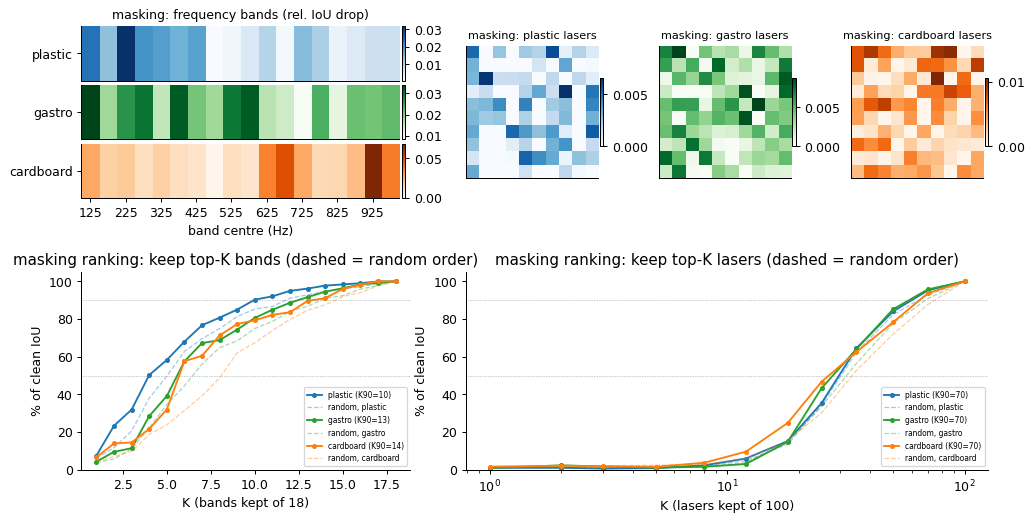

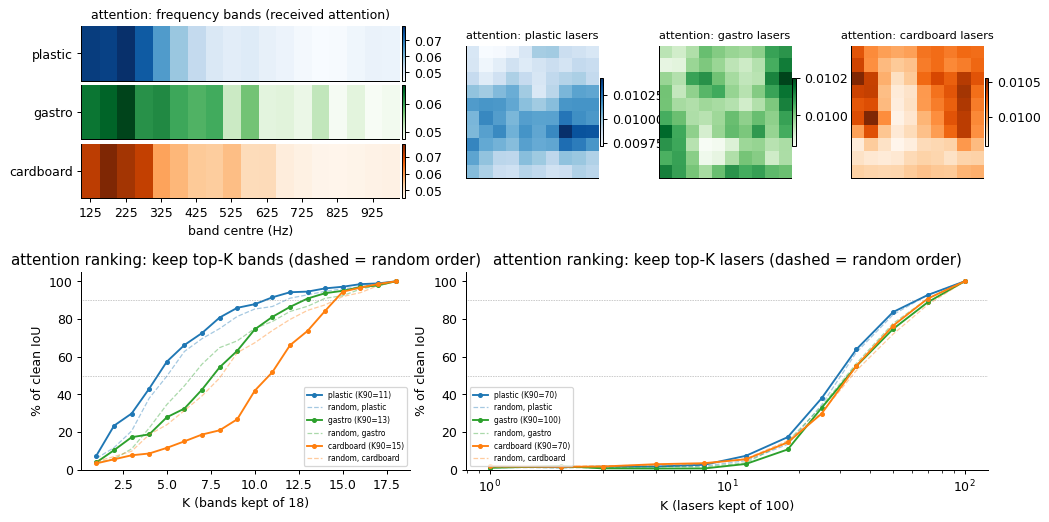

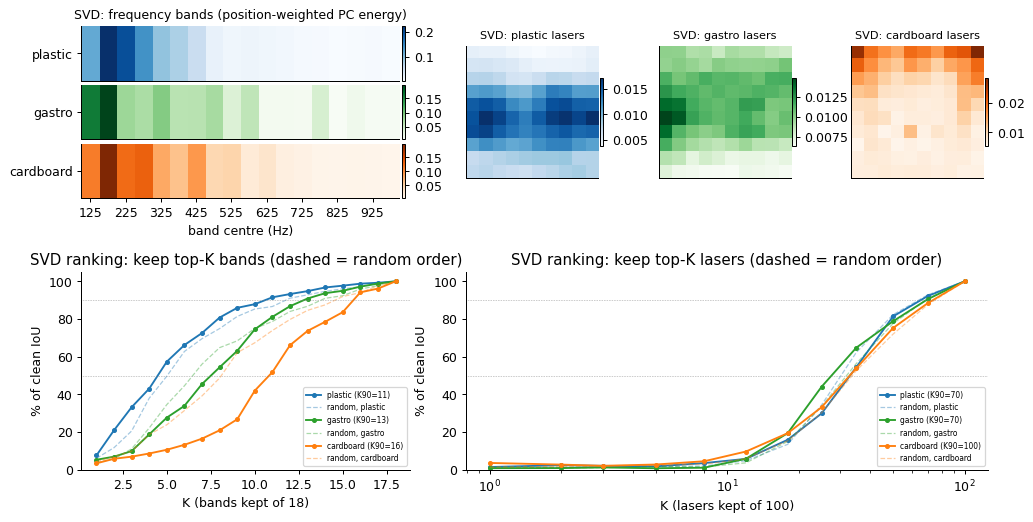

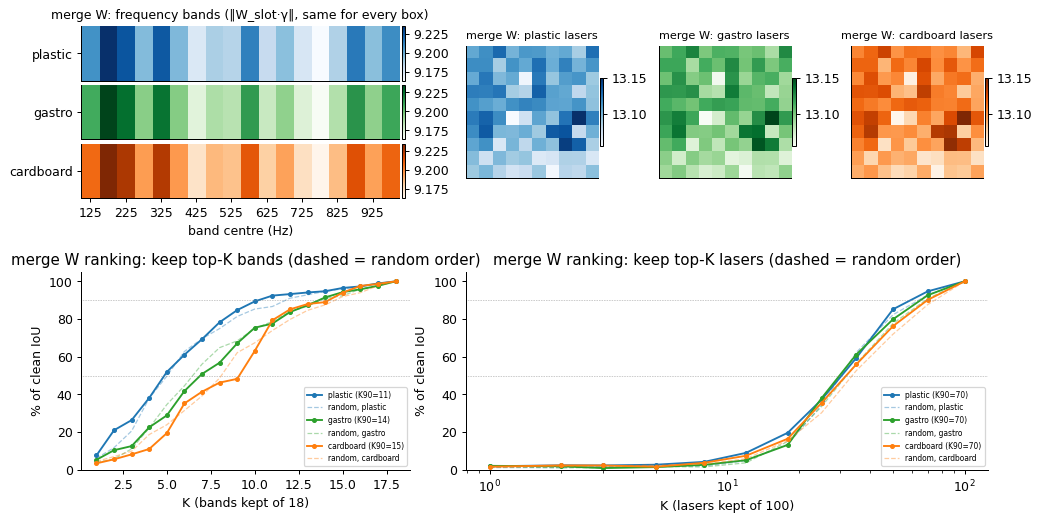

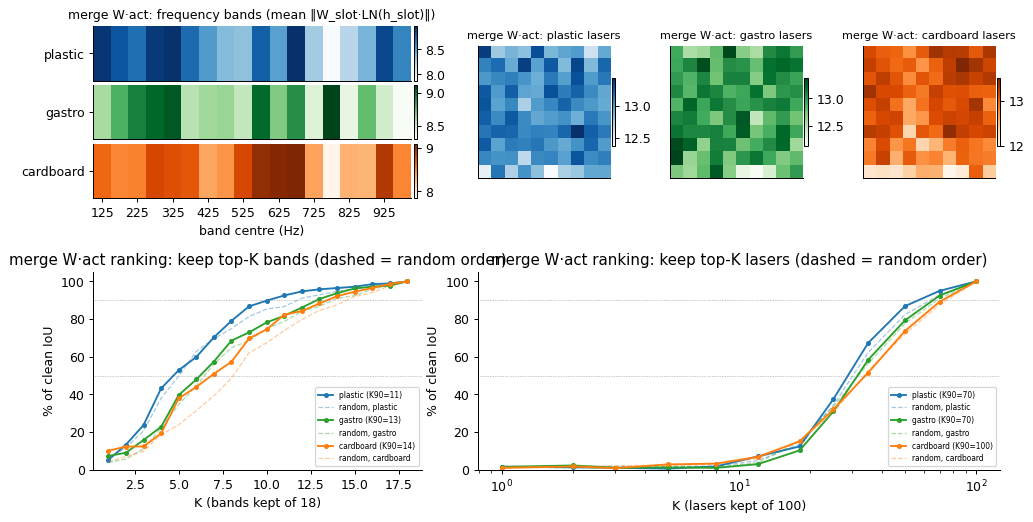

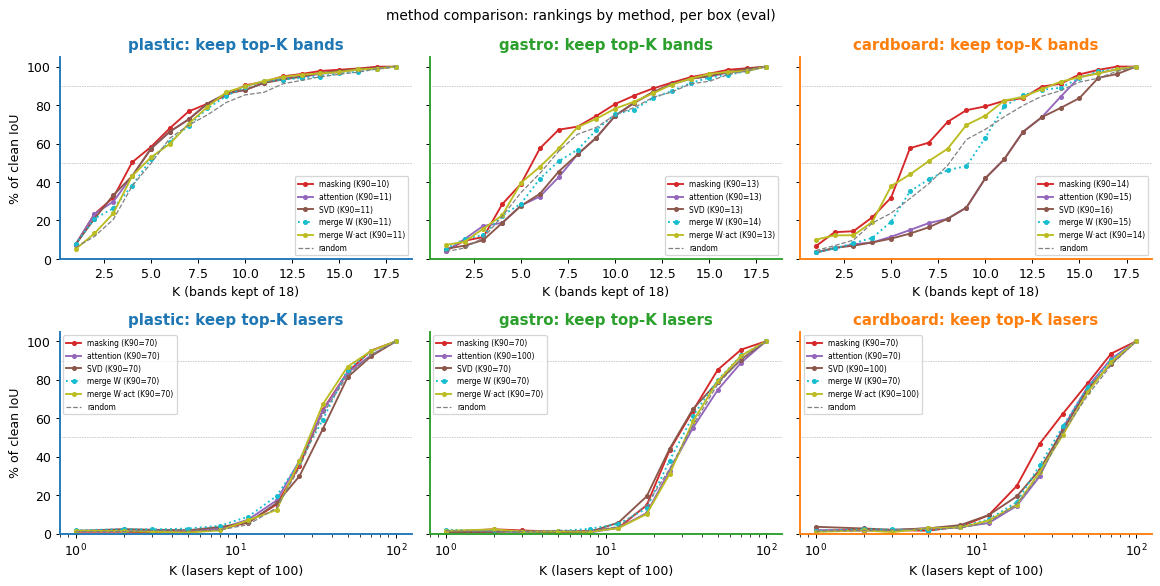

                        AUC                      K50                      K90               
box               cardboard gastro plastic cardboard gastro plastic cardboard gastro plastic
unit  ranking                                                                               
band  SVD             0.444  0.602   0.738        11      8       5        16     13      11
      attention       0.459  0.604   0.736        11      8       5        15     13      11
      masking         0.653  0.664   0.750         6      6       4        14     13      10
      merge W         0.563  0.611   0.719        10      7       5        15     14      11
      merge W·act     0.625  0.646   0.721         7      7       5        14     13      11
      random          0.568  0.618   0.698         9      7       6        15     14      12
laser SVD             0.329  0.340   0.325        35     35      35       100     70      70
      attention       0.319  0.308   0.343        35     35      35   

position sensitivity variants: Pearson r with masking band importance (max over 9 variants is optimistic: selected on these samples)
                                              plastic  gastro  cardboard  mean
σ_pos/σ_empty, linear v, per-laser              -0.03   -0.39       0.61  0.07
σ_pos/σ_empty, dB, per-laser                    -0.07   -0.41       0.54  0.02
σ_pos/σ_empty, linear v, laser-mean             -0.12   -0.45       0.65  0.02
Fisher ratio (between-pos / repeat var), dB     -0.12   -0.31       0.47  0.01
σ_pos/σ_empty, dB, laser-mean                   -0.19   -0.46       0.55 -0.03
neighbour |Δ| / repeat |Δ|, dB                  -0.13   -0.45       0.46 -0.04
single-band linear probe R² → (x, y)            -0.08   -0.26       0.02 -0.10
σ_pos/σ_empty, z (encoder input), per-laser     -0.07   -0.05      -0.51 -0.21
σ_pos/σ_empty, z (encoder input), laser-mean    -0.20   -0.04      -0.51 -0.25


<string>:52: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.


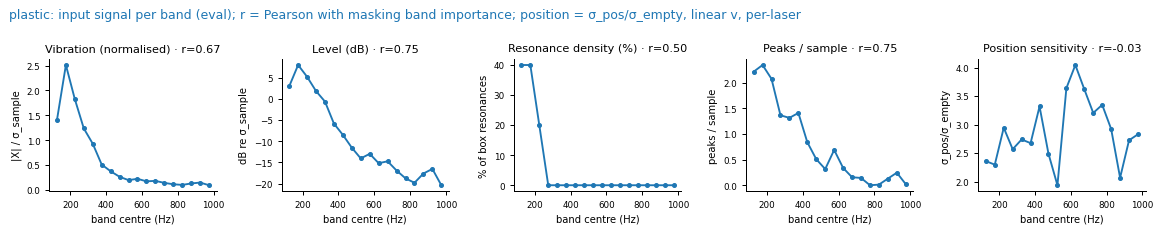

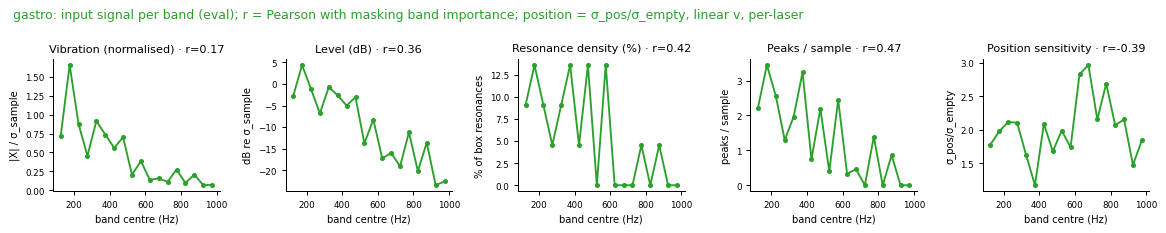

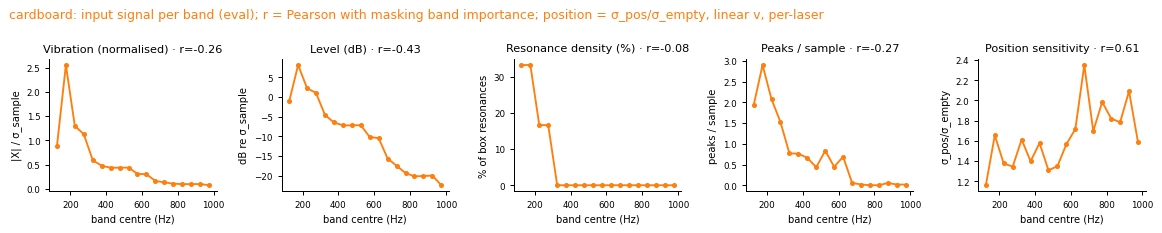

box resonances, relaxed (Hz): {'plastic': [113, 140, 155, 195, 213], 'gastro': [124, 134, 150, 172, 184, 222, 247, 271, 309, 321, 364, 384, 398, 432, 453, 473, 495, 565, 577, 595, 771, 862], 'cardboard': [115, 140, 159, 173, 236, 260]}
peaks per sample, total and share above 500 Hz: {'plastic': (np.float64(14.1), '14%'), 'gastro': (np.float64(23.5), '25%'), 'cardboard': (np.float64(13.2), '16%')}
empty captures used for σ_empty: {'plastic': 60, 'gastro': 36, 'cardboard': 73}
Pearson r of each input view with each importance view (bands):
                       plastic                                      gastro                                     cardboard                                    
                       masking attention   SVD merge W merge W·act masking attention   SVD merge W merge W·act   masking attention   SVD merge W merge W·act
Vibration (normalised)    0.67      0.94  0.98    0.67        0.49    0.17      0.87  0.91    0.61        0.34     -0.26      0.91  0.94    0.

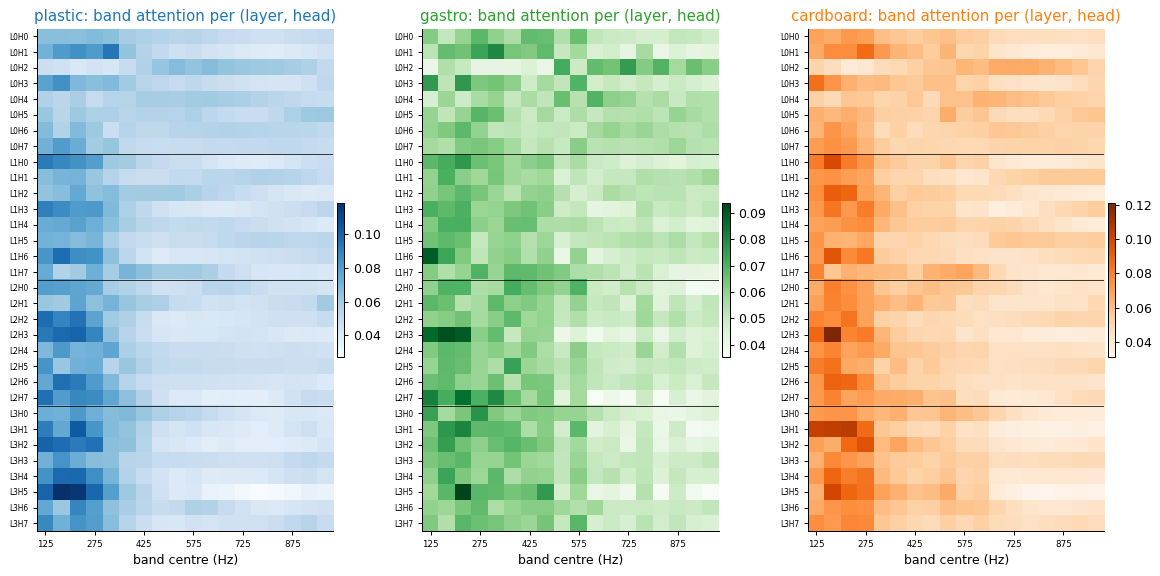

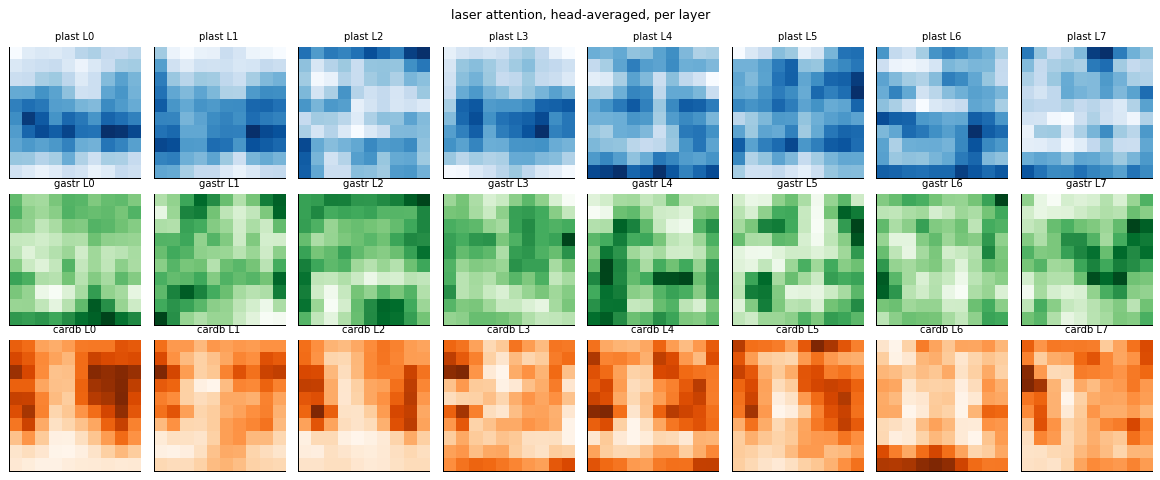

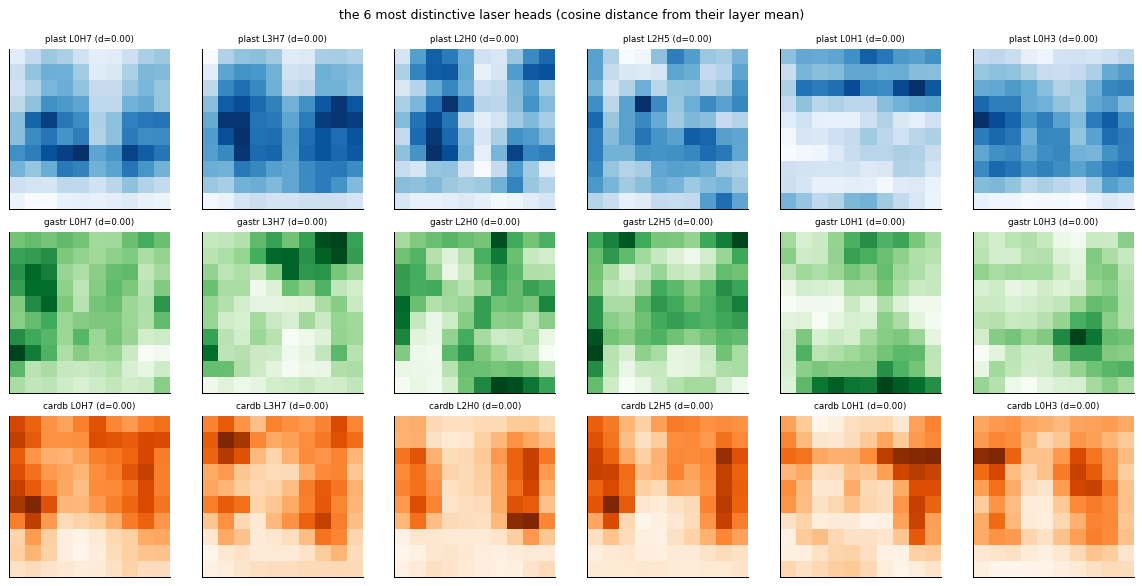

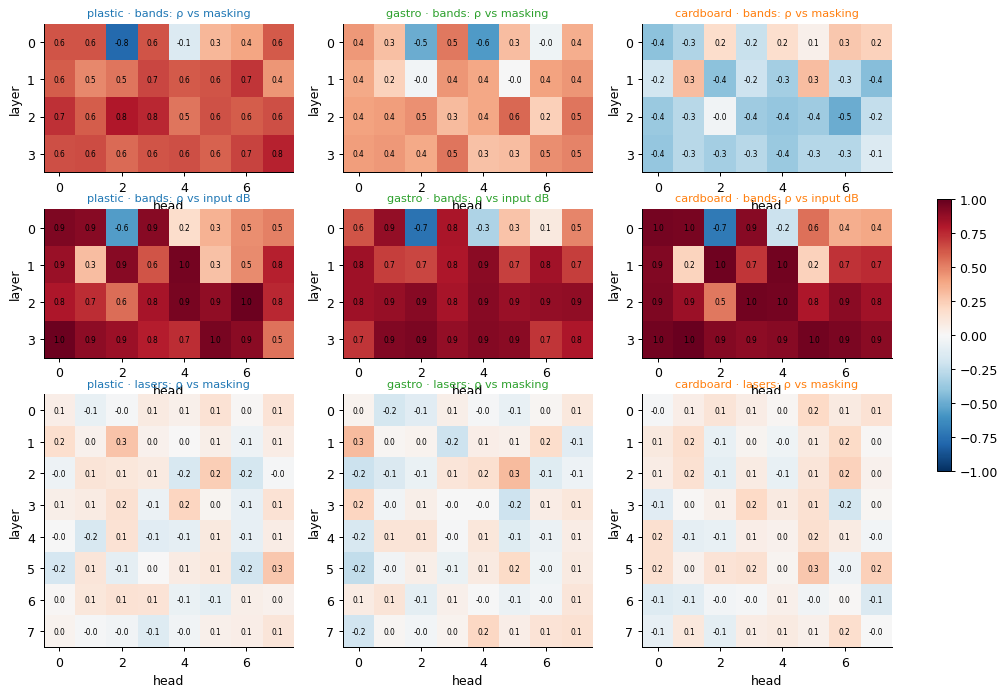

band ρ vs masking — head-averaged: {'plastic': np.float64(0.62), 'gastro': np.float64(0.41), 'cardboard': np.float64(-0.25)} | best head: {'plastic': ('L2H2', np.float64(0.8)), 'gastro': ('L2H5', np.float64(0.58)), 'cardboard': ('L1H1', np.float64(0.31))} | mean over heads: {'plastic': np.float64(0.55), 'gastro': np.float64(0.3), 'cardboard': np.float64(-0.19)}
band ρ vs input dB per head: median {'plastic': np.float64(0.8), 'gastro': np.float64(0.83), 'cardboard': np.float64(0.9)} | share of heads with ρ_dB > .8: {'plastic': np.float64(0.5), 'gastro': np.float64(0.62), 'cardboard': np.float64(0.66)}
laser ρ vs masking: max {'plastic': np.float64(0.29), 'gastro': np.float64(0.32), 'cardboard': np.float64(0.27)} | mean {'plastic': np.float64(0.03), 'gastro': np.float64(0.02), 'cardboard': np.float64(0.05)}


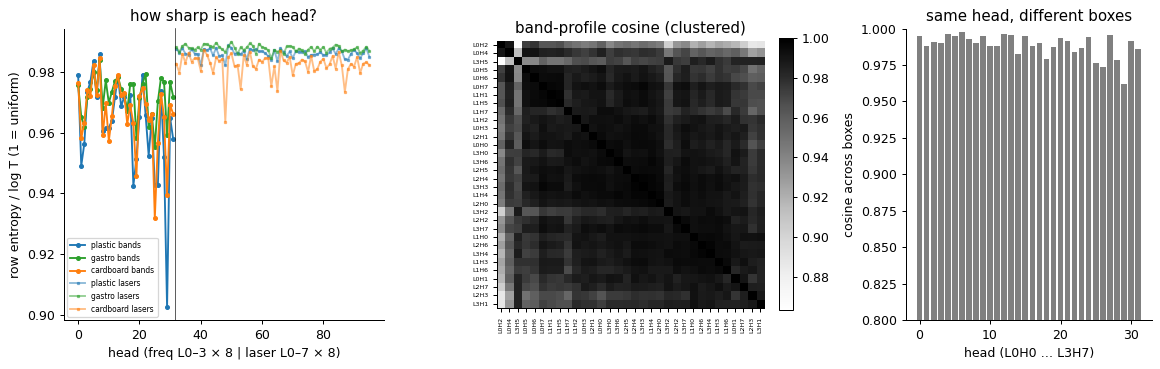

band entropy (mean, min): {'plastic': (np.float32(0.963), np.float32(0.903)), 'gastro': (np.float32(0.972), np.float32(0.955)), 'cardboard': (np.float32(0.966), np.float32(0.932))} | laser entropy (mean, min): {'plastic': (np.float32(0.986), np.float32(0.982)), 'gastro': (np.float32(0.988), np.float32(0.984)), 'cardboard': (np.float32(0.982), np.float32(0.964))}
clusters (4): [ 0  2 17 12  1] | head band-profile cosine across boxes: min 0.962 median 0.99


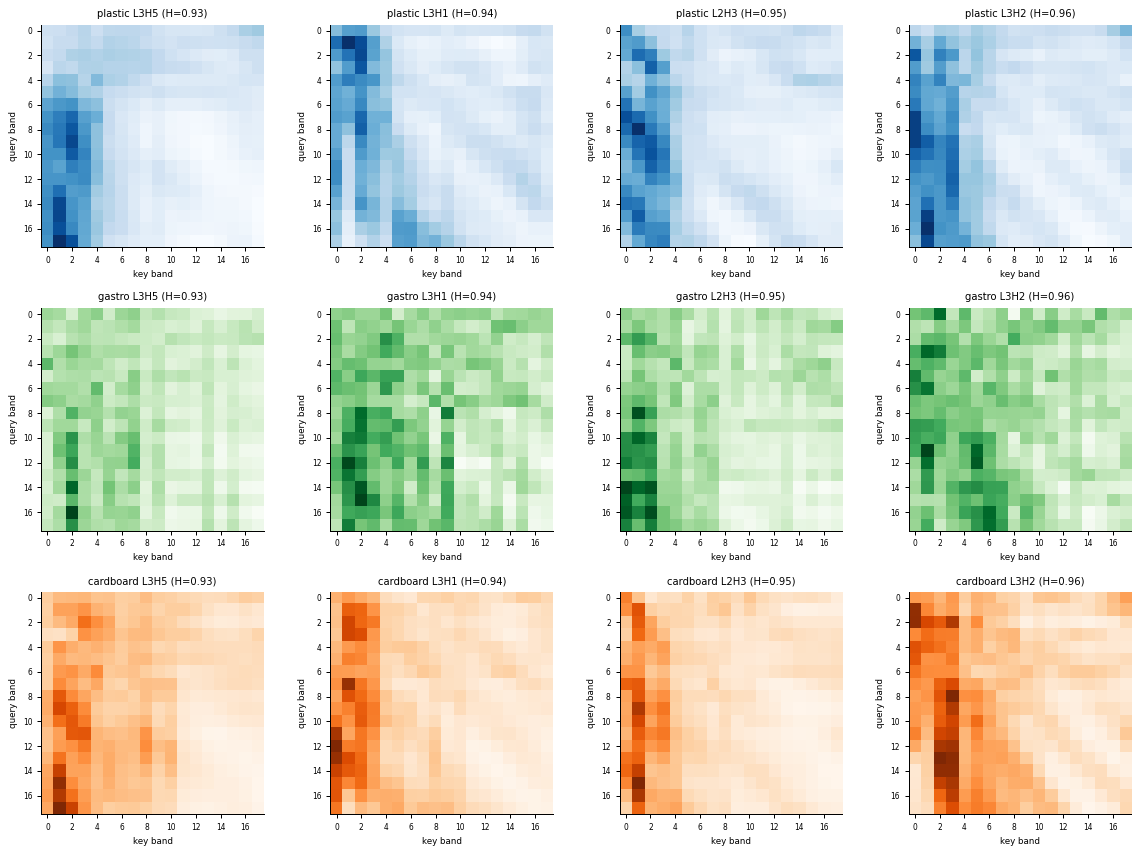

head  self  neighbours  top_column  query_dep  entropy
L3H5 0.047       0.092       0.104      0.094    0.934
L3H1 0.049       0.105       0.096      0.086    0.943
L2H3 0.054       0.100       0.104      0.074    0.952
L0H1 0.049       0.101       0.087      0.096    0.957
L3H2 0.053       0.104       0.090      0.068    0.957
L0H2 0.095       0.164       0.069      0.142    0.960
L2H7 0.052       0.097       0.087      0.089    0.960
L2H2 0.050       0.097       0.083      0.082    0.961
L1H2 0.057       0.114       0.078      0.078    0.963
L1H0 0.048       0.099       0.089      0.079    0.963
query-dependence (TV of rows from the mean row): median 0.074 max 0.142 | uniform self-attention would be 0.056


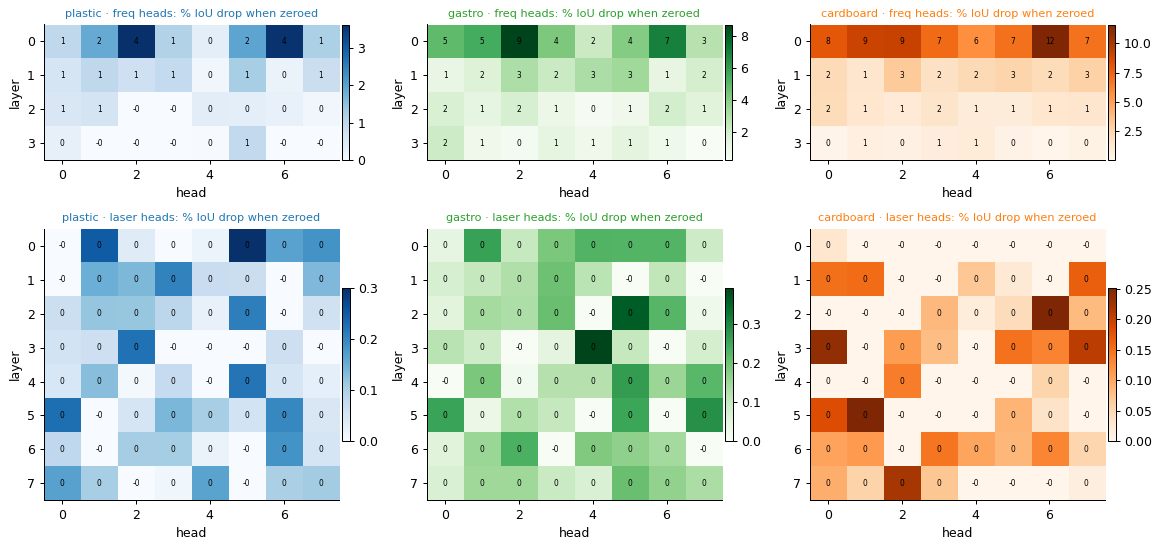

plastic   freq-head drop: max 3.6% (L0H2), median 0.5% | laser-head max 0.3% median 0.1% | ρ(drop, entropy) +0.36  ρ(drop, ρ_masking) -0.57  ρ(drop, ρ_dB) -0.24
gastro    freq-head drop: max 8.7% (L0H2), median 1.8% | laser-head max 0.4% median 0.1% | ρ(drop, entropy) +0.13  ρ(drop, ρ_masking) -0.38  ρ(drop, ρ_dB) -0.60
cardboard freq-head drop: max 11.6% (L0H6), median 1.7% | laser-head max 0.3% median 0.0% | ρ(drop, entropy) +0.35  ρ(drop, ρ_masking) +0.27  ρ(drop, ρ_dB) -0.36


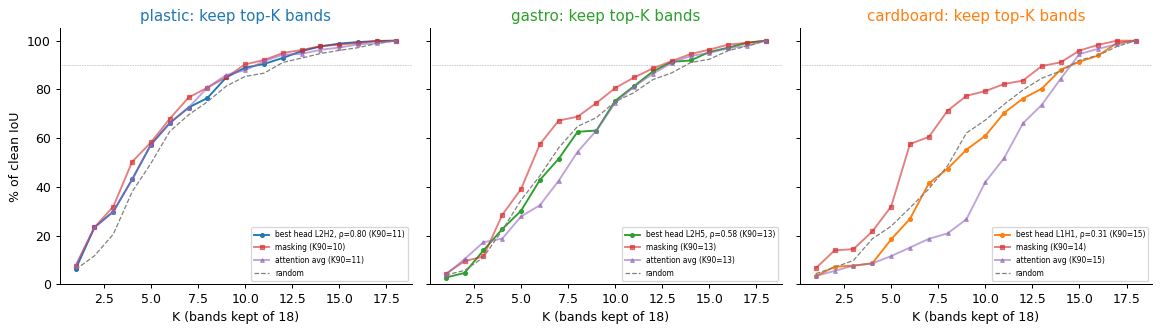

In [10]:
SET = "eval"
for k in ("q1", "q1b", "q1c"): exec(SRC[k])

**Answer** (SET = eval, 720 single-object ID-eval samples, 240 per box). Clean IoU **.69 / .71 / .62** (plastic / gastro / cardboard), vs .93 / .91 / .91 on train. The top-K curves grade each ranking on the samples that built it.

**No single unit matters much.** The largest single band costs 3.2 / 3.4 / 6.9% of clean IoU, the largest single laser ≤ 1.1% (train 3.8 / 4.3 / 6.1%, ≤ 1.0%).

**Which bands**
- **Masking** peaks at 224 / 124 / 925 Hz (train 224 / 224 / 625). Importance-weighted mean band frequency 422 / 515 / 639 Hz (train 463 / 508 / 576): cardboard leans even higher on eval, plastic lower.
- **Attention and SVD** still put the mass on the loud 125–275 Hz bands (peaks 174–224 Hz; SVD weighted means 281 / 340 / 322 Hz) and agree with each other (ρ .94 / .97 / .95). Masking ~ attention ρ .62 / .41 / −.25, masking ~ SVD .62 / .36 / −.39: both lower than on train (.81 / .62 / −.11 and .76 / .53 / −.27); still negative in cardboard.
- **Merge W** is box-agnostic and flat (549 Hz). **Merge W·act** is also flat (545–548 Hz) and agrees less with masking than on train (ρ .34 / .17 / .23 vs .54 / .62 / .64).

**Top-K bands** (K90 = bands kept for 90% of clean IoU; random 12 / 14 / 15, train 13 / 15 / 16)
- Masking: K90 10 / 13 / 14, AUC .75 / .66 / .65 (random .70 / .62 / .57). Best in every box, again by only 1–2 bands (train K90 12 / 14 / 14).
- Attention / SVD: K90 11 / 13 / 15–16; in cardboard both are **worse than random** (AUC .46 / .44 vs .57; K50 11 vs 9), as on train.
- Merge W·act: K90 11 / 13 / 14, AUC .72 / .65 / .63, second best. Merge W: K90 11 / 14 / 15, AUC .72 / .61 / .56, ≈ random.
- The best ranking needs 4–6 bands for half the IoU: information is spread over many bands.

**Lasers.** No ranking clearly beats random. K50 = 35 for every method and box, K90 70–100 (random 100 / 70 / 70). Masking has the highest AUC in gastro and cardboard (.34 / .36 vs random .32 / .31) but only by .01–.04, and the K grid is coarse. Laser rankings barely agree with masking (|ρ| ≤ .17, train ≤ .37). The array is used as a redundant set.

**Q1b · input views vs masking** (Pearson r, plastic / gastro / cardboard)
- Vibration (normalised) .67 / .17 / −.26; Level (dB) .75 / .36 / −.43; Resonance density .50 / .42 / −.08; Peaks / sample .75 / .47 / −.27 (train .53 / .26 / −.38, .74 / .45 / −.26, .22 / .32 / −.23, .72 / .44 / −.25). The input views still follow loudness: they track attention (r .76–.98) and SVD (.72–.98) in every box, masking in plastic and weakly gastro, and are anti-correlated with use in cardboard.
- **Position sensitivity.** The best variant by mean r is now σ_pos / σ_empty on linear v, per laser: −.03 / −.39 / **.61** (mean .07; train's best, the single-band probe R², is −.08 / −.26 / .02 here). All σ_pos / σ_empty (dB and linear), Fisher and neighbour / repeat variants reach r .46–.65 in cardboard but are negative in plastic and gastro; the z-scored variants are −.51 in cardboard. On eval, cardboard's high-band use lines up with where the spectrum moves with position, but the sign flips across boxes and the max over 9 variants is optimistic. σ_empty uses **train** empty captures (the eval set has < 8 per box): 60 / 36 / 73.
- Relaxed resonances: plastic 5 (113–213 Hz), gastro 22 (up to 862 Hz), cardboard 6 (≤ 260 Hz). Peaks per sample 14.1 / 23.5 / 13.2, 14 / 25 / 16% above 500 Hz: the same box physics as train.

Conclusion (same as train): attention, SVD and the input views measure loudness and match use only where use is loud (plastic). Masking is the attribution to use; on eval it shifts further to high bands in cardboard. The follow-ups refine this. Only plastic's masking peak is stable, so the per-box claim is the importance-weighted mean frequency, rising plastic < gastro < cardboard (FQ1). How a band is read depends on damping: exact resonance frequencies in lightly damped gastro, the across-laser amplitude pattern in damped cardboard and plastic (FQ3).

**Q1c on eval.** Same as train: averaging did **not** hide a masking-like head.

- **Heads track input loudness.** Per-head band attention vs Level (dB): median ρ .80 / .83 / .90 (plastic / gastro / cardboard), 50–66% of the 32 freq heads above .8 (train identical). Agreement with masking on the same samples (train in brackets):

| | plastic | gastro | cardboard |
|---|---|---|---|
| head-averaged ρ | .62 (.81) | .41 (.62) | −.25 (−.11) |
| mean over heads | .55 (.56) | .30 (.43) | −.19 (−.18) |
| best single head | .80 (L2H2) | .58 (L2H5) | .31 (L1H1) |

  The best head is picked on these samples, so its ρ is optimistic; it is a different head from train in every box (train L3H0 / L2H4 / L0H4). Laser heads vs masking reach at most ρ .32.
- **No specialisation.** Band row entropy ≥ .90 of the maximum (mean .96–.97), laser entropy ≥ .96. Head band profiles are near-identical across boxes (cosine ≥ .962, median .99); the 4-cluster split is 17 / 12 / 2 / 1 heads (train 27 / 2 / 2 / 1).
- **Weak query dependence.** Median row-vs-mean TV .074 (max .14). **L0H2** is again the local head: self .095 vs .056 uniform, ±1 neighbours .164, most query-dependent (.14).
- **Causal check.** Zeroing one freq head costs at most 3.6% (L0H2, plastic), 8.7% (L0H2, gastro), 11.6% (L0H6, cardboard), medians 0.5–1.8% (train 5.9 / 9.2 / 15.1%, medians 1.4–3.2%): the same heads matter, a little less on eval. Any laser head ≤ 0.4%. Head importance anti-correlates with loudness tracking (ρ(drop, ρ_dB) −.24 / −.60 / −.36).
- **Top-K with the best head** does not beat masking: K90 11 / 13 / 15 (AUC .74 / .62 / .54) vs masking 10 / 13 / 14 (.75 / .66 / .65) and random 12 / 14 / 15.

**Bottom line.** As on train, the averaged attention map is representative: near-uniform, deviations follow loudness. What the model uses is computed in the value / MLP path and the flatten readout; L0H2 / L0H6 matter causally but are not band-importance rankings.


### Train vs eval
Bands only (lasers ≈ random on both). Per box plastic / gastro / cardboard; AUC = mean of IoU_K / IoU_clean over the top-K band curve.

In [11]:
def summ(s):
    q = np.load(CACHE / f"q1_{s}.npz"); bx, Ks = q["box"], q["KB"]; c0 = {b: q["clean"][bx == b].mean() for b in BX}
    cvq = lambda b, r: np.mean([q[f"c|{b}|band|random{k}"] for k in range(3)], 0) if r == "random" else q[f"c|{b}|band|" + {"SVD": "svd", "merge W": "weight", "merge W·act": "contribution"}.get(r, r)]
    j = lambda f: " / ".join(str(f(b)) for b in BX)
    out = {"clean IoU": j(lambda b: f"{c0[b]:.2f}"), "masking peak band (Hz)": j(lambda b: int(HZ[np.argmax(q["mask_b"][bx == b].mean(0))]))}
    for r in RK + ["random"]: out[f"band K90 · {r}"] = j(lambda b: kneed(cvq(b, r), Ks, c0[b], .9))
    for r in RK + ["random"]: out[f"cardboard band AUC · {r}"] = f"{np.mean(cvq('cardboard', r) / c0['cardboard']):.2f}"
    return out
pd.DataFrame({s: summ(s) for s in ("train", "eval")})

,train,eval
clean IoU,0.93 / 0.91 / 0.91,0.69 / 0.71 / 0.62
masking peak band (Hz),224 / 224 / 625,224 / 124 / 925
band K90 · masking,12 / 14 / 14,10 / 13 / 14
band K90 · attention,12 / 14 / 15,11 / 13 / 15
band K90 · SVD,12 / 14 / 16,11 / 13 / 16
band K90 · merge W,12 / 15 / 16,11 / 14 / 15
band K90 · merge W·act,13 / 14 / 15,11 / 13 / 14
band K90 · random,13 / 15 / 16,12 / 14 / 15
cardboard band AUC · masking,0.64,0.65
cardboard band AUC · attention,0.46,0.46


## Q2 · Is there a physical object signature, and does detectability follow it?
An object on the floor adds mass and a local constraint to the plate-like floor: by Rayleigh's quotient, a point mass m at x lowers mode n by Δf_n/f_n ≈ −½·m·φ_n(x)²/M_n, proportional to the squared mode shape at the object, so position is encoded in *which* modes shift and by how much, and the shifts change the *spatial* pattern of the wall response (mode shapes re-mix), not only its average level. Tests: (a) the empty-subtracted wall-average log spectrum Δ(f) = spec − mean_empty(box, speaker); (b) the per-laser spatial pattern (band level minus its wall mean) vs empty; (c) the cylinder series 100 → 1000 g. Caveat: the cylinders are not one footprint (≈4 → 24 px at 64×64), so mass and size are confounded; cardboard cylinders are trained, gastro / plastic cylinders are fully held out.

/tmp/ipykernel_2548919/3479349859.py:9: RuntimeWarning: Mean of empty slice
  df["dmag"] = np.sqrt(np.nanmean(DSP ** 2, 1))                                   # rms Δ of the wall-average spectrum


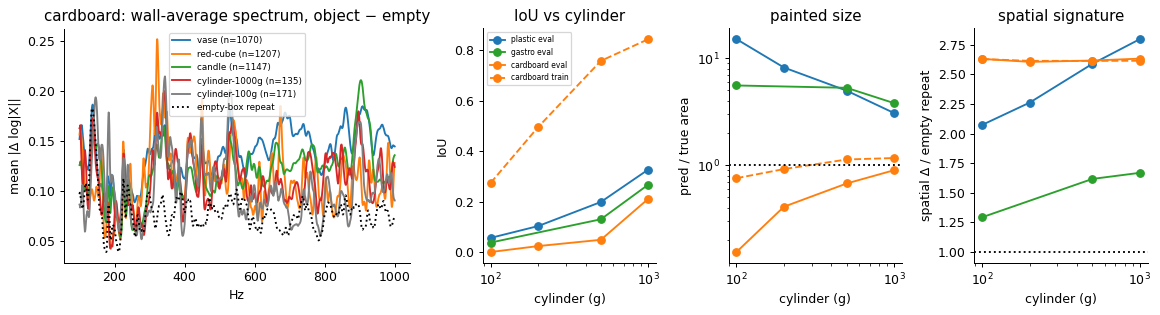

          box    set     g   iou   cerr  bound   area  parea  empty   dsp    n
0   cardboard   eval   100  0.00  46.30   0.12   4.33   0.67   0.75  0.24   36
1   cardboard   eval   200  0.02  26.22   0.27   7.90   3.22   0.45  0.24   40
2   cardboard   eval   500  0.05   7.08   0.57  14.40   9.70   0.12  0.24   40
3   cardboard   eval  1000  0.21   4.82   0.69  25.29  22.68   0.04  0.24   28
4   cardboard  train   100  0.27  20.70   0.33   4.87   3.67   0.51  0.24  135
5   cardboard  train   200  0.50   0.31   0.54   8.13   7.47   0.24  0.24  153
6   cardboard  train   500  0.76   0.17   0.78  16.06  18.14   0.05  0.24  159
7   cardboard  train  1000  0.84   0.13   0.86  24.17  28.18   0.00  0.24  107
8      gastro   eval   100  0.04  21.63   0.09   3.50  19.50   0.33  0.06    6
9      gastro   eval   500  0.13   3.01   0.19  10.22  54.15   0.04  0.07   27
10     gastro   eval  1000  0.27   0.95   0.28  17.22  65.56   0.00  0.07   27
11    plastic   eval   100  0.06   3.16   0.07   3.5

In [12]:
SP = B["spec"].astype(np.float32).mean(-1)                                      # (N,1170) laser-mean log|X|, both axes
LB = B["lb"].astype(np.float32); LBc = LB - LB.mean(1, keepdims=True)           # per-laser band levels; minus the wall mean = spatial pattern only
emp = (df.n_obj == 0).values & TR
BS = [(b, s) for b in ("gastro", "plastic", "cardboard") for s in (1, 3, 5, 7) if (emp & (df.box == b).values & (df.spk == s).values).any()]   # gastro has no speaker 5
ref = {k: SP[emp & (df.box == k[0]).values & (df.spk == k[1]).values].mean(0) for k in BS}
refc = {k: LBc[emp & (df.box == k[0]).values & (df.spk == k[1]).values].mean(0) for k in BS}
ok = np.array([(b, s) in ref for b, s in zip(df.box, df.spk)]) & (df.n_obj > 0).values
DSP = np.full_like(SP, np.nan); DSP[ok] = SP[ok] - np.stack([ref[b, s] for b, s in zip(df.box[ok], df.spk[ok])])
df["dmag"] = np.sqrt(np.nanmean(DSP ** 2, 1))                                   # rms Δ of the wall-average spectrum
df["dsp"] = np.nan; df.loc[ok, "dsp"] = np.sqrt(((LBc[ok] - np.stack([refc[b, s] for b, s in zip(df.box[ok], df.spk[ok])])) ** 2).mean((1, 2)))  # rms Δ of the spatial pattern
def rep(b, R, X):  # empty-box repeat noise (same box + speaker, other sessions)
    return np.sqrt(np.mean([((X[emp & (df.box == b).values & (df.spk == s).values] - R[b, s]) ** 2).mean() for bb, s in BS if bb == b]))
noise = {b: rep(b, ref, SP) for b in ("gastro", "plastic", "cardboard")}; noise_sp = {b: rep(b, refc, LBc) for b in noise}
fig, ax = plt.subplots(1, 4, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[2, 1, 1, 1]))
for o, col in (("vase", "C0"), ("red-cube", "C1"), ("candle", "C2"), ("cylinder-1000g", "C3"), ("cylinder-100g", "C7")):
    m = ok & (df.obj == o).values & (df.box == "cardboard").values
    if m.any(): ax[0].plot(FHZ, ndimage.uniform_filter1d(np.nanmean(np.abs(DSP[m]), 0), 9), c=col, label=f"{o} (n={m.sum()})")
me = emp & (df.box == "cardboard").values
ax[0].plot(FHZ, ndimage.uniform_filter1d(np.abs(SP[me] - np.stack([ref["cardboard", s] for s in df.spk[me]])).mean(0), 9), "k:", label="empty-box repeat")
ax[0].set(xlabel="Hz", ylabel="mean |Δ log|X||", title="cardboard: wall-average spectrum, object − empty"); ax[0].legend(fontsize=7)
cyl = df[ok & df.obj.str.startswith("cylinder").values & (df.n_obj == 1).values & (EV | TR)].copy(); cyl["g"] = cyl.obj.str.extract(r"(\d+)").astype(int).values
cyl["cerr"], cyl["bound"] = np.hypot(cyl.r - cyl.pr, cyl.c - cyl.pc), np.minimum(cyl.area, cyl.parea) / np.maximum(cyl.area, cyl.parea)
cyl["set"] = np.where(cyl.split == "train", "train", "eval")
g = cyl.groupby(["box", "set", "g"]).agg(iou=("iou", "mean"), cerr=("cerr", "median"), bound=("bound", "mean"), area=("area", "mean"), parea=("parea", "mean"),
                                          empty=("parea", lambda a: (a == 0).mean()), dsp=("dsp", "mean"), n=("iou", "size")).reset_index()
for b, col in BOXC.items():
    for st, ls in (("eval", "-"), ("train", "--")):
        gb = g[(g.box == b) & (g.set == st)]
        if len(gb): ax[1].plot(gb.g, gb.iou, "o" + ls, c=col, label=f"{b} {st}"); ax[2].plot(gb.g, gb.parea / gb.area, "o" + ls, c=col); ax[3].plot(gb.g, gb.dsp / noise_sp[b], "o" + ls, c=col)
ax[1].set(xscale="log", xlabel="cylinder (g)", ylabel="IoU", title="IoU vs cylinder"); ax[1].legend(fontsize=6)
ax[2].set(xscale="log", yscale="log", xlabel="cylinder (g)", ylabel="pred / true area", title="painted size"); ax[2].axhline(1, c="k", ls=":")
ax[3].set(xscale="log", xlabel="cylinder (g)", ylabel="spatial Δ / empty repeat", title="spatial signature"); ax[3].axhline(1, c="k", ls=":")
plt.tight_layout(); plt.show()
print(g.round(2).to_string())
print("noise wall-avg", {k: round(float(v), 3) for k, v in noise.items()}, "| noise spatial", {k: round(float(v), 3) for k, v in noise_sp.items()})
o2 = df[ok & (df.n_obj == 1).values].groupby(["box", "obj"]).dsp.mean().unstack(0); print((o2 / pd.Series(noise_sp)).round(2).to_string())
r_all = df[EV & ok]; print("Spearman eval IoU vs wall-avg Δ:", round(stats.spearmanr(r_all.iou, r_all.dmag)[0], 3), "| vs spatial Δ:", round(stats.spearmanr(r_all.iou, r_all.dsp)[0], 3))

**Answer.** The textbook "object → mass-loading shift" picture holds only partly in this data.
- **Size of the object signature.** The object's signature on the wall-average spectrum is only ~1.3–2× the empty-box repeat noise. On the spatial pattern it is 1.3–2.8×, but it is the *same* for a 100 g and a 1000 g cylinder in cardboard (2.63 vs 2.62).
- **Drift dominates.** The deviation from the empty box is therefore mostly session drift (speaker–box geometry, cf. nb101), not the object. Per sample, a larger deviation from empty even predicts *lower* IoU (ρ = −.32): "SNR vs empty box" measures nuisance, not signal.
- **Detectability still rises steadily with cylinder size/mass in every box.** Eval IoU goes .00→.21 (cardboard), .04→.27 (gastro), .06→.33 (plastic); train goes .27→.84.
- **Two different failures.** In the boxes where cylinders were never trained (gastro, plastic), the model *localizes* them well: median CoM error 0.7–1.3 px at ≥ 500 g. But it paints a 54–65 px blob for a 4–20 px object, so IoU equals the size bound exactly (.33 vs .33, .20 vs .20). In cardboard, where they were trained, light cylinders mostly get *no* mask (75% empty at 100 g, 45% at 200 g). The model has learned "too light to see → paint nothing" where it has seen them, and "something is there → paint a default-size blob" where it hasn't.

## Q3 · Where is position information in the raw input, and how much does the network add?
Linear (ridge) probes for the object CoM (row, col), single-object samples, fit on train and scored (R²) on ID eval, per box. Features: raw per-laser band levels `lb` (100×18), the same minus the empty-box mean of that speaker (Δ`lb`), each band alone (100 features), and the latent `u`. A gap between raw-linear and latent-linear is the network's contribution; per-band R² says where position is linearly readable.

/tmp/ipykernel_2548919/676823376.py:16: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  R3 = pd.DataFrame(rows); R3["R2"] = R3[["R2 row", "R2 col"]].mean(1)


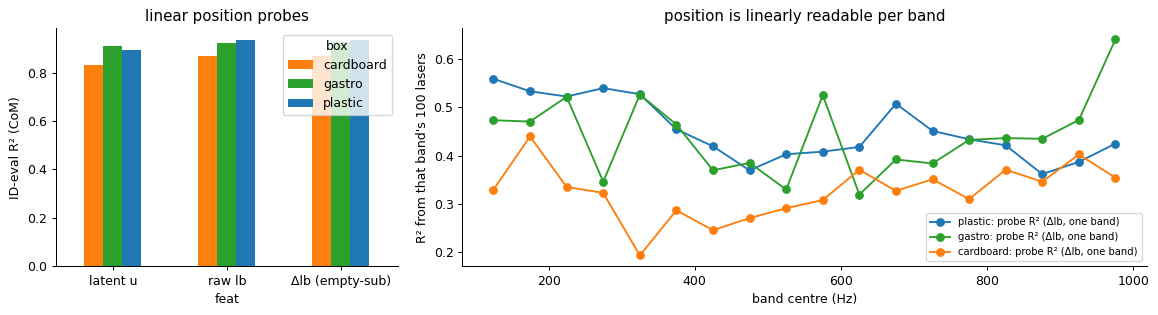

box              cardboard  gastro  plastic
feat                                       
latent u             0.830   0.911    0.896
raw lb               0.868   0.924    0.934
Δlb (empty-sub)      0.869   0.927    0.936
Spearman(band probe R², band occlusion ΔIoU) per box: [np.float64(-0.11), np.float64(0.54), np.float64(0.42)]


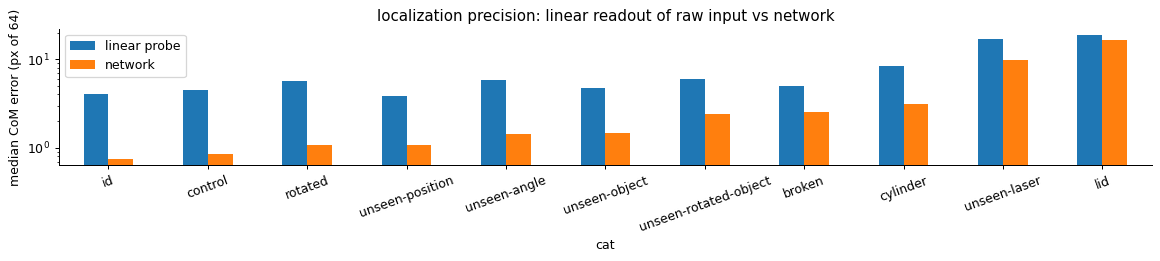

cat           broken  control  cylinder    id    lid  rotated  unseen-angle  unseen-laser  unseen-object  unseen-position  unseen-rotated-object
linear probe    4.98     4.44      8.46  4.04  18.90     5.75          5.82         16.84           4.78             3.90                   5.93
network         2.52     0.85      3.16  0.75  16.62     1.07          1.45          9.72           1.47             1.08                   2.43


In [13]:
from sklearn.linear_model import RidgeCV
LBE = {(b, s): LB[emp & (df.box == b).values & (df.spk == s).values].mean(0) for b, s in ref}
DLB = LB.copy(); DLB[ok] = LB[ok] - np.stack([LBE[b, s] for b, s in zip(df.box[ok], df.spk[ok])])
one = ok & (df.n_obj == 1).values
idev = (df.cat == "id").values
def probe(X, b, tr=TR, te=idev):
    a, t = tr & one & (df.box == b).values, te & one & (df.box == b).values
    mu, sd = X[a].mean(0), X[a].std(0) + 1e-6
    m = RidgeCV(alphas=np.logspace(-1, 5, 13)).fit((X[a] - mu) / sd, df.loc[a, ["r", "c"]].values)
    yp, yt = m.predict((X[t] - mu) / sd), df.loc[t, ["r", "c"]].values
    return 1 - ((yp - yt) ** 2).sum(0) / ((yt - yt.mean(0)) ** 2).sum(0)
rows = []
for b in ("gastro", "plastic", "cardboard"):
    for nm, X in (("raw lb", LB.reshape(N, -1)), ("Δlb (empty-sub)", DLB.reshape(N, -1)), ("latent u", U)): rows.append(dict(box=b, feat=nm, **dict(zip(("R2 row", "R2 col"), probe(X, b)))))
    for k in range(18): rows.append(dict(box=b, feat=f"band{k}", **dict(zip(("R2 row", "R2 col"), probe(DLB[:, :, k], b)))))
R3 = pd.DataFrame(rows); R3["R2"] = R3[["R2 row", "R2 col"]].mean(1)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1, 2]))
pv = R3[~R3.feat.str.startswith("band")].pivot(index="feat", columns="box", values="R2"); pv.plot.bar(ax=ax[0], rot=0, color=[BOXC[c] for c in pv.columns]); ax[0].set(ylabel="ID-eval R² (CoM)", title="linear position probes")
for b, col in BOXC.items():
    r = R3[(R3.box == b) & R3.feat.str.startswith("band")]; ax[1].plot(HZ, r.R2.clip(-.2), "o-", c=col, label=f"{b}: probe R² (Δlb, one band)")
ax[1].set(xlabel="band centre (Hz)", ylabel="R² from that band's 100 lasers", title="position is linearly readable per band"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show(); print(pv.round(3).to_string())
imp = np.array([[d(f"band{k}", ev & (sub.box == b).values) for k in range(18)] for b in ("gastro", "plastic", "cardboard")])
r2b = np.array([R3[(R3.box == b) & R3.feat.str.startswith("band")].R2.values for b in ("gastro", "plastic", "cardboard")])
print("Spearman(band probe R², band occlusion ΔIoU) per box:", [round(stats.spearmanr(a, c)[0], 2) for a, c in zip(r2b, imp)])
# precision: a linear readout of the raw levels vs the network, CoM error in px (64 px = box side), every eval category
rows = []
for b in ("gastro", "plastic", "cardboard"):
    a, t = TR & one & (df.box == b).values, EV & one & (df.box == b).values
    X = LB.reshape(N, -1); mu, sd = X[a].mean(0), X[a].std(0) + 1e-6
    yp = RidgeCV(alphas=np.logspace(-1, 5, 13)).fit((X[a] - mu) / sd, df.loc[a, ["r", "c"]].values).predict((X[t] - mu) / sd)
    e3 = df[t].copy(); e3["linear probe"] = np.hypot(*(yp - e3[["r", "c"]].values).T); e3["network"] = np.hypot(e3.r - e3.pr, e3.c - e3.pc); rows.append(e3)
e3 = pd.concat(rows).groupby("cat")[["linear probe", "network"]].median()
fig, ax = plt.subplots(figsize=(13, 3)); e3.sort_values("network").plot.bar(ax=ax, rot=20, logy=True); ax.set(ylabel="median CoM error (px of 64)", title="localization precision: linear readout of raw input vs network"); plt.tight_layout(); plt.show()
print(e3.round(2).T.to_string())

**Answer.** Position is not hidden. A ridge probe on the raw 100×18 per-laser band levels reaches CoM R² .87–.93 on ID eval, as high as the same probe on the latent (.83–.91). Subtracting the empty box adds nothing (.869 vs .868); a per-box linear model absorbs the baseline.
- **Every single band carries position** (R² .2–.64 from its 100 lasers alone), as expected when every mode shape samples the object location.
- **Probe R² agrees with band occlusion importance** in gastro and plastic (ρ .54 / .42) but not in cardboard (−.11).
- **The network's gain is precision, not detection.** Median CoM error is 0.75 px for the network vs 4.0 px for the linear readout on ID (5.4× better), 1.1 vs 3.9 px on unseen positions, and 1.5 vs 4.8 px on unseen objects. When the spatial code itself is broken (shifted lasers, lid), both fail (10–17 px).

## Q4 · What is the geometry of the latent?
Which nuisance and task factors are linearly present in `u` (probes: box, speaker, object classification accuracy; CoM R²), its PCA spectrum and participation ratio PR = (Σλ)²/Σλ², and — causally — the eval IoU when `u` is projected onto its top-k training PCs before decoding.

         input lb (PCA256)  latent u
box                  1.000     1.000
speaker              0.988     0.991
object               0.859     0.992 
chance: box .33, speaker .25


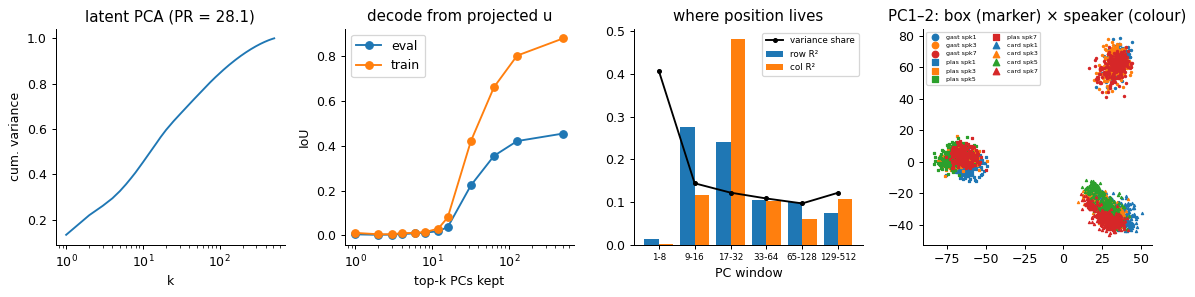

share of u variance explained by group means: {'box': np.float32(0.215), 'box×speaker': np.float32(0.382), 'box×object': np.float32(0.336), 'box×speaker×object': np.float32(0.538)}
position R² by PC window (row, col): {'1-8': [0.01, 0.0], '9-16': [0.28, 0.12], '17-32': [0.24, 0.48], '33-64': [0.1, 0.1], '65-128': [0.1, 0.06], '129-512': [0.08, 0.11]}
PR 28.1 | |ρ| of PC1..8 with (row, col): [[0.03, 0.06], [0.02, 0.01], [0.07, 0.03], [0.09, 0.04], [0.1, 0.05], [0.06, 0.02], [0.1, 0.0], [0.04, 0.01]]


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
def clf(X, y, tr=TR, te=EV):
    mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-6
    m = LogisticRegression(max_iter=300, C=0.1).fit((X[tr] - mu) / sd, y[tr]); return (m.predict((X[te] - mu) / sd) == y[te]).mean()
Xin = PCA(256, random_state=0).fit(LB.reshape(N, -1)[TR]).transform(LB.reshape(N, -1))
spk4 = df.spk.isin([1, 3, 5, 7]).values
fac = {}
for nm, X in (("input lb (PCA256)", Xin), ("latent u", U)):
    fac[nm] = dict(box=clf(X, df.box.values), speaker=clf(X, df.spk.values, TR & spk4, EV & spk4), object=clf(X, df.obj.values, TR, EV & (df.cat == "id").values))
print(pd.DataFrame(fac).round(3).to_string(), "\nchance: box .33, speaker .25")
pca = PCA(512).fit(U[TR]); lam = pca.explained_variance_; PR = lam.sum() ** 2 / (lam ** 2).sum()
Z = pca.transform(U)
ks = [1, 2, 3, 4, 6, 8, 12, 16, 32, 64, 128, 512]
fig, ax = plt.subplots(1, 4, figsize=(13, 3.4))
ax[0].semilogx(np.arange(1, 513), np.cumsum(lam) / lam.sum()); ax[0].set(xlabel="k", ylabel="cum. variance", title=f"latent PCA (PR = {PR:.1f})")
ax[1].semilogx(ks, [I[f"pc{k}"][ev].mean() for k in ks], "o-", label="eval"); ax[1].semilogx(ks, [I[f"pc{k}"][~ev].mean() for k in ks], "o-", label="train")
ax[1].set(xlabel="top-k PCs kept", ylabel="IoU", title="decode from projected u"); ax[1].legend()
W4 = [(0, 8), (8, 16), (16, 32), (32, 64), (64, 128), (128, 512)]; pr2 = []
for lo, hi in W4:  # position R² (ID eval) from one window of PCs only
    a, t = TR & one, EV & one & (df.cat == "id").values
    yp = RidgeCV(alphas=np.logspace(-2, 4, 7)).fit(Z[a, lo:hi], df.loc[a, ["r", "c"]].values).predict(Z[t, lo:hi]); yt = df.loc[t, ["r", "c"]].values
    pr2.append(1 - ((yp - yt) ** 2).sum(0) / ((yt - yt.mean(0)) ** 2).sum(0))
lab = [f"{lo + 1}-{hi}" for lo, hi in W4]; pr2 = np.array(pr2)
ax[2].bar(np.arange(6) - .2, pr2[:, 0], .4, label="row R²"); ax[2].bar(np.arange(6) + .2, pr2[:, 1], .4, label="col R²")
ax[2].plot(range(6), [pca.explained_variance_ratio_[lo:hi].sum() for lo, hi in W4], "k.-", label="variance share"); ax[2].set_xticks(range(6), lab, fontsize=7); ax[2].set(xlabel="PC window", title="where position lives"); ax[2].legend(fontsize=7)
m = TR & one; s = np.random.default_rng(0).choice(np.nonzero(m)[0], 3000, replace=False)
for b, mk in zip(("gastro", "plastic", "cardboard"), ("o", "s", "^")):
    for sp_ in (1, 3, 5, 7):
        mm = s[(df.box.values[s] == b) & (df.spk.values[s] == sp_)]; ax[3].scatter(Z[mm, 0], Z[mm, 1], s=3, marker=mk, c=f"C{sp_ // 2}", label=f"{b[:4]} spk{sp_}" if len(mm) else None)
ax[3].legend(markerscale=3, fontsize=5, ncol=2); ax[3].set_title("PC1–2: box (marker) × speaker (colour)")
plt.tight_layout(); plt.show()
Uc = U - U[TR].mean(0); tot = (Uc[TR] ** 2).sum()
print("share of u variance explained by group means:", {nm: round(((pd.DataFrame(Uc[TR]).groupby(k.values[TR]).transform("mean").values) ** 2).sum() / tot, 3)
      for nm, k in (("box", df.box), ("box×speaker", df.box + df.spk.astype(str)), ("box×object", df.box + df.obj), ("box×speaker×object", df.box + df.spk.astype(str) + df.obj))})
print("position R² by PC window (row, col):", dict(zip(lab, pr2.round(2).tolist())))
cor = [[abs(stats.spearmanr(Z[m, k], df.loc[m, f])[0]) for f in ("r", "c")] for k in range(8)]
print("PR", round(PR, 1), "| |ρ| of PC1..8 with (row, col):", np.round(cor, 2).tolist())

**Answer.** `u` is first a *context* code and only second a position code.
- **Context dominates.** Box, speaker and object are all linearly decodable at ≥ 99% (box 100%, speaker 99.1%, object 99.2%). Group means of box×speaker×object explain 54% of latent variance (box alone 21%).
- **Speaker is not removed.** It is as decodable from `u` as from the input (.991 vs .988). Object identity, by contrast, is *created* by the encoder (.86 → .99).
- **Position lives in mid-variance directions.** The top 8 PCs (41% of variance) carry zero position information (R² .01). Position lives in PCs 9–32 (R² up to .48), and decoding from the top 16 PCs gives IoU .04.
- **Memorization in the tail.** The decoder needs ~64–128 dims (eval .36 / .42 of .455). The last 384 low-variance PCs lift train IoU .80 → .88 but eval only .42 → .455. That is where the train-specific detail (memorization; train .89 vs eval .60) lives. Participation ratio 28.

## Q5 · Interpolation or lookup?
Two oracles that know the training set: copy the training mask whose **latent** is nearest (same box), and copy the training mask whose **input** (Δ`lb`, standardized) is nearest. If the model ≈ latent-NN, the decoder is a lookup table over training positions; if model > latent-NN, it interpolates. Also: IoU vs the distance from an eval object's CoM to the nearest training CoM of the same object in the same box (how far it must extrapolate).

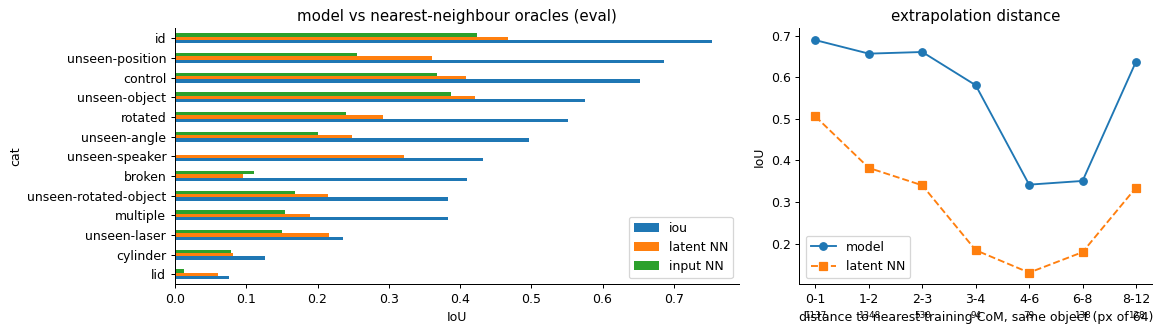

           iou       latent NN      
          mean  size      mean  size
dtrain                              
(0, 1]   0.689  1137     0.505  1137
(1, 2]   0.657  1348     0.382  1348
(2, 3]   0.661   530     0.340   530
(3, 4]   0.581    94     0.184    94
(4, 6]   0.342    79     0.130    79
(6, 8]   0.350   138     0.179   138
(8, 12]  0.637   128     0.334   128
                         iou  latent NN  input NN
cat                                              
broken                 0.410      0.095     0.111
control                0.652      0.409     0.368
cylinder               0.126      0.082     0.078
id                     0.754      0.468     0.424
lid                    0.076      0.061     0.012
multiple               0.383      0.189     0.154
rotated                0.552      0.292     0.240
unseen-angle           0.497      0.248     0.200
unseen-laser           0.236      0.216     0.150
unseen-object          0.575      0.421     0.387
unseen-position        0.686  

In [15]:
from sklearn.neighbors import NearestNeighbors
res = []
Xd = DLB.reshape(N, -1); Xd = np.nan_to_num(Xd)
for b in ("gastro", "plastic", "cardboard"):
    tb, eb = np.nonzero(TR & (df.box == b).values)[0], np.nonzero(EV & (df.box == b).values)[0]
    for nm, X in (("latent NN", U), ("input NN", Xd)):
        mu, sd = X[tb].mean(0), X[tb].std(0) + 1e-6
        j = tb[NearestNeighbors(n_neighbors=1).fit((X[tb] - mu) / sd).kneighbors((X[eb] - mu) / sd)[1][:, 0]]
        df.loc[eb, nm] = (Y[j] & Y[eb]).sum((1, 2)) / np.maximum((Y[j] | Y[eb]).sum((1, 2)), 1)
        if nm == "latent NN": df.loc[eb, "knn_u"] = NearestNeighbors(n_neighbors=10).fit((X[tb] - mu) / sd).kneighbors((X[eb] - mu) / sd)[0].mean(1)
        else: df.loc[eb, "knn_x"] = NearestNeighbors(n_neighbors=10).fit((X[tb] - mu) / sd).kneighbors((X[eb] - mu) / sd)[0].mean(1)
# distance to nearest training CoM of the same object in the same box
tr1 = df[TR & one]
df["dtrain"] = np.nan
for (b, o), g in df[EV & one].groupby(["box", "obj"]):
    t = tr1[(tr1.box == b) & (tr1.obj == o)]
    if len(t): df.loc[g.index, "dtrain"] = NearestNeighbors(n_neighbors=1).fit(t[["r", "c"]].values).kneighbors(g[["r", "c"]].values)[0][:, 0]
e = df[EV]
tab = e.groupby("cat")[["iou", "latent NN", "input NN"]].mean().round(3)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
tab.sort_values("iou").plot.barh(ax=ax[0]); ax[0].set(xlabel="IoU", title="model vs nearest-neighbour oracles (eval)")
seen = e[e.dtrain.notna()]; bins = [0, 1, 2, 3, 4, 6, 8, 12, 20, 40]
q = seen.groupby(pd.cut(seen.dtrain, bins))[["iou", "latent NN"]].agg(["mean", "size"])
x = [f"{i.left}-{i.right}" for i in q.index]
ax[1].plot(x, q[("iou", "mean")], "o-", label="model"); ax[1].plot(x, q[("latent NN", "mean")], "s--", label="latent NN")
for xi, n in zip(x, q[("iou", "size")]): ax[1].text(xi, .02, n, ha="center", fontsize=7)
ax[1].set(xlabel="distance to nearest training CoM, same object (px of 64)", ylabel="IoU", title="extrapolation distance"); ax[1].legend()
plt.tight_layout(); plt.show()
print(q.round(3).to_string()); print(tab.to_string()); print("all eval:", e[["iou", "latent NN", "input NN"]].mean().round(3).to_dict(), "| model > latentNN on", (e.iou > e["latent NN"]).mean().round(3))

**Answer.** The model interpolates.
- **It beats both oracles.** Model eval IoU is .596, vs .372 for copying the nearest training mask in latent space and .324 in input space. It beats the latent-NN oracle on 81% of samples.
- **Unseen positions:** .686 vs .360.
- **Interpolation radius.** IoU is flat (.66–.69) up to 3 px (~5% of the box) from the nearest training CoM of that object, then drops to ~.34 at 4–8 px. The NN oracle falls off much faster (.51 → .13).
- **Unseen speaker exposes the input space.** Input-space neighbours give **0.000**: a new speaker moves a scan so far that its nearest training inputs are not even the right scene. Latent neighbours recover .32. So the encoder *does* align speakers at the neighbourhood level, even though speaker stays linearly decodable (Q4).

## Q6 · What predicts per-sample success?
Gradient-boosted regression of per-sample eval IoU from properties of the data and of the model's state, evaluated with grouped 5-fold CV (groups = position, so no speaker-twin leakage). Permutation importance on held-out folds; marginal Spearman ρ alongside.

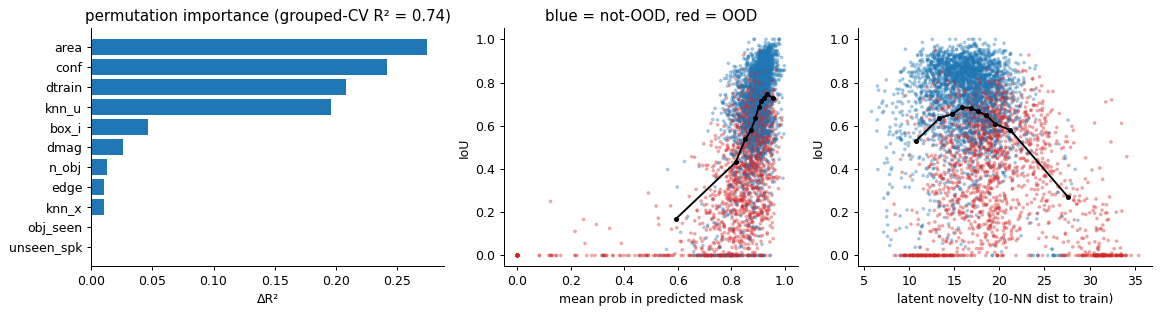

grouped-CV R² 0.739
             perm    rho
unseen_spk  0.000 -0.084
obj_seen    0.000  0.129
knn_x       0.010 -0.164
edge        0.010 -0.031
n_obj       0.013 -0.245
dmag        0.026  0.096
box_i       0.047 -0.169
knn_u       0.196 -0.223
dtrain      0.209 -0.183
conf        0.242  0.553
area        0.275  0.327


In [16]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
e = df[EV].copy()
e["box_i"] = e.box.map({"gastro": 0, "plastic": 1, "cardboard": 2}); e["unseen_spk"] = (e.spk == 4).astype(int)
e["obj_seen"] = e.obj.isin(INFO["objects"][:-1]).astype(int)
F6 = ["area", "n_obj", "edge", "dmag", "knn_u", "knn_x", "dtrain", "conf", "box_i", "unseen_spk", "obj_seen"]
X6, y6, grp = e[F6].values, e.iou.values, (e.exp + e.pos.astype(str)).values
pred, PI = np.zeros(len(e)), []
for a, t in GroupKFold(5).split(X6, y6, grp):
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=.05, random_state=0).fit(X6[a], y6[a]); pred[t] = m.predict(X6[t])
    PI.append(permutation_importance(m, X6[t], y6[t], n_repeats=5, random_state=0).importances_mean)
r2 = 1 - ((pred - y6) ** 2).sum() / ((y6 - y6.mean()) ** 2).sum()
imp6 = pd.DataFrame(dict(perm=np.mean(PI, 0), rho=[stats.spearmanr(e[f], e.iou, nan_policy="omit")[0] for f in F6]), index=F6).sort_values("perm")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
ax[0].barh(imp6.index, imp6.perm, color="C0"); ax[0].set(title=f"permutation importance (grouped-CV R² = {r2:.2f})", xlabel="ΔR²")
for a, f, lab in ((ax[1], "conf", "mean prob in predicted mask"), (ax[2], "knn_u", "latent novelty (10-NN dist to train)")):
    a.scatter(e[f], e.iou, s=4, alpha=.3, c=e.ood.map({True: "C3", False: "C0"})); a.set(xlabel=lab, ylabel="IoU")
    b = e.groupby(pd.qcut(e[f], 10, duplicates="drop")).agg(x=(f, "mean"), y=("iou", "mean")); a.plot(b.x, b.y, "k-o", ms=3)
ax[1].set_title("blue = not-OOD, red = OOD"); plt.tight_layout(); plt.show()
print("grouped-CV R²", round(r2, 3)); print(imp6.round(3).to_string())

**Answer.** Per-sample IoU is predictable (grouped-CV R² .74).
- **Strongest predictors:** true object area (perm. importance .28; small objects fail), the model's own mask confidence (.24, ρ .55), distance to the nearest training position of that object (.21), and latent novelty (.20).
- **Weak or no effect:**
  - Distance to the box edge has ~no effect (.01, ρ −.03), consistent with nb95 (edges are not weaker).
  - Raw-input novelty adds little (.01): what matters is how novel a sample looks *after* the encoder.
  - The unseen-speaker flag adds nothing once latent novelty is known.
  - Number of objects is weak (.013) but ρ −.25: multi-object scenes are worse, mostly through the second object.

## Q7 · Does the model know when it fails?
Failure = IoU < 0.3 on eval samples with an object. Scores: mask confidence (mean p inside the predicted mask), predicted area, latent novelty, input novelty, object-head max-softmax. AUROC per score, and the risk–coverage curve when abstaining on the least-confident samples. Also IoU vs threshold for ID and OOD: is .08 a calibration fix for OOD under-confidence?

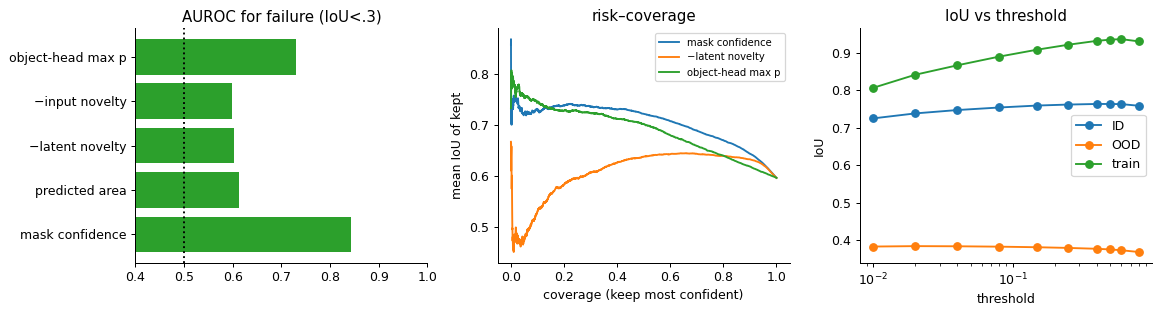

{'mask confidence': 0.843, 'predicted area': 0.613, '−latent novelty': 0.603, '−input novelty': 0.598, 'object-head max p': 0.73} | fail rate 0.167


ID IoU at [0.01, 0.02, 0.04, 0.08, 0.15, 0.25, 0.4, 0.5, 0.6, 0.8] [np.float64(0.725), np.float64(0.739), np.float64(0.748), np.float64(0.754), np.float64(0.76), np.float64(0.762), np.float64(0.764), np.float64(0.764), np.float64(0.764), np.float64(0.759)]
OOD IoU at [0.01, 0.02, 0.04, 0.08, 0.15, 0.25, 0.4, 0.5, 0.6, 0.8] [np.float64(0.383), np.float64(0.384), np.float64(0.384), np.float64(0.383), np.float64(0.381), np.float64(0.379), np.float64(0.377), np.float64(0.375), np.float64(0.373), np.float64(0.368)]
eval pixel prob histogram [0,.01,.08,.5,.92,1]: [0.9787 0.0026 0.0021 0.0019 0.0146]


In [17]:
from sklearn.metrics import roc_auc_score
e = df[EV].copy(); fail = (e.iou < .3).values
ol = torch.from_numpy(B["obj"][EV]).softmax(-1).numpy(); e["objp"] = ol.max(1)
S7 = {"mask confidence": e.conf, "predicted area": e.parea, "−latent novelty": -e.knn_u, "−input novelty": -e.knn_x, "object-head max p": e.objp}
auc = {k: roc_auc_score(fail, -v) for k, v in S7.items()}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].barh(list(auc), list(auc.values()), color="C2"); ax[0].axvline(.5, c="k", ls=":"); ax[0].set(xlim=(.4, 1), title="AUROC for failure (IoU<.3)")
for k in ("mask confidence", "−latent novelty", "object-head max p"):
    o = np.argsort(-S7[k].values); cov = np.arange(1, len(o) + 1) / len(o); ax[1].plot(cov, np.cumsum(e.iou.values[o]) / np.arange(1, len(o) + 1), label=k)
ax[1].set(xlabel="coverage (keep most confident)", ylabel="mean IoU of kept", title="risk–coverage"); ax[1].legend(fontsize=8)
th = [.01, .02, .04, .08, .15, .25, .4, .5, .6, .8]
for nm, m in (("ID", (df.cat == "id").values & EV), ("OOD", df.ood.values & EV), ("train", TR & (df.area > 0).values)):
    ax[2].plot(th, [np.mean(((P[m] > t) & Y[m]).sum((1, 2)) / np.maximum(((P[m] > t) | Y[m]).sum((1, 2)), 1)) for t in th], "o-", label=nm)
ax[2].set(xscale="log", xlabel="threshold", ylabel="IoU", title="IoU vs threshold"); ax[2].legend()
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in auc.items()}, "| fail rate", fail.mean().round(3))
for nm, m in (("ID", (df.cat == "id").values & EV), ("OOD", df.ood.values & EV)): print(nm, "IoU at", th, [round(np.mean(((P[m] > t) & Y[m]).sum((1, 2)) / np.maximum(((P[m] > t) | Y[m]).sum((1, 2)), 1)), 3) for t in th])
hist = np.histogram(P[EV & (df.area > 0).values].ravel(), bins=[0, .01, .08, .5, .92, 1.01])[0]; print("eval pixel prob histogram [0,.01,.08,.5,.92,1]:", (hist / hist.sum()).round(4))

**Answer.** Partly. **Mask confidence** detects failures (IoU < .3, 16.7% of eval) with AUROC .84, the object head's max-p with .73, and latent / input novelty only with ~.60. Abstaining on the least-confident 20% lifts mean IoU from .596 to .670 (risk–coverage curve).
- **The masks are almost binary.** 97.9% of eval pixels are < .01, 1.5% are > .92, and only 0.7% are in between. The model is decisive even when it is wrong, so its confidence lives in *how much* it paints, not in soft edges.
- **The threshold therefore barely matters.** ID IoU goes .725 @ .01 → .754 @ .08 → .764 @ .5; OOD is flat at .38 across .01–.25. The .08 goal threshold is not compensating for OOD under-confidence; ID would gain +.01 at .4–.5.

## Q8 · How invariant is it to the speaker (excitation) and to noise?
The measured spectrum is X(f) = S(f)·H_box(f; object)·sensor(f): the speaker response S(f) multiplies everything and is the main nuisance. (a) Variance decomposition at positions recorded with all four training speakers: fraction of variance between positions vs within position (across speakers), in the input and in `u`. (b) Test-time random smooth speaker responses (log-gain sd, knot spacing 20 Hz; 5 Hz = ragged, 80 Hz = smooth tilt) and additive noise at a given SNR.

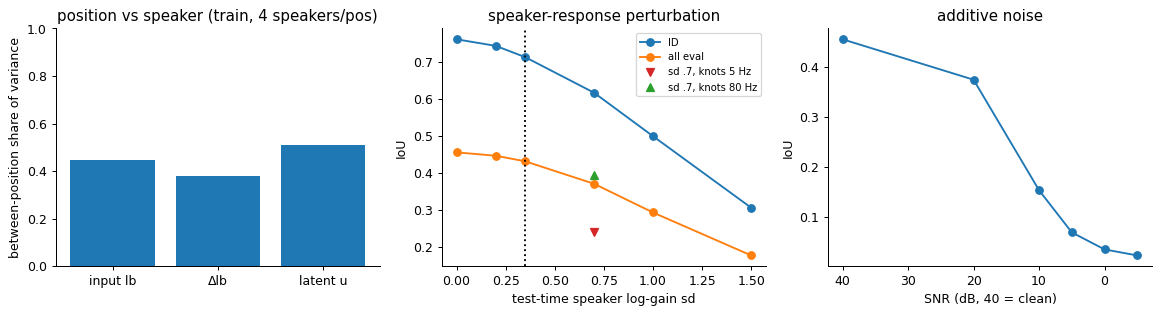

{'input lb': np.float32(0.447), 'Δlb': np.float32(0.378), 'latent u': np.float32(0.512)} {'clean': np.float32(0.455), 'sg0.35': np.float32(0.43), 'sg0.7': np.float32(0.37), 'sgHz5.0': np.float32(0.239), 'sgHz80.0': np.float32(0.393), 'snr10': np.float32(0.154), 'snr0': np.float32(0.036), 'gain_global': np.float32(0.455)}
gastro    unseen spk IoU 0.187 vs baseline 0.658 | latent novelty 28.0 vs 15.7 | input novelty 59.3 vs 19.7
plastic   unseen spk IoU 0.650 vs baseline 0.741 | latent novelty 23.2 vs 18.5 | input novelty 44.4 vs 25.7
cardboard unseen spk IoU 0.414 vs baseline 0.666 | latent novelty 24.6 vs 17.5 | input novelty 62.2 vs 24.5


In [18]:
def icc(X, m):
    g = df[m].groupby(["exp", "pos"]).spk.transform("nunique") == 4; idx = np.nonzero(m)[0][g.values]
    keys = (df.exp + df.pos.astype(str)).values[idx]; Xs = (X[idx] - X[idx].mean(0)) / (X[idx].std(0) + 1e-6)
    mu = pd.DataFrame(Xs).groupby(keys).transform("mean").values
    return ((mu - Xs.mean(0)) ** 2).sum() / ((Xs - Xs.mean(0)) ** 2).sum()
m8 = TR & (df.n_obj == 1).values
V8 = {nm: icc(X, m8) for nm, X in (("input lb", LB.reshape(N, -1)), ("Δlb", np.nan_to_num(DLB.reshape(N, -1))), ("latent u", U))}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].bar(list(V8), list(V8.values()), color="C0"); ax[0].set(ylim=(0, 1), ylabel="between-position share of variance", title="position vs speaker (train, 4 speakers/pos)")
sg = [0, .2, .35, .7, 1.0, 1.5]
for nm, m in (("ID", (sub.cat == "id").values), ("all eval", ev)): ax[1].plot(sg, [I["clean"][m].mean()] + [I[f"sg{s}"][m].mean() for s in sg[1:]], "o-", label=nm)
ax[1].plot([.7], [I["sgHz5.0"][ev].mean()], "v", c="C3", label="sd .7, knots 5 Hz"); ax[1].plot([.7], [I["sgHz80.0"][ev].mean()], "^", c="C2", label="sd .7, knots 80 Hz")
ax[1].axvline(.35, c="k", ls=":"); ax[1].set(xlabel="test-time speaker log-gain sd", ylabel="IoU", title="speaker-response perturbation"); ax[1].legend(fontsize=8)
snr = [40, 20, 10, 5, 0, -5]
ax[2].plot(snr, [I["clean"][ev].mean()] + [I[f"snr{s}"][ev].mean() for s in snr[1:]], "o-"); ax[2].invert_xaxis(); ax[2].set(xlabel="SNR (dB, 40 = clean)", ylabel="IoU", title="additive noise")
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in V8.items()}, {k: round(I[k][ev].mean(), 3) for k in ["clean", "sg0.35", "sg0.7", "sgHz5.0", "sgHz80.0", "snr10", "snr0", "gain_global"]})
# unseen speaker: how far is speaker 4 from the training manifold, vs the same positions with training speakers
for b, nm in (("gastro", "cube"), ("plastic", "cube"), ("cardboard", "vase")):
    u4, ub = df[df.split == f"eval/{b}/{nm}-unseen-speaker-unseen"], df[df.split == f"eval/{b}/{nm}-unseen-speaker-baseline"]
    print(f"{b:9s} unseen spk IoU {u4.iou.mean():.3f} vs baseline {ub.iou.mean():.3f} | latent novelty {u4.knn_u.mean():.1f} vs {ub.knn_u.mean():.1f} | input novelty {u4.knn_x.mean():.1f} vs {ub.knn_x.mean():.1f}")

**Answer.** It is only partly speaker-invariant.
- **Variance share.** At positions recorded with all 4 training speakers, between-position variance is 45% of the input and only 51% of the latent: the encoder raises the position share by just 6 pp, and half the latent variance is still speaker.
- **Test-time speaker response.** At the training level (log-gain sd .35) IoU drops .455 → .430; at sd .7 to .37, at sd 1.0 to .29. *Ragged* responses hurt far more than smooth ones at the same sd: knots every 5 Hz give .24, every 80 Hz give .39. The model tolerates spectral tilt but not ripple on the scale of modal linewidths, which is exactly where it reads the signal (Q1).
- **Noise.** It is very noise-sensitive: 20 dB SNR → .37, 10 dB → .15. The object information sits only ~10–20 dB above the floor, consistent with signal ≈ 1.3–2.8× the repeat noise (Q2).
- **Unseen speaker 4.** It moves the input 2.4–3× further from the training set, but the latent only 1.3–1.8× further. Gastro fails worst (IoU .19 vs .66 baseline) and has the largest input (3.0×) and latent (1.8×) shift. Plastic barely moves (1.25×) and keeps .65.

## Q9 · How does the laser array encode space?
Per-laser occlusion maps (10×10), redundancy (random k of 100 lasers dropped), grid shift (bilinear resample of the laser field by U(−s, s) cells), mirroring the grid (does the predicted blob mirror?), and the real shifted-laser captures.

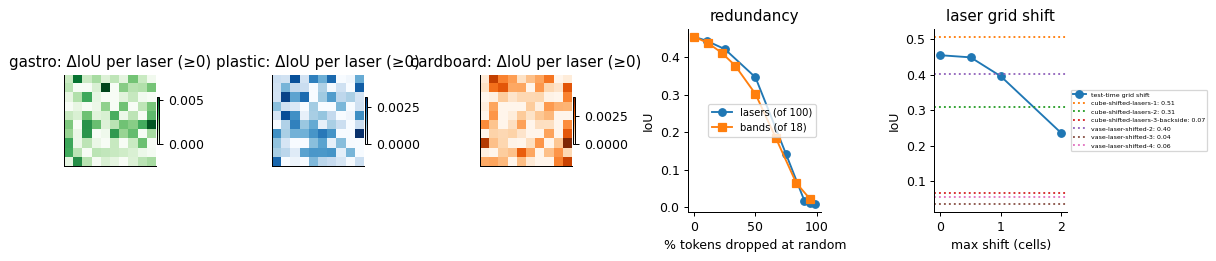

flip_lr IoU 0.066 | corr(pred row, clean row) 0.25 | corr(pred col, clean col) 0.11
flip_ud IoU 0.075 | corr(pred row, clean row) 0.23 | corr(pred col, clean col) 0.22
ρ(importance-weighted laser row/col, object row/col): {'lrow~r': np.float64(0.03), 'lrow~c': np.float64(-0.01), 'lcol~r': np.float64(0.01), 'lcol~c': np.float64(0.07)} n = 1511
single laser max mean ΔIoU 0.0028 | rows [np.float32(0.019), np.float32(0.014), np.float32(0.011), np.float32(0.013), np.float32(0.01), np.float32(0.012), np.float32(0.014), np.float32(0.013), np.float32(0.012), np.float32(0.009)] | cols [np.float32(0.012), np.float32(0.015), np.float32(0.014), np.float32(0.009), np.float32(0.013), np.float32(0.012), np.float32(0.013), np.float32(0.011), np.float32(0.008), np.float32(0.019)]


In [19]:
L = np.stack([I["clean"] - I[f"laser{l}"] for l in range(100)], 1)            # (n_sub,100) ΔIoU per laser
fig, ax = plt.subplots(1, 5, figsize=(13, 3.0), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.4, 1.4]))
for a, b in zip(ax[:3], ("gastro", "plastic", "cardboard")):
    heat(a, L[ev & (sub.box == b).values].mean(0).reshape(10, 10), b); a.set_aspect("equal"); a.set_title(f"{b}: ΔIoU per laser (≥0)"); a.set_xticks([]); a.set_yticks([])
ks = [0, 10, 25, 50, 75, 90, 95, 99]
ax[3].plot(ks, [I["clean"][ev].mean()] + [I[f"rl{k}"][ev].mean() for k in ks[1:]], "o-", label="lasers (of 100)")
kb = [0, 2, 4, 6, 9, 12, 15, 17]; ax[3].plot(np.array(kb) / 18 * 100, [I["clean"][ev].mean()] + [I[f"rb{k}"][ev].mean() for k in kb[1:]], "s-", label="bands (of 18)")
ax[3].set(xlabel="% tokens dropped at random", ylabel="IoU", title="redundancy"); ax[3].legend(fontsize=8)
js = [0, 0.5, 1.0, 2.0]; ax[4].plot(js, [I["clean"][ev].mean()] + [I[f"jit{s}"][ev].mean() for s in js[1:]], "o-", label="test-time grid shift")
sl = df[df.name.str.contains("shift") & EV].groupby("name").iou.mean();
for i, (k, v) in enumerate(sl.items()): ax[4].axhline(v, ls=":", c=f"C{i + 1}", label=f"{k}: {v:.2f}")
ax[4].set(xlabel="max shift (cells)", ylabel="IoU", title="laser grid shift"); ax[4].legend(fontsize=5, loc="center left", bbox_to_anchor=(1, .5))
plt.tight_layout(); plt.show()
# mirror test: flip the grid's columns / rows -> where does the blob go?
Cc, Cf, Cu = A["com"][names.index("clean")], A["com"][names.index("flip_lr")], A["com"][names.index("flip_ud")]
for nm, Cx in (("flip_lr", Cf), ("flip_ud", Cu)):
    print(nm, "IoU", I[nm][ev].mean().round(3), "| corr(pred row, clean row)", np.corrcoef(Cx[ev, 0], Cc[ev, 0])[0, 1].round(2), "| corr(pred col, clean col)", np.corrcoef(Cx[ev, 1], Cc[ev, 1])[0, 1].round(2))
# does the important laser sit near the object? importance-weighted laser (row, col) vs object CoM
w = L.clip(0); lr, lc = np.divmod(np.arange(100), 10); m = ev & (w.sum(1) > .02)
wr, wc = (w * lr).sum(1)[m] / w.sum(1)[m], (w * lc).sum(1)[m] / w.sum(1)[m]
print("ρ(importance-weighted laser row/col, object row/col):", {f"{a}~{b}": round(stats.spearmanr(x, sub[b].values[m])[0], 2) for a, x in (("lrow", wr), ("lcol", wc)) for b in ("r", "c")}, "n =", m.sum())
print("single laser max mean ΔIoU", L[ev].mean(0).max().round(4), "| rows", [round(d(f'lrow{k}'), 3) for k in range(10)], "| cols", [round(d(f'lcol{k}'), 3) for k in range(10)])

**Answer.** The array works as a *fixed-sensor fingerprint*, not as an image of the floor.
- **No single laser matters.** The best single laser is worth ≤ .003 IoU (noise level), and a whole row or column .008–.019.
- **Graceful degradation.** Random dropout of 25% / 50% / 75% of lasers gives .42 / .35 / .14 (clean .455); bands behave the same. Training-time token dropout buys this.
- **Laser placement must be exact.** A ±.5-cell grid shift (the training augmentation) is free, ±1 cell costs −.06 and ±2 cells −.22. The real shifted-laser captures score .51 / .31 / .07 (plastic) and .40 / .04 / .06 (cardboard).
- **No mirror equivariance.** Mirroring the grid left-right or up-down does *not* mirror the prediction: IoU .07, and the predicted CoM is barely correlated with the clean one (ρ .1–.25).
- **Non-local coding.** The importance-weighted laser position is uncorrelated with the object position (|ρ| ≤ .07): no "nearest laser" sees the object. All of this fits modal physics. The wall lasers sample global box modes that an object anywhere on the floor perturbs. Position is a pattern over all lasers, read through per-laser weights (rope position + one flatten-readout slot per laser). It is not a local dip that could translate.

## Q10 · What happens off-distribution?
Per eval split: mean latent novelty vs mean IoU (does distance from the training manifold explain split-level failure?), which training class the object head assigns to unseen objects, and predicted vs true mask area per object (does the model paint a *size* or a *class template*?).

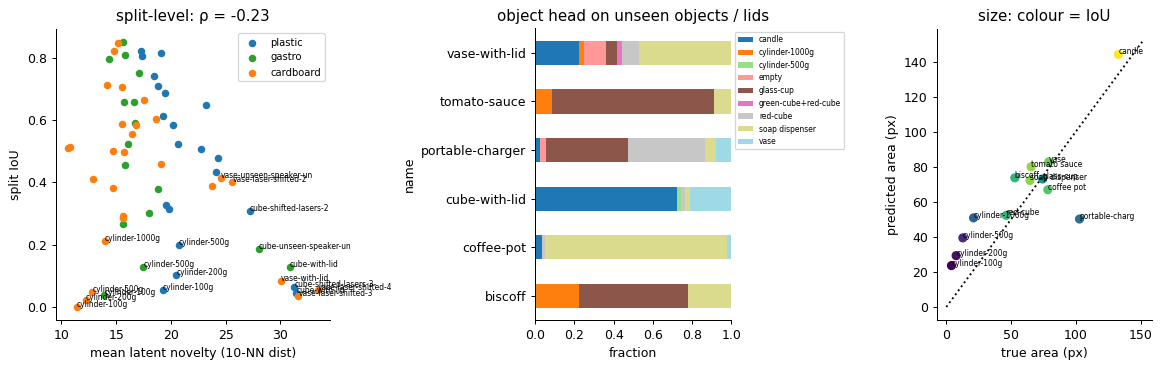

split-level ρ(novelty, IoU) -0.233 | log-log slope pred vs true area 0.39
head              candle  cylinder-1000g  cylinder-500g  empty  glass-cup  green-cube+red-cube  red-cube  soap dispenser  vase
name                                                                                                                          
biscoff             0.00            0.22           0.00   0.00       0.56                 0.00      0.00            0.22  0.00
coffee-pot          0.03            0.00           0.00   0.00       0.00                 0.00      0.02            0.93  0.02
cube-with-lid       0.72            0.00           0.02   0.00       0.00                 0.00      0.02            0.02  0.21
portable-charger    0.03            0.00           0.00   0.03       0.42                 0.00      0.39            0.05  0.08
tomato-sauce        0.00            0.09           0.00   0.00       0.83                 0.00      0.00            0.09  0.00
vase-with-lid       0.22            0

In [20]:
e = df[EV].copy(); e["head"] = np.array([o or "empty" for o in INFO["objects"][:-1]])[B["obj"][EV].argmax(1)]
sp = e.groupby(["box", "name"]).agg(iou=("iou", "mean"), nov=("knn_u", "mean"), xnov=("knn_x", "mean"), ood=("ood", "first"), area=("area", "mean"), parea=("parea", "mean")).reset_index()
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.4, 1, 1.1]))
for b, col in BOXC.items():
    s = sp[sp.box == b]; ax[0].scatter(s.nov, s.iou, c=col, s=25, label=b)
    for _, r in s[(s.iou < .25) | (s.nov > sp.nov.quantile(.85))].iterrows(): ax[0].annotate(r["name"][:22], (r.nov, r.iou), fontsize=6)
ax[0].set(xlabel="mean latent novelty (10-NN dist)", ylabel="split IoU", title=f"split-level: ρ = {stats.spearmanr(sp.nov, sp.iou)[0]:.2f}"); ax[0].legend(fontsize=8)
un = e[e.name.isin(["coffee-pot", "portable-charger", "biscoff", "tomato-sauce", "cube-with-lid", "vase-with-lid"])]
ct = pd.crosstab(un.name, un["head"], normalize="index"); ct.plot.barh(stacked=True, ax=ax[1], legend=False, colormap="tab20"); ax[1].set(title="object head on unseen objects / lids", xlabel="fraction")
ax[1].legend(fontsize=6, bbox_to_anchor=(1, 1))
o = e[e.n_obj == 1].groupby("obj").agg(a=("area", "mean"), pa=("parea", "mean"), iou=("iou", "mean"))
ax[2].scatter(o.a, o.pa, c=o.iou, cmap="viridis", s=40); [ax[2].annotate(k[:14], (r.a, r.pa), fontsize=6) for k, r in o.iterrows()]
lim = [0, max(o.a.max(), o.pa.max()) * 1.05]; ax[2].plot(lim, lim, "k:"); ax[2].set(xlabel="true area (px)", ylabel="predicted area (px)", title="size: colour = IoU")
plt.tight_layout(); plt.show()
print("split-level ρ(novelty, IoU)", round(stats.spearmanr(sp.nov, sp.iou)[0], 3), "| log-log slope pred vs true area", round(np.polyfit(np.log(o.a), np.log(o.pa), 1)[0], 2))
print(ct.round(2).to_string()); print(o.round(2).sort_values("a").to_string())
# lid: the whole box spectrum moves
for b, a_, b_ in (("gastro", "cube-with-lid", "cube-without-lid"), ("plastic", "cube-with-lid", "cube-without-lid"), ("cardboard", "vase-with-lid", "vase-without-lid")):
    w, wo = df[df.split == f"eval/{b}/{a_}"], df[df.split == f"eval/{b}/{b_}"]
    print(f"{b:9s} lid IoU {w.iou.mean():.3f} vs no-lid {wo.iou.mean():.3f} | latent novelty {w.knn_u.mean():.1f} vs {wo.knn_u.mean():.1f} | rms Δspec vs empty {w.dmag.mean():.3f} vs {wo.dmag.mean():.3f}")

**Answer.** Off-distribution failures come in two kinds, so latent novelty explains split-level IoU only weakly (ρ = −.23).
- **(i) Low-novelty misses.** The cylinders sit at the *lowest* novelty (11–17), yet score IoU ≤ .3: their perturbation is too small to move the scan away from the training distribution, so the model treats them as familiar and mis-sizes them (Q2).
- **(ii) High-novelty global shifts.**
  - The lid changes the box's own resonances: its rms change vs the empty box is 3.4–3.9× an object's (.79 vs .22), latent novelty ~31 vs 16–24, and IoU .04–.13.
  - Shifted lasers and unseen speaker 4 in gastro fall in the same high-novelty group.
- **Unseen objects snap to a training class.**
  - Coffee pot → soap dispenser (93%), IoU .62.
  - Tomato sauce → glass cup (83%), IoU .71.
  - Biscoff → glass cup (56%).
  - Portable charger → glass cup / red cube.
  - The lid → candle (72%).
- **Painted size shrinks toward a prior.** Log-log slope of predicted vs true area is .39: small objects are over-painted (4 px cylinder → 24 px), the 103 px charger is under-painted (50 px), and objects near the class sizes (50–130 px) are right. The model localizes from the vibration and draws a *size/shape prior* inherited from the nearest training class.

## Follow-ups
Three follow-ups to Q1 / Q2 / Q3, on the same fixed sets as Q1 (`subset720.npz`: 60 each of candle / red-cube / soap dispenser / vase per box, **240 per box**, train and ID eval; eager fp32, IoU @ 0.08). They read cached per-sample results only: `q1_{train,eval}.npz` (Q1) and `fq3_*.npz` / `fq2_*.npz` (`scripts/nb136_fq3.py SET`, `scripts/nb136_fq2.py SET`). Importance is the relative IoU drop, Σ(clean − edited) / Σ clean per box, shown as **% of clean IoU**.
- **FQ3** · which spectral change carries position: frequency, amplitude, or the across-laser pattern?
- **FQ2** · are bands redundant, synergistic, or additive?
- **FQ1** · are the per-box masking peaks real, and do objects read different bands?

In [21]:
# Follow-up caches (read only): q1_{SET}.npz (Q1), fq3_{SET}.npz (scripts/nb136_fq3.py), fq2_{SET}.npz (scripts/nb136_fq2.py)
# reuses BX, HZ, FHZ, BOXC, CMAP, peaks, rho from above; follow-up globals are FQ / F3 / F2 / CL0 / FRES / FD ... (renamed so no named result above is overwritten)
from scipy.signal import find_peaks
from scipy.ndimage import maximum_filter1d
SETS = ["train", "eval"]
FQ = {s: np.load(CACHE / f"q1_{s}.npz") for s in SETS}; F3 = {s: np.load(CACHE / f"fq3_{s}.npz") for s in SETS}; F2 = {s: np.load(CACHE / f"fq2_{s}.npz") for s in SETS}
for s in SETS: assert (F3[s]["rows"] == FQ[s]["rows"]).all() and (F2[s]["rows"] == FQ[s]["rows"]).all()
CL0 = {s: {b: FQ[s]["clean"][FQ[s]["box"] == b].mean() for b in BX} for s in SETS}   # clean IoU per (set, box)
absd = lambda r, cl: r * np.clip(cl, 1e-3, None)                                   # caches store per-sample (clean − e) / max(clean, 1e-3) -> back to clean − e
print({s: {b: round(float(CL0[s][b]), 3) for b in BX} for s in SETS})

{'train': {'plastic': 0.926, 'gastro': 0.911, 'cardboard': 0.909}, 'eval': {'plastic': 0.692, 'gastro': 0.711, 'cardboard': 0.619}}


### FQ3 · What spectral change carries position?
For each of the 18 bands (65 bins, 50 Hz), one counterfactual edit of **that band only**, applied to |X| before the model's per-sample z-score (`transformer4.py:139`), so the normalisation still runs:
- **pattern** (across-laser pattern removed): every laser gets the band's laser-mean spectrum, per axis;
- **amp** (amplitude removed): each laser's band rescaled to the band's mean level over lasers, shape kept;
- **shift ±1, ±2**: the band rolled by k bins (0.77 Hz / bin), edge-padded;
- **smooth**: 9-bin boxcar (≈ 7 Hz) within the band, edge-padded;
- **key-mask**: the band token dropped through the model's key mask (nb136 Q1 cache `q1_{SET}.npz`).

Note pattern ⊃ amp: removing the across-laser pattern also removes the across-laser level differences. Shift and smooth keep the spatial pattern but move / blur the spectral lines.

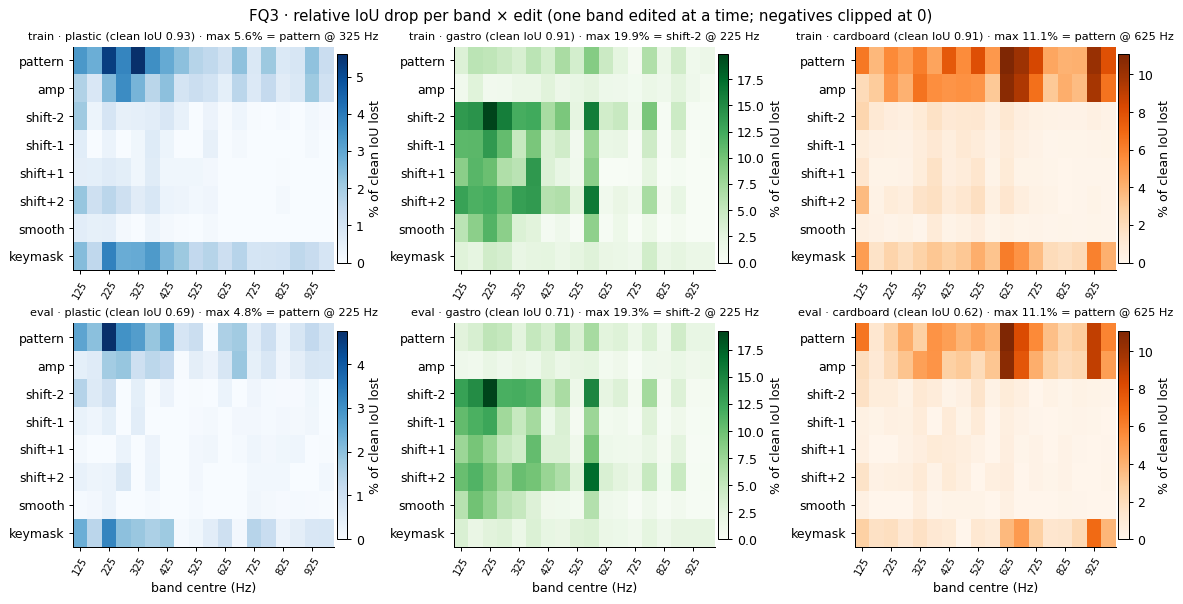

In [22]:
ED = ["pattern", "amp", "shift-2", "shift-1", "shift+1", "shift+2", "smooth", "keymask"]
def drops(s):   # {box: (8 edits, 18 bands)} relative IoU drop, % of clean
    r, box, cl = F3[s]["drop"], F3[s]["box"], F3[s]["clean"]; out = {}
    for b in BX:
        m = box == b; d = np.stack([absd(r[i][:, m], cl[m]).mean(1) for i in range(7)] + [FQ[s]["mask_b"][m].mean(0)])
        out[b] = 100 * d / CL0[s][b]
    return out
DR = {s: drops(s) for s in SETS}
fig, ax = plt.subplots(2, 3, figsize=(13, 6.6), constrained_layout=True)
for i, s in enumerate(SETS):
    for j, b in enumerate(BX):
        v = np.clip(DR[s][b], 0, None); h = ax[i, j].imshow(v, cmap=CMAP[b], vmin=0, aspect="auto")
        plt.colorbar(h, ax=ax[i, j], fraction=.04, pad=.01, label="% of clean IoU lost")
        ax[i, j].set_yticks(range(8), ED); ax[i, j].set_xticks(range(0, 18, 2), [f"{h:.0f}" for h in HZ[::2]], rotation=60, fontsize=8)
        k = np.unravel_index(DR[s][b].argmax(), DR[s][b].shape); ax[i, j].set_title(f"{s} · {b} (clean IoU {CL0[s][b]:.2f}) · max {DR[s][b].max():.1f}% = {ED[k[0]]} @ {HZ[k[1]]:.0f} Hz", fontsize=9)
        ax[i, j].set_xlabel("band centre (Hz)" if i else "")
fig.suptitle("FQ3 · relative IoU drop per band × edit (one band edited at a time; negatives clipped at 0)")
plt.show()

In [23]:
rows = []
for s in SETS:
    for b in BX:
        d = DR[s][b]; sh1, sh2 = d[[3, 4]].mean(0), d[[2, 5]].mean(0)
        r = {"set": s, "box": b}
        for nm, v in [("pattern", d[0]), ("amp", d[1]), ("shift±1", sh1), ("shift±2", sh2), ("smooth", d[6]), ("keymask", d[7])]:
            r[f"{nm} Σ"] = v.sum().round(1); r[f"{nm} max"] = f"{v.max():.1f}@{HZ[v.argmax()]:.0f}"
        rows.append(r)
TE = pd.DataFrame(rows).set_index(["set", "box"]); TE

pattern Σ pattern max      amp Σ   amp max  shift±1 Σ  \
set   box                                                                 
train plastic     44.299999     5.6@325  27.500000   3.6@275   2.800000   
      gastro      74.500000     9.0@575  28.299999   2.9@175  80.699997   
      cardboard  117.500000    11.1@625  98.800003  10.7@625   8.800000   
eval  plastic     29.000000     4.8@225  14.700000   1.9@275   1.300000   
      gastro      62.400002     6.8@575  25.000000   2.7@425  70.599998   
      cardboard   88.000000    11.1@625  72.500000  10.7@625   5.100000   

                shift±1 max   shift±2 Σ shift±2 max   smooth Σ smooth max  \
set   box                                                                   
train plastic       0.7@375    7.500000     2.1@125   1.600000    0.6@125   
      gastro       12.1@225  133.699997    16.2@575  53.599998   11.6@225   
      cardboard     1.4@375   15.300000     3.0@125   4.600000    0.9@375   
eval  plastic       0.2@225    2.600000     0.9@125   0.500000    0.3@225   
      gastro       10.5@175  117.599998    15.9@575  50.700001    9.7@175   
      cardboard     0.9@425    8.700000     1.6@125   2.100000    0.6@325   

                 keymask Σ keymask max  
set   box                               
train plastic    34.200001     3.8@225  
      gastro     43.000000     4.3@225  
      cardboard  60.700001     6.1@625  
eval  plastic    20.600000     3.2@225  
      gastro     39.500000     3.4@125  
      cardboard  40.200001     6.9@925

In [24]:
# where in frequency does each edit act: importance-weighted mean band Hz, and rank agreement with key-masking (Spearman over the 18 bands)
rows = []
for s in SETS:
    for b in BX:
        d = np.clip(DR[s][b], 0, None); r = {"set": s, "box": b}
        for i, nm in enumerate(ED[:-1]): r[f"{nm} ρ(mask)"] = round(stats.spearmanr(DR[s][b][i], DR[s][b][7])[0], 2)
        for i, nm in [(0, "pattern"), (1, "amp"), (2, "shift-2"), (6, "smooth"), (7, "keymask")]: r[f"{nm} Hz̄"] = int((d[i] * HZ).sum() / d[i].sum())
        rows.append(r)
pd.DataFrame(rows).set_index(["set", "box"])

pattern ρ(mask)  amp ρ(mask)  shift-2 ρ(mask)  \
set   box                                                        
train plastic               0.85         0.68             0.81   
      gastro                0.58         0.30             0.73   
      cardboard             0.88         0.59             0.32   
eval  plastic               0.73         0.47             0.58   
      gastro                0.55         0.50             0.51   
      cardboard             0.48         0.36            -0.04   

                 shift-1 ρ(mask)  shift+1 ρ(mask)  shift+2 ρ(mask)  \
set   box                                                            
train plastic               0.58             0.74             0.71   
      gastro                0.71             0.64             0.65   
      cardboard             0.32             0.38             0.38   
eval  plastic               0.27            -0.02             0.56   
      gastro                0.53             0.54             0.47   
      cardboard             0.03            -0.40            -0.38   

                 smooth ρ(mask)  pattern Hz̄  amp Hz̄  shift-2 Hz̄  \
set   box                                                            
train plastic              0.58          442      486          319   
      gastro               0.71          493      532          393   
      cardboard            0.14          577      593          425   
eval  plastic              0.27          421      498          304   
      gastro               0.50          499      527          375   
      cardboard           -0.21          588      612          422   

                 smooth Hz̄  keymask Hz̄  
set   box                                 
train plastic           241          463  
      gastro            323          508  
      cardboard         436          576  
eval  plastic           477          422  
      gastro            332          515  
      cardboard         435          639

#### FQ3 · gradient × input at full 1170-bin resolution
∂(soft Dice)/∂|X| · |X| per sample (soft Dice = 2Σpy / (Σp + Σy), p = sigmoid of the mask logits, the IoU proxy), **|g·x| summed over the 100 lasers and 2 axes**, averaged over the box's 240 samples (absolute, so position-dependent signs of opposite laser groups do not cancel). Ticks = the box's **relaxed resonances** from nb136 Q1b (same rule: savgol σ(f), prominence ≥ 2 × MAD from a 60 Hz baseline, present in ≥ 50% of captures of an (object, speaker) group), computed on the same set.

{('train', 'plastic'): 5, ('train', 'gastro'): 22, ('train', 'cardboard'): 7, ('eval', 'plastic'): 5, ('eval', 'gastro'): 22, ('eval', 'cardboard'): 6}


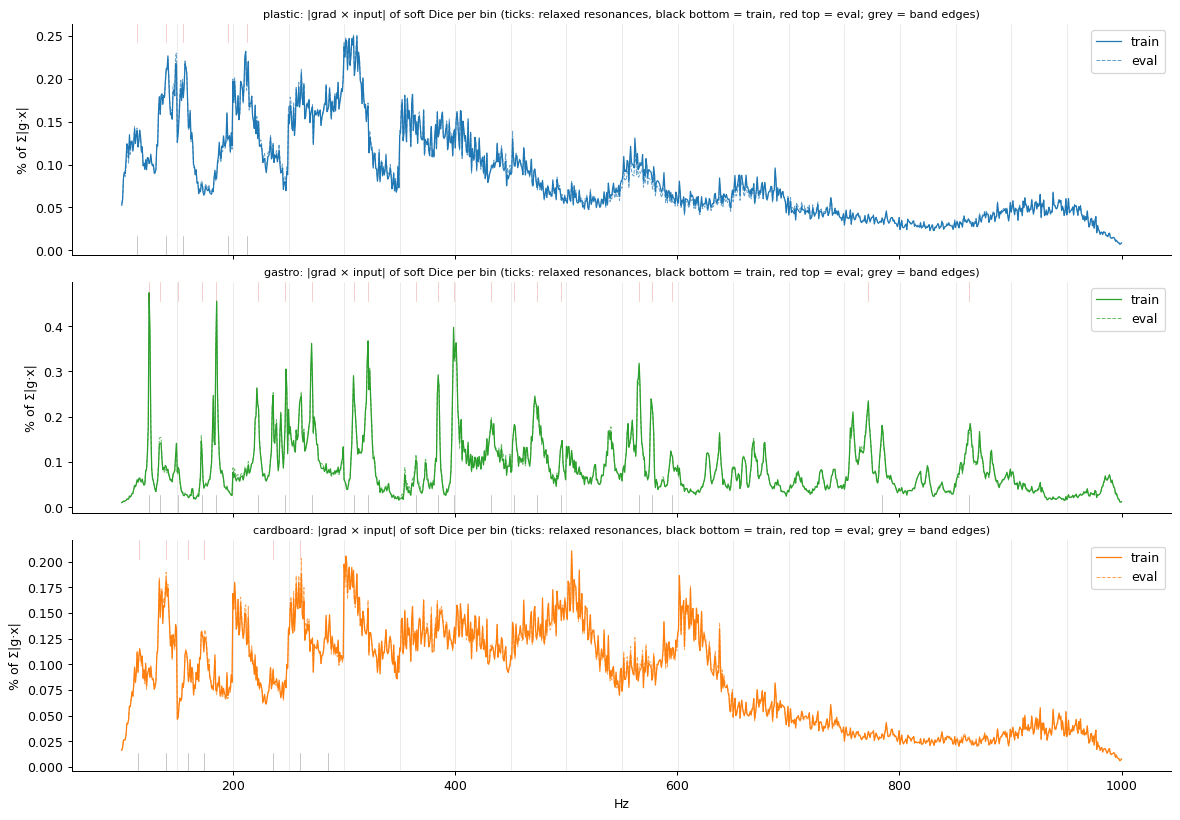

In [25]:
# relaxed resonances per (set, box): peaks() from Q1b, kept if present in ≥ 50% of captures of an (object, speaker) group
FRES = {}
for s in SETS:
    q = FQ[s]
    for b in BX:
        Oo, Ss = [], []
        for o in np.unique(q["obj"]):
            for sp in np.unique(q["spk"]):
                g = (q["box"] == b) & (q["obj"] == o) & (q["spk"] == sp)
                if g.sum() < 3: continue
                hit = np.zeros(q["sigma"][g].shape, np.uint8)
                for i, x in enumerate(q["sigma"][g]): hit[i, peaks(x)] = 1
                Oo.append(maximum_filter1d(hit, 7, axis=1).mean(0)); Ss.append(q["sigma"][g].mean(0))
        occ = np.mean(Oo, 0); FRES[s, b] = np.array([k for k in peaks(np.mean(Ss, 0)) if occ[k] >= .5])
print({k: len(v) for k, v in FRES.items()})
GX = {(s, b): F3[s]["agx"][F3[s]["box"] == b].sum(-1).mean(0) for s in SETS for b in BX}    # (1170,) mean |g·x|
fig, ax = plt.subplots(3, 1, figsize=(13, 9), sharex=True, constrained_layout=True)
for j, b in enumerate(BX):
    for s, ls in zip(SETS, ["-", "--"]): g = GX[s, b]; ax[j].plot(FHZ, g / g.sum() * 100, ls, color=BOXC[b], lw=1 if s == "train" else .8, alpha=1 if s == "train" else .7, label=s)
    for k in FRES["train", b]: ax[j].axvline(FHZ[k], color="k", lw=.5, alpha=.35, ymax=.08)
    for k in FRES["eval", b]: ax[j].axvline(FHZ[k], color="tab:red", lw=.5, alpha=.35, ymin=.92)
    for e in 100 + np.arange(1, 18) * 65 * 900 / 1169: ax[j].axvline(e, color="0.85", lw=.4, zorder=0)
    ax[j].set_ylabel("% of Σ|g·x|"); ax[j].set_title(f"{b}: |grad × input| of soft Dice per bin (ticks: relaxed resonances, black bottom = train, red top = eval; grey = band edges)", fontsize=9); ax[j].legend(loc="upper right")
ax[-1].set_xlabel("Hz"); plt.show()

In [26]:
# top lines: the 10 largest local maxima of mean |g·x| (≥ 5 Hz apart); distance to nearest relaxed resonance; chance = share of bins within ±3 Hz of any resonance
rows = []
for s in SETS:
    for b in BX:
        g, res = GX[s, b], FRES[s, b]; pk = find_peaks(g, distance=7)[0]; top = pk[np.argsort(-g[pk])[:10]]
        dist = np.array([np.abs(FHZ[res] - FHZ[k]).min() for k in top]); near = np.abs(FHZ[:, None] - FHZ[res][None]).min(1) <= 3
        share = g[near].sum() / g.sum()
        rows.append({"set": s, "box": b, "top lines (Hz)": " ".join(f"{FHZ[k]:.0f}" for k in top), "Δ to nearest res (Hz)": " ".join(f"{d:.0f}" for d in dist),
                     "top10 within ±3 Hz": f"{(dist <= 3).sum()}/10", "chance": f"{near.mean():.2f}", "|g·x| mass within ±3 Hz": f"{share:.2f}",
                     "top-10 share of mass": f"{g[top].sum() / g.sum():.3f}"})
TG = pd.DataFrame(rows).set_index(["set", "box"]); pd.set_option("display.max_colwidth", 80); TG

top lines (Hz)  \
set   box                                                  
train plastic    309 302 212 142 149 157 262 317 200 295   
      gastro     125 185 399 322 271 566 248 385 309 222   
      cardboard  505 302 307 512 262 602 140 134 202 612   
eval  plastic    312 302 149 212 142 157 262 202 317 295   
      gastro     125 185 399 322 271 566 248 309 385 222   
      cardboard  505 262 302 140 307 512 134 602 202 612   

                          Δ to nearest res (Hz) top10 within ±3 Hz chance  \
set   box                                                                   
train plastic         95 89 2 2 7 2 49 104 5 82               3/10   0.03   
      gastro                0 1 0 0 1 0 1 0 1 1              10/10   0.13   
      cardboard  219 16 22 226 2 316 0 6 28 326               2/10   0.04   
eval  plastic         99 89 6 2 2 2 49 6 104 82               3/10   0.03   
      gastro                0 1 0 0 1 0 1 1 0 1              10/10   0.13   
      cardboard  245 2 42 0 47 252 6 342 28 352               2/10   0.04   

                |g·x| mass within ±3 Hz top-10 share of mass  
set   box                                                     
train plastic                      0.06                0.022  
      gastro                       0.27                0.035  
      cardboard                    0.06                0.019  
eval  plastic                      0.06                0.022  
      gastro                       0.27                0.035  
      cardboard                    0.05                0.019

In [27]:
# |g·x| per band vs the per-band edits (Spearman over 18 bands), and the resonance list itself
for s in SETS:
    print(s, {b: {nm: round(stats.spearmanr(GX[s, b].reshape(18, 65).sum(1), DR[s][b][i])[0], 2) for i, nm in [(0, "pattern"), (2, "shift-2"), (6, "smooth"), (7, "keymask")]} for b in BX})
for b in BX: print(b, "train resonances (Hz):", " ".join(f"{FHZ[k]:.0f}" for k in FRES["train", b]))

train {'plastic': {'pattern': np.float64(0.89), 'shift-2': np.float64(0.79), 'smooth': np.float64(0.65), 'keymask': np.float64(0.89)}, 'gastro': {'pattern': np.float64(0.68), 'shift-2': np.float64(0.7), 'smooth': np.float64(0.62), 'keymask': np.float64(0.7)}, 'cardboard': {'pattern': np.float64(0.08), 'shift-2': np.float64(0.76), 'smooth': np.float64(0.61), 'keymask': np.float64(0.04)}}
eval {'plastic': {'pattern': np.float64(0.79), 'shift-2': np.float64(0.17), 'smooth': np.float64(-0.22), 'keymask': np.float64(0.61)}, 'gastro': {'pattern': np.float64(0.79), 'shift-2': np.float64(0.64), 'smooth': np.float64(0.56), 'keymask': np.float64(0.36)}, 'cardboard': {'pattern': np.float64(-0.02), 'shift-2': np.float64(0.59), 'smooth': np.float64(0.36), 'keymask': np.float64(-0.57)}}
plastic train resonances (Hz): 114 140 155 195 213
gastro train resonances (Hz): 125 135 151 172 185 222 247 272 309 322 365 385 399 433 453 473 496 566 577 595 784 863
cardboard train resonances (Hz): 115 140 159 17

**FQ3 answer** (240 samples per box; train / eval; % of clean IoU lost by editing one band; Σ = sum over the 18 single-band edits).

**The mechanism depends on the box, and the split follows damping.**
- **Gastro: lightly damped (loss factor η ≈ .006), sharp resonances. The model reads exact resonance frequencies.**
  - Shifting one band by **±1 bin (0.77 Hz)** costs up to **12.1 / 10.5%** (225 / 175 Hz). ±2 bins costs up to 16.2 / 15.9% (575 Hz), Σ 134 / 118%. A 7 Hz smooth costs Σ 54 / 51%.
  - All three cost more than **dropping the band** (key-mask Σ 43 / 40%, max 4.3 / 3.4%). A slightly mistuned band is worse than a missing one: the model takes it as a confident, wrong cue.
  - Amplitude alone matters little (Σ 28 / 25%, ~40% of the across-laser pattern effect, Σ 75 / 62%). The spatial information sits in each laser's line positions, not in its level.
  - grad × input agrees at full resolution. **All 10 top |g·x| lines lie within 1 Hz of a relaxed resonance** (125, 185, 399, 322, 271, 566, 248, 385, 309, 222 Hz; chance .13 per line). 27% of the |g·x| mass falls within ±3 Hz of the 22 resonances, which cover 13% of bins.
  - Reading sub-Hz positions of sharp modes is what mass loading predicts: an object shifts mode frequencies by an amount that depends on where it sits on the mode shape (Q2).
- **Cardboard and plastic: damped (η ≈ .055 / .039), broad humps. The across-laser pattern matters, not frequency.**
  - Cardboard: removing the pattern costs Σ 118 / 88%, max **11.1% @ 625 Hz** in both sets. **Amplitude carries ~82% of it** (amp Σ 99 / 73% = 84 / 82% of pattern; max 10.7% @ 625 Hz). The effect sits at 625–675 and 925–975 Hz, the bands key-masking flags. A shift costs ≤ 3.0% per band (Σ 15 / 9%), smoothing ≤ 0.9%.
  - Plastic: the same picture, weaker. Pattern max 5.6 / 4.8% (325 / 225 Hz), Σ 44 / 29%; amp Σ 28 / 15%; shift and smooth ≤ 2.1% (Σ ≤ 7.5%).
  - The gradient shows broad humps, not lines (plastic 140–160, 200–215, 300–320 Hz; cardboard 260, 300, 500–512, 600–612 Hz). Only 2–3 of the 10 top lines are near a resonance (chance .03–.04), and 5–6% of the mass is within ±3 Hz, ~1.5× chance.
- **Agreement with key-masking** (Spearman over the 18 bands): pattern ρ .85 / .73 (plastic), .88 / .48 (cardboard). In gastro, shift and smooth agree with key-masking as well as pattern does (ρ ≈ .5–.7).
- The train and eval gradient spectra are nearly identical, so the map is a property of the model, not of the sample set.
- **Caveat.** A uniform shift of a whole 50 Hz band is mildly off-distribution: real object-induced shifts differ per mode. Part of gastro's shift cost may therefore be sensitivity to an unnatural input. The grad × input lines are a local measure and do not share this caveat.

### FQ2 · Redundancy vs synergy between bands
- **Pairwise key-masking** of all 153 band pairs (plus the 18 singles, recomputed in the same pass), per sample. Interaction **I(i,j) = Δij − Δi − Δj** on the box-level relative drop (% of clean IoU): **negative = redundant** (dropping both costs less than the sum; one covers for the other), **positive = synergy** (the pair carries information neither carries alone).
- **Shapley values** per band: v(S) = mean IoU of the box's 240 samples with only bands S kept (the rest key-masked); 200 random permutations per box (100 antithetic pairs, one permutation shared by all samples of the box), φᵢ = mean marginal gain when band i is added. v(∅) = no band kept (the freq readout reduces to its bias). By efficiency Σφ = v(all) − v(∅). The forward runs on the kept band tokens only (exactly equal to key-masking, checked in the script).
- Shapley ranking vs single-band masking ranking (Spearman over 18 bands), and the top-K keep curve / **K90** (bands kept for 90% of clean IoU) with the Shapley order, vs masking order from Q1 (`c|box|band|masking`).

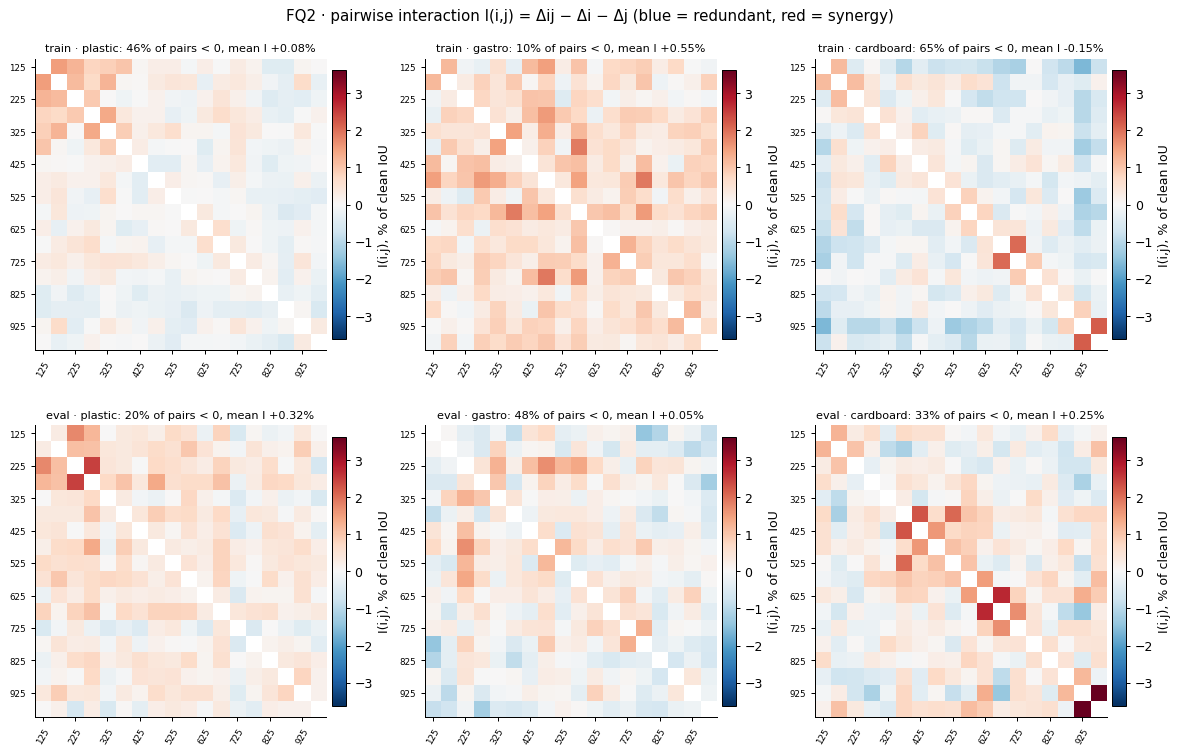

In [28]:
def inter(s):  # {box: (18,18)} I(i,j) in % of clean IoU, plus singles and pair drops
    f, out = F2[s], {}
    for b in BX:
        m = f["box"] == b; cl = f["clean"][m]; d1 = absd(f["single"][m], cl[:, None]).mean(0) / CL0[s][b] * 100
        d2 = absd(np.nan_to_num(f["pair"][m]), cl[:, None, None]).mean(0) / CL0[s][b] * 100
        I = d2 - d1[:, None] - d1[None]; np.fill_diagonal(I, np.nan); out[b] = (I, d1, d2)
    return out
IN = {s: inter(s) for s in SETS}
ilim = max(np.nanmax(np.abs(IN[s][b][0])) for s in SETS for b in BX)
fig, ax = plt.subplots(2, 3, figsize=(13, 8.4), constrained_layout=True)
for i, s in enumerate(SETS):
    for j, b in enumerate(BX):
        Ip = IN[s][b][0]; h = ax[i, j].imshow(Ip, cmap="RdBu_r", vmin=-ilim, vmax=ilim)
        iu = np.triu_indices(18, 1); v = Ip[iu]
        ax[i, j].set_title(f"{s} · {b}: {(v < 0).mean() * 100:.0f}% of pairs < 0, mean I {v.mean():+.2f}%", fontsize=9)
        ax[i, j].set_xticks(range(0, 18, 2), [f"{h:.0f}" for h in HZ[::2]], rotation=60, fontsize=7); ax[i, j].set_yticks(range(0, 18, 2), [f"{h:.0f}" for h in HZ[::2]], fontsize=7)
        plt.colorbar(h, ax=ax[i, j], fraction=.046, pad=.02, label="I(i,j), % of clean IoU")
fig.suptitle("FQ2 · pairwise interaction I(i,j) = Δij − Δi − Δj (blue = redundant, red = synergy)"); plt.show()

In [29]:
rows = []
for s in SETS:
    for b in BX:
        Ip, d1, d2 = IN[s][b]; v = Ip[np.triu_indices(18, 1)]; k = np.unravel_index(np.nanargmin(Ip), Ip.shape); kk = np.unravel_index(np.nanargmax(Ip), Ip.shape)
        nb = np.array([Ip[i, i + 1] for i in range(17)])
        rows.append({"set": s, "box": b, "Σ singles %": d1.sum().round(1), "mean pair Δij %": d2[np.triu_indices(18, 1)].mean().round(2),
                     "mean I %": v.mean().round(2), "median I %": np.median(v).round(2), "share I<0": (v < 0).mean().round(2), "share |I|>1%": (np.abs(v) > 1).mean().round(2),
                     "most redundant": f"{HZ[k[0]]:.0f}+{HZ[k[1]]:.0f}: {Ip[k]:+.1f}", "most synergistic": f"{HZ[kk[0]]:.0f}+{HZ[kk[1]]:.0f}: {Ip[kk]:+.1f}",
                     "adjacent-band mean I %": nb.mean().round(2), "I ~ |i−j| ρ": round(stats.spearmanr(v, np.subtract(*np.triu_indices(18, 1)) * -1)[0], 2)})
pd.DataFrame(rows).set_index(["set", "box"])

Σ singles %  mean pair Δij %  mean I %  median I %  \
set   box                                                             
train plastic      34.200001             3.88      0.08        0.02   
      gastro       43.000000             5.33      0.55        0.53   
      cardboard    60.700001             6.60     -0.15       -0.16   
eval  plastic      20.600000             2.61      0.32        0.33   
      gastro       39.500000             4.44      0.05        0.05   
      cardboard    40.200001             4.72      0.25        0.18   

                 share I<0  share |I|>1% most redundant most synergistic  \
set   box                                                                  
train plastic         0.46          0.04  875+975: -0.6    125+175: +1.5   
      gastro          0.10          0.14  225+525: -0.5    475+775: +1.9   
      cardboard       0.65          0.08  125+925: -1.6    975+925: +2.2   
eval  plastic         0.20          0.05  225+975: -0.6    275+225: +2.5   
      gastro          0.48          0.07  125+775: -1.4    475+225: +1.7   
      cardboard       0.33          0.12  675+925: -1.4    925+975: +3.6   

                 adjacent-band mean I %  I ~ |i−j| ρ  
set   box                                             
train plastic                      0.46        -0.21  
      gastro                       0.67        -0.16  
      cardboard                    0.81        -0.50  
eval  plastic                      0.48        -0.16  
      gastro                       0.30        -0.24  
      cardboard                    1.20        -0.35

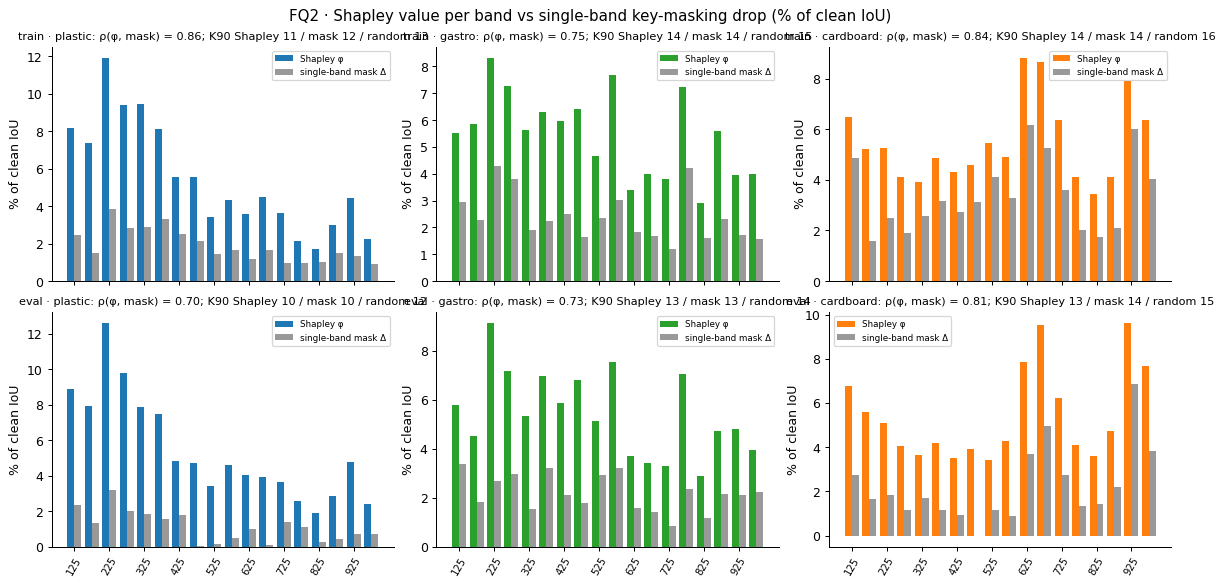

v(all)   v(∅)  Σφ %  Σ mask Δ % φ top-3 (Hz) mask top-3 (Hz)  \
set   box                                                                       
train plastic     0.926  0.013  98.6   34.200001  225 325 275     225 375 325   
      gastro      0.911  0.014  98.4   43.000000  225 575 275     225 775 275   
      cardboard   0.909  0.011  98.8   60.700001  625 675 925     625 925 675   
eval  plastic     0.692  0.013  98.1   20.600000  225 275 125     225 125 275   
      gastro      0.711  0.014  98.0   39.500000  225 575 275     125 575 375   
      cardboard   0.619  0.014  97.8   40.200001  925 675 625     925 675 975   

                 max φ %  min φ %  ρ(φ, mask)  ρ(φ 1st, 2nd 100 perms)  \
set   box                                                                
train plastic       11.9      1.7        0.86                     0.98   
      gastro         8.3      2.9        0.75                     0.86   
      cardboard      8.8      3.4        0.84                     0.94   
eval  plastic       12.6      1.9        0.70                     0.97   
      gastro         9.1      2.9        0.73                     0.89   
      cardboard      9.6      3.4        0.81                     0.88   

                 K90 Shapley  K90 mask  K90 random  K50 Shapley  K50 mask  
set   box                                                                  
train plastic             11        12          13            5         5  
      gastro              14        14          15            6         7  
      cardboard           14        14          16            7         7  
eval  plastic             10        10          12            5         4  
      gastro              13        13          14            6         6  
      cardboard           13        14          15            6         6

In [30]:
# Shapley vs single-band masking; K90 with each ranking
def k90f(c, c_clean, fr=.9): r = np.asarray(c) / c_clean; return int(np.argmax(r >= fr)) + 1 if (r >= fr).any() else 18
def phi_of(f, b, T):  # Shapley from a subset T of the stored permutations: marginal gains from the stored v(S) chains
    P, V, v0 = f[f"perm|{b}"][T], f[f"V|{b}"][T], f[f"v0|{b}"]; g = np.diff(np.c_[np.full(len(V), v0), V], axis=1); out = np.zeros(18)
    for o, gg in zip(P, g): out[o] += gg
    return out / len(T)
fig, ax = plt.subplots(2, 3, figsize=(13, 6.4), constrained_layout=True, sharex=True); rows = []
for i, s in enumerate(SETS):
    f = F2[s]
    for j, b in enumerate(BX):
        phi = 100 * f[f"phi|{b}"] / CL0[s][b]; msk = DR[s][b][7]; v0 = f[f"v0|{b}"]
        n = len(f[f"V|{b}"]); half = [phi_of(f, b, np.arange(n // 2)), phi_of(f, b, np.arange(n // 2, n))]; assert np.allclose(phi_of(f, b, np.arange(n)), f[f"phi|{b}"])
        w = .4; ax[i, j].bar(np.arange(18) - w / 2, phi, w, color=BOXC[b], label="Shapley φ"); ax[i, j].bar(np.arange(18) + w / 2, msk, w, color="0.6", label="single-band mask Δ")
        rphi = stats.spearmanr(phi, msk)[0]; cs = FQ[s][f"c|{b}|band|masking"]; cr = np.mean([FQ[s][f"c|{b}|band|random{r}"] for r in range(3)], 0)
        ksh, kms, krd = k90f(f[f"c|{b}|shapley"], CL0[s][b]), k90f(cs, CL0[s][b]), k90f(cr, CL0[s][b])
        ax[i, j].set_title(f"{s} · {b}: ρ(φ, mask) = {rphi:.2f}; K90 Shapley {ksh} / mask {kms} / random {krd}", fontsize=9)
        ax[i, j].set_xticks(range(0, 18, 2), [f"{h:.0f}" for h in HZ[::2]], rotation=60, fontsize=8); ax[i, j].set_ylabel("% of clean IoU"); ax[i, j].legend(fontsize=7)
        rows.append({"set": s, "box": b, "v(all)": round(float(CL0[s][b]), 3), "v(∅)": round(float(v0), 3), "Σφ %": phi.sum().round(1), "Σ mask Δ %": msk.sum().round(1),
                     "φ top-3 (Hz)": " ".join(f"{HZ[k]:.0f}" for k in np.argsort(-phi)[:3]), "mask top-3 (Hz)": " ".join(f"{HZ[k]:.0f}" for k in np.argsort(-msk)[:3]),
                     "max φ %": phi.max().round(1), "min φ %": phi.min().round(1), "ρ(φ, mask)": round(rphi, 2), "ρ(φ 1st, 2nd 100 perms)": round(stats.spearmanr(*half)[0], 2),
                     "K90 Shapley": ksh, "K90 mask": kms, "K90 random": krd,
                     "K50 Shapley": k90f(f[f"c|{b}|shapley"], CL0[s][b], .5), "K50 mask": k90f(cs, CL0[s][b], .5)})
fig.suptitle("FQ2 · Shapley value per band vs single-band key-masking drop (% of clean IoU)"); plt.show()
TS = pd.DataFrame(rows).set_index(["set", "box"]); TS

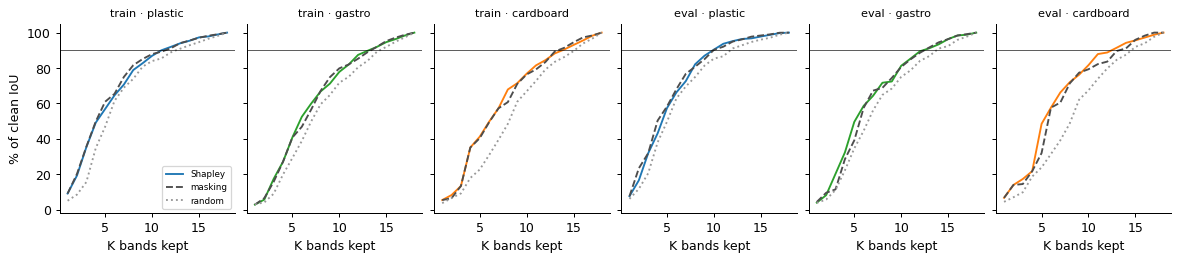

In [31]:
# top-K keep curves: Shapley order vs masking order vs random (nb136 Q1 curves), % of clean IoU
fig, ax = plt.subplots(1, 6, figsize=(13, 2.8), sharey=True, constrained_layout=True)
for i, (s, b) in enumerate([(s, b) for s in SETS for b in BX]):
    K = np.arange(1, 19); f = F2[s]
    ax[i].plot(K, 100 * f[f"c|{b}|shapley"] / CL0[s][b], color=BOXC[b], label="Shapley"); ax[i].plot(FQ[s]["KB"], 100 * FQ[s][f"c|{b}|band|masking"] / CL0[s][b], "--", color="0.3", label="masking")
    ax[i].plot(FQ[s]["KB"], 100 * np.mean([FQ[s][f"c|{b}|band|random{r}"] for r in range(3)], 0) / CL0[s][b], ":", color="0.6", label="random")
    ax[i].axhline(90, color="k", lw=.5); ax[i].set_title(f"{s} · {b}", fontsize=9); ax[i].set_xlabel("K bands kept")
ax[0].set_ylabel("% of clean IoU"); ax[0].legend(fontsize=7); plt.show()

**FQ2 answer** (train / eval; I in % of clean IoU).

**The bands are nearly additive: neither a redundant code nor a synergistic one.**
- **Interactions are small.** Single-band drops are 1–7%, pair drops average 2.6–6.6%, and the **mean I is −0.15 to +0.55%**. Only 4–14% of pairs have |I| > 1%; the extremes are −1.6% and +3.6%.
- **The sign is not stable between train and eval.** Gastro: 90% of pairs synergistic on train (mean +.55%) but 48 / 52 on eval (+.05%). Cardboard: 65% redundant on train (−.15%) but 33% on eval (+.25%). Plastic is about neutral (46 / 20% negative; +.08 / +.32%).
- **The one consistent effect is mild adjacent-band synergy.** The mean I of neighbouring bands is **+0.3 to +1.2%** in every box and set, and I falls with band distance (ρ(I, |i − j|) −.16 to −.50). Dropping two neighbouring 50 Hz bands removes a whole resonance region that neither drop removes alone. The largest synergy is cardboard **925 + 975 Hz (+2.2 / +3.6%)**; plastic 225 + 275 Hz reaches +2.5% on eval. The few redundant pairs pair a far band with 925 Hz in cardboard (down to −1.6%, 125 + 925 Hz).
- So "many bands are needed" (Q1, K90 13–14 of 18) means spread-out, mostly additive information, not one band covering for another.

**Shapley vs single-band masking**
- Σφ = v(all) − v(∅) = 98% of clean IoU (v(∅) = .011–.014). Rankings are stable between the two halves of the 200 permutations (ρ .86–.98).
- **ρ(Shapley, masking) = .70–.86**: .86 / .70 (plastic), .75 / .73 (gastro), .84 / .81 (cardboard). The top bands agree: plastic 225 / 275–325 Hz, gastro 225 / 575 / 275 Hz, cardboard 625 / 675 / 925 Hz.
- Shapley spreads credit more evenly (max φ 8–13%, min 1.7–3.4%). Single drops sum to only 21–61% of clean IoU, so most of a band's value shows only after many other bands are gone.
- **K90**: Shapley 11 / 10, 14 / 13, 14 / 13 (plastic, gastro, cardboard); masking 12 / 10, 14 / 13, 14 / 14; random 13 / 12, 15 / 14, 16 / 15. Shapley gains **at most one band**, and K50 is 5–7 for both.
- **Single-band masking is an adequate ranking.** The interactions are too weak for a joint attribution to change the top-K picture.

### FQ1 · Are the band-masking peaks real, and do objects read different bands?
Between train and eval the Q1 masking peak moved **224 → 124 Hz in gastro** and **625 → 925 Hz in cardboard**. Is that noise, or do objects (or speakers, or position) read different bands? Same per-sample masking drops as Q1 (`q1_{SET}.npz`), GT masks from `base.npz`; nothing is recomputed. Importance per band = relative IoU drop, (mean over samples of clean − masked) / mean clean, as in Q1.

In [32]:
# FQ1 · per-sample band masking from the Q1 caches (FQ = q1_{SET}.npz = q1_single.npz indexed by subset720.npz, checked); GT masks from base.npz (B)
OBJ = ["candle", "red-cube", "soap dispenser", "vase"]
FCM = {b: plt.get_cmap(c) for b, c in zip(BX, ["Blues", "Greens", "Oranges"])}   # colormap objects (CMAP above holds names)
QS, SU = np.load(CACHE / "q1_single.npz"), np.load(CACHE / "subset720.npz")
assert (QS["mask_b"][SU["eval_q"]] == FQ["eval"]["mask_b"]).all() and (QS["tr_mask_b"][SU["train_q"]] == FQ["train"]["mask_b"]).all()
Yb, FD = B["y"], {}   # FD[set, box]: mask_b (240,18), clean, obj, spk, row (CoM row; laser wall = bottom of the crop = large row), area
for s in SETS:
    q = FQ[s]
    for b in BX:
        k = q["box"] == b
        FD[s, b] = dict(m=q["mask_b"][k].astype(np.float64), c=q["clean"][k].astype(np.float64), obj=q["obj"][k], spk=q["spk"][k],
                        row=q["com"][k, 0], area=Yb[q["rows"][k]].sum((1, 2)))
del Yb, QS, SU
print(pd.crosstab(FQ["eval"]["box"], FQ["eval"]["obj"]).reindex(BX).to_string())
relb = lambda m, c: m.mean(0) / c.mean()                                # relative IoU drop per band (same definition as Q1)
def boot(m, c, n=1000, seed=0):                                         # (n,18) bootstrap of relb over samples
    i = np.random.default_rng(seed).integers(0, len(c), (n, len(c)))
    return m[i].mean(1) / c[i].mean(1)[:, None]
wmf = lambda r: (HZ * np.clip(r, 0, None)).sum(-1) / np.clip(r, 0, None).sum(-1)   # importance-weighted mean frequency

col_0      candle  red-cube  soap dispenser  vase
row_0                                            
plastic        60        60              60    60
gastro         60        60              60    60
cardboard      60        60              60    60


#### FQ1.1 · Bootstrap of the box-level profile
1000 resamples of the 240 samples per (set, box). Table: peak band, its 95% CI, the share of resamples it stays the peak, the top-3 peak bands, `n_overlap` (bands whose upper CI reaches the peak's lower CI), and the importance-weighted mean frequency with its CI.

  set       box  peak_hz  peak_rel             ci  p_peak                         top3  n_overlap     wmf     wmf_ci
train   plastic      225     0.038 [0.032, 0.046]   0.895 225:0.90, 375:0.09, 275:0.01          4 463.052 [444, 479]
train    gastro      225     0.043 [0.036, 0.050]   0.527 225:0.53, 775:0.42, 275:0.05          5 508.453 [494, 521]
train cardboard      625     0.061 [0.053, 0.071]   0.591 625:0.59, 925:0.40, 675:0.01          4 576.347 [565, 588]
 eval   plastic      225     0.032 [0.019, 0.047]   0.782 225:0.78, 125:0.13, 275:0.06          8 422.942 [384, 463]
 eval    gastro      125     0.034 [0.024, 0.046]   0.319 125:0.32, 375:0.19, 575:0.19         16 515.631 [483, 546]
 eval cardboard      925     0.069 [0.054, 0.087]   0.976 925:0.98, 675:0.02, 625:0.01          3 639.283 [604, 680]
n_overlap = bands whose upper CI reaches the peak band's lower CI (incl. the peak)
plastic rho(train, eval) = 0.48 CI [0.26 0.64]
gastro rho(train, eval) = 0.71 CI [0.3 0.8]


cardboard rho(train, eval) = 0.49 CI [0.31 0.71]


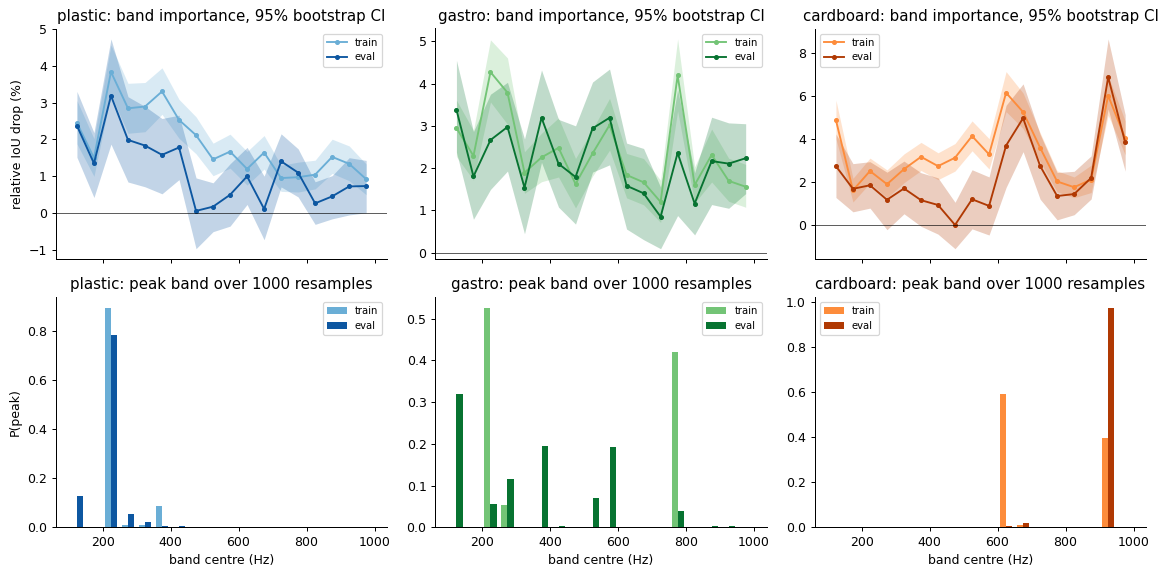

In [33]:
# FQ1.1 · bootstrap the 240 samples per box: 95% CI per band, peak-band distribution
BT, rows = {}, []
for s in SETS:
    for b in BX:
        d = FD[s, b]; r = relb(d["m"], d["c"]); bt = BT[s, b] = boot(d["m"], d["c"]); pk = np.bincount(bt.argmax(1), minlength=18) / len(bt)
        lo, hi = np.percentile(bt, [2.5, 97.5], 0); top = np.argsort(-pk)[:3]
        rows.append(dict(set=s, box=b, peak_hz=round(HZ[r.argmax()]), peak_rel=r.max(), ci=f"[{lo[r.argmax()]:.3f}, {hi[r.argmax()]:.3f}]",
                         p_peak=pk[r.argmax()], top3=", ".join(f"{HZ[k]:.0f}:{pk[k]:.2f}" for k in top),
                         n_overlap=int((hi >= lo[r.argmax()]).sum()), wmf=wmf(r), wmf_ci=f"[{np.percentile(wmf(bt), 2.5):.0f}, {np.percentile(wmf(bt), 97.5):.0f}]"))
U1 = pd.DataFrame(rows); print(U1.round(3).to_string(index=False))
print("n_overlap = bands whose upper CI reaches the peak band's lower CI (incl. the peak)")
# train-vs-eval profile agreement per box, with bootstrap CI
for b in BX: print(b, "rho(train, eval) =", round(rho(relb(FD["train", b]["m"], FD["train", b]["c"]), relb(FD["eval", b]["m"], FD["eval", b]["c"])), 2),
                   "CI", np.percentile([rho(x, y) for x, y in zip(BT["train", b], BT["eval", b])], [2.5, 97.5]).round(2))

fig, ax = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for j, b in enumerate(BX):
    for i, s in enumerate(SETS):
        d, bt, cm = FD[s, b], BT[s, b], FCM[b]; lo, hi = np.percentile(bt, [2.5, 97.5], 0); col = cm(.5 + .35 * i)
        ax[0, j].fill_between(HZ, lo * 100, hi * 100, color=col, alpha=.25, lw=0); ax[0, j].plot(HZ, relb(d["m"], d["c"]) * 100, "o-", c=col, ms=3, label=s)
        ax[1, j].bar(HZ + (i - .5) * 18, np.bincount(bt.argmax(1), minlength=18) / len(bt), width=18, color=col, label=s)
    ax[0, j].axhline(0, c="k", lw=.5); ax[0, j].set_title(f"{b}: band importance, 95% bootstrap CI"); ax[0, j].legend(fontsize=8)
    ax[1, j].set_title(f"{b}: peak band over 1000 resamples"); ax[1, j].set_xlabel("band centre (Hz)"); ax[1, j].legend(fontsize=8)
ax[0, 0].set_ylabel("relative IoU drop (%)"); ax[1, 0].set_ylabel("P(peak)"); plt.tight_layout(); plt.show()

**Answer.**
- **Plastic: stable.** 225 Hz is the peak in 90% (train) and 78% (eval) of resamples.
- **Gastro: not stable.** Train 225 Hz wins 53% vs 775 Hz 42%. Eval 125 Hz wins only 32% (375 and 575 Hz 19% each), and 16 of 18 band CIs overlap its CI [.024, .046]. "224 → 124 Hz" is a noise-level re-ranking, not a shift.
- **Cardboard: a two-band tie that resolves.** Train 625 Hz 59% / 925 Hz 40%; eval 925 Hz 98%. Both bands are high either way.
- **What is stable is the weighted mean frequency:** 463 / 508 / 576 Hz train, 423 / 516 / 639 Hz eval (CIs ±15–40 Hz). Plastic is lowest and cardboard highest in both sets; cardboard's eval rise (CI [604, 680] vs [565, 588]) is the only real shift.

#### FQ1.2 · Per object
Profiles per object (60 samples each) with bootstrap CIs. Tests, label shuffle within box (1000 perms; `_spk` = shuffled within speaker, 300 perms):
- **ρ** = mean pairwise Spearman between the 4 object profiles (shape similarity; p_ρ = P(null ≤ obs)).
- **F** = Σ n·‖rel_obj − rel_box‖² (level + shape). **Fz** = the same on per-object z-scored profiles (shape only).
- `lvl` = Σ over bands of the relative drop (%), i.e. the object's overall sensitivity.
- Train ↔ eval ρ of the same object vs different objects, and the within-object split-half ρ (30 vs 30), the noise ceiling at n = 60.

  set       box   rho  rho_null  p_rho     F  F_null   p_F       Fz  Fz_null  p_Fz  p_F_spk  p_Fz_spk
train   plastic 0.726     0.748  0.306 0.284   0.090 0.001  993.444  700.642 0.017    0.003     0.017
train    gastro 0.637     0.668  0.295 0.305   0.123 0.001  930.428  845.631 0.273    0.003     0.282
train cardboard 0.839     0.831  0.591 0.868   0.165 0.001  481.525  490.028 0.509    0.003     0.578
 eval   plastic 0.409     0.432  0.398 0.723   0.275 0.001 1958.374 1786.742 0.246    0.003     0.342
 eval    gastro 0.158     0.225  0.194 0.710   0.399 0.003 2847.914 2563.577 0.113    0.027     0.266
 eval cardboard 0.499     0.463  0.705 1.037   0.628 0.006 1244.420 1274.300 0.565    0.023     0.571
  set       box  lvl candl  lvl red-c  lvl soap   lvl vase peak candle peak red-cube peak soap dispenser peak vase
train   plastic       25.1       52.2       30.4      28.9         225           325                 375       225
train    gastro       32.0       53.3       52.1      34


within-object split-half ρ (30 vs 30) = noise ceiling for between-object ρ at n=60
   set       box  split_half_rho
train   plastic            0.65
train    gastro            0.55
train cardboard            0.76
 eval   plastic            0.23
 eval    gastro            0.14
 eval cardboard            0.34


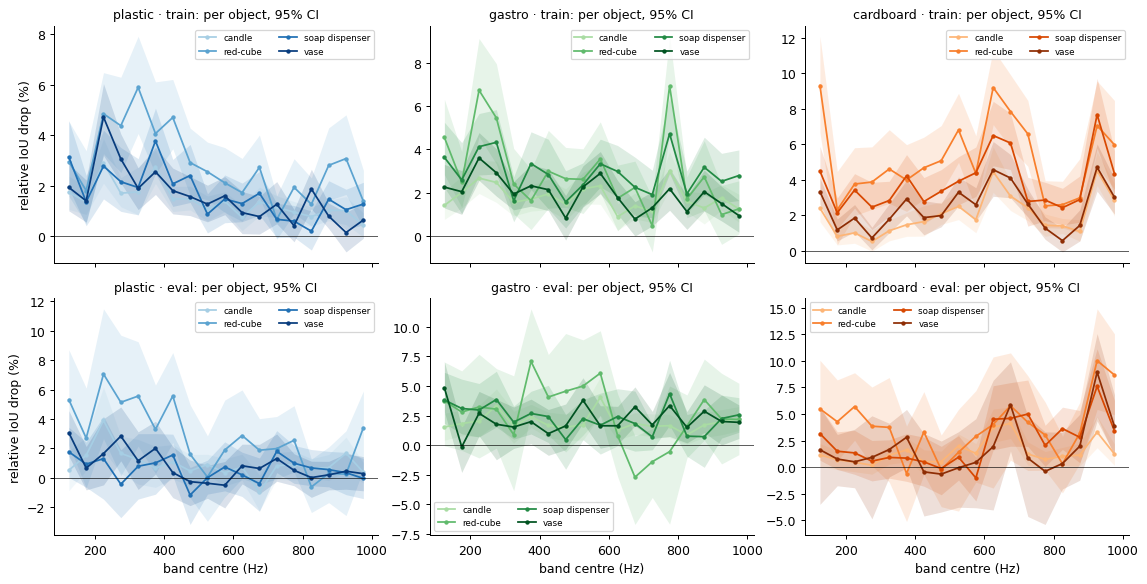

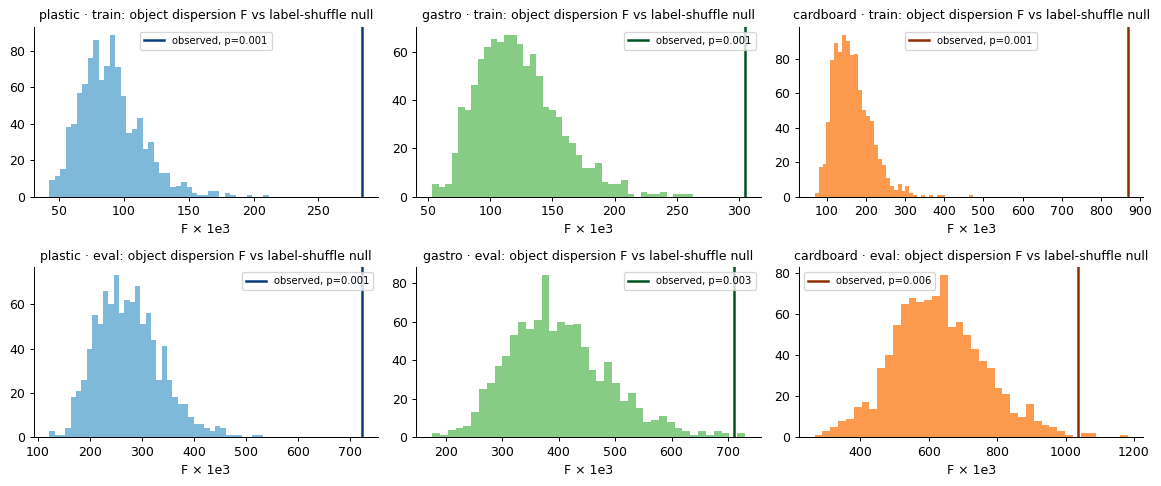

In [34]:
# FQ1.2 · grouping test, reused for object / speaker / position region
# stat 1 = mean pairwise Spearman ρ between group profiles (low = groups read different bands)
# stat 2 = dispersion F = Σ_g n_g ||rel_g − rel_box||² (large = groups differ, level or shape)
# stat 3 = shape-only Fz: the same on per-group z-scored profiles (removes each group's overall level)
# null: shuffle labels within the box (and, stricter, within speaker for objects)
def profiles(d, g, G): return np.array([relb(d["m"][g == k], d["c"][g == k]) for k in G])
z = lambda PP: (PP - PP.mean(-1, keepdims=True)) / PP.std(-1, keepdims=True)
def stats_(PP, R0, n): Z = z(PP); return (np.mean([rho(PP[i], PP[j]) for i in range(len(PP)) for j in range(i + 1, len(PP))]),
                                        (n[:, None] * (PP - R0) ** 2).sum(), (n[:, None] * (Z - (n[:, None] * Z).sum(0) / n.sum()) ** 2).sum())
def gtest(d, g, G, strata=None, n_perm=1000, seed=0):
    rng, n, R0 = np.random.default_rng(seed), np.array([(g == k).sum() for k in G]), relb(d["m"], d["c"])
    obs, null = stats_(profiles(d, g, G), R0, n), []
    for _ in range(n_perm):
        gp = g.copy()
        for st in (np.unique(strata) if strata is not None else [None]):
            k = np.arange(len(g)) if st is None else np.nonzero(strata == st)[0]; gp[k] = rng.permutation(g[k])
        null.append(stats_(profiles(d, gp, G), R0, n))
    null = np.array(null)
    return dict(rho=obs[0], rho_null=null[:, 0].mean(), p_rho=(1 + (null[:, 0] <= obs[0]).sum()) / (1 + n_perm),
                F=obs[1], F_null=null[:, 1].mean(), p_F=(1 + (null[:, 1] >= obs[1]).sum()) / (1 + n_perm),
                Fz=obs[2], Fz_null=null[:, 2].mean(), p_Fz=(1 + (null[:, 2] >= obs[2]).sum()) / (1 + n_perm)), null
def gboot(d, g, G, seed=0): return {k: boot(d["m"][g == k], d["c"][g == k], seed=seed) for k in G}

OB, NULL, rows = {}, {}, []
for s in SETS:
    for b in BX:
        d = FD[s, b]; OB[s, b] = gboot(d, d["obj"], OBJ)
        r, NULL[s, b] = gtest(d, d["obj"], OBJ); r2, _ = gtest(d, d["obj"], OBJ, strata=d["spk"], n_perm=300)
        rows.append(dict(set=s, box=b, **{k: round(v, 3) for k, v in r.items()}, p_F_spk=round(r2["p_F"], 3), p_Fz_spk=round(r2["p_Fz"], 3),
                         **{f"lvl {o[:5]}": round(100 * relb(d['m'][d['obj'] == o], d['c'][d['obj'] == o]).sum(), 1) for o in OBJ},
                         **{f"peak {o}": f"{HZ[relb(d['m'][d['obj'] == o], d['c'][d['obj'] == o]).argmax()]:.0f}" for o in OBJ}))
U2 = pd.DataFrame(rows); print(U2.drop(columns=[c for c in U2 if c.startswith(("peak", "lvl"))]).to_string(index=False))
print(U2[["set", "box"] + [c for c in U2 if c.startswith(("peak", "lvl"))]].to_string(index=False), "\n(lvl = Σ_bands relative drop, %)")
# same object train vs eval, vs different objects
rows = []
for b in BX:
    PP = {s: profiles(FD[s, b], FD[s, b]["obj"], OBJ) for s in SETS}
    C = np.array([[rho(PP["train"][i], PP["eval"][j]) for j in range(4)] for i in range(4)])
    rows.append(dict(box=b, **{o: round(C[i, i], 2) for i, o in enumerate(OBJ)}, same=round(np.diag(C).mean(), 2), different=round(C[~np.eye(4, dtype=bool)].mean(), 2),
                     box_level=round(rho(relb(FD["train", b]["m"], FD["train", b]["c"]), relb(FD["eval", b]["m"], FD["eval", b]["c"])), 2)))
U3 = pd.DataFrame(rows); print("\nρ(train profile, eval profile)\n", U3.to_string(index=False))
# split-half noise ceiling per object: ρ between two random halves of 30 (mean of 200 splits)
rng = np.random.default_rng(1); rows = []
for s in SETS:
    for b in BX:
        d = FD[s, b]; v = []
        for o in OBJ:
            k = np.nonzero(d["obj"] == o)[0]
            for _ in range(200): p = rng.permutation(k); v.append(rho(relb(d["m"][p[:30]], d["c"][p[:30]]), relb(d["m"][p[30:]], d["c"][p[30:]])))
        rows.append(dict(set=s, box=b, split_half_rho=round(np.mean(v), 2)))
print("\nwithin-object split-half ρ (30 vs 30) = noise ceiling for between-object ρ at n=60\n", pd.DataFrame(rows).to_string(index=False))

def lines(G_by, labels, title, fig_rows=SETS):
    fig, ax = plt.subplots(len(fig_rows), 3, figsize=(13, 3.3 * len(fig_rows)), sharex=True, squeeze=False)
    for i, s in enumerate(fig_rows):
        for j, b in enumerate(BX):
            a, G = ax[i, j], G_by[s, b]
            for k, (g, bt) in enumerate(G.items()):
                col = FCM[b](.35 + .6 * k / max(1, len(G) - 1)); lo, hi = np.percentile(bt, [2.5, 97.5], 0)
                a.fill_between(HZ, lo * 100, hi * 100, color=col, alpha=.15, lw=0); a.plot(HZ, np.median(bt, 0) * 100, "o-", c=col, ms=2.5, lw=1.4, label=labels(g))
            a.axhline(0, c="k", lw=.5); a.set_title(f"{b} · {s}: {title}", fontsize=10); a.legend(fontsize=7, ncol=2)
        ax[i, 0].set_ylabel("relative IoU drop (%)")
    [a.set_xlabel("band centre (Hz)") for a in ax[-1]]; plt.tight_layout(); plt.show()
lines(OB, str, "per object, 95% CI")

fig, ax = plt.subplots(2, 3, figsize=(13, 5.5))
for i, s in enumerate(SETS):
    for j, b in enumerate(BX):
        a, nl, r = ax[i, j], NULL[s, b][:, 1], U2[(U2.set == s) & (U2.box == b)].iloc[0]
        a.hist(nl * 1e3, 40, color=FCM[b](.45)); a.axvline(r.F * 1e3, c=FCM[b](.95), lw=2, label=f"observed, p={r.p_F:.3f}")
        a.set_title(f"{b} · {s}: object dispersion F vs label-shuffle null", fontsize=10); a.legend(fontsize=8); a.set_xlabel("F × 1e3")
plt.tight_layout(); plt.show()

**Answer.**
- **Shape: object ≈ noise.** Between-object ρ equals the shuffle null in every cell (train .73 / .64 / .84 vs null .75 / .67 / .83; eval .41 / .16 / .50 vs .43 / .23 / .46; p_ρ .19–.71). It also matches the within-object split-half ceiling (train .65 / .55 / .76, eval .23 / .14 / .34): two random halves of one object disagree as much as two objects do. Shape-only Fz is significant only in plastic train (p .017; .27–.57 elsewhere).
- **No object signature that carries over.** ρ(train, eval) for the same object is .33 / .42 / .49 (plastic / gastro / cardboard) vs .37 / .34 / .47 for different objects. Per-object peaks scatter (e.g. gastro eval 575 / 375 / 775 / 125 Hz).
- **Level: a real object effect.** F is 2–3× its null (p ≤ .006, also within speaker p ≤ .027). It comes from overall sensitivity: the red-cube's Σ drop is 52 / 53 / 94% train and 51 / 47 / 69% eval, vs 10–70% for the others (1.2–3.6× their mean). Dropping one band hurts the small cube more, but across the same bands.

#### FQ1.3 · Speaker and position region (secondary)
Same tests. Speakers with < 15 samples in a box (speaker 4: 2–9 eval samples) are dropped. Region = GT-mask CoM row above / below the box median (the laser wall is the bottom of the overhead crop, nb96 §9), so near and far have 120 samples each.

speaker counts
     train                     eval                 
  plastic gastro cardboard plastic gastro cardboard
1      56     78        51      51     69        65
3      72     85        55      57     77        56
4       0      0         0       8      9         2
5      60      0        64      61      0        60
7      52     77        70      63     85        57
CoM row range per box (64 px): {('train', 'plastic'): (np.float64(12.2), np.float64(29.5), np.float64(47.9)), ('train', 'gastro'): (np.float64(10.6), np.float64(32.6), np.float64(51.0)), ('train', 'cardboard'): (np.float64(8.4), np.float64(27.3), np.float64(50.6)), ('eval', 'plastic'): (np.float64(12.9), np.float64(30.2), np.float64(48.1)), ('eval', 'gastro'): (np.float64(10.5), np.float64(32.0), np.float64(51.3)), ('eval', 'cardboard'): (np.float64(8.5), np.float64(30.0), np.float64(50.7))}


  group   set       box  n_groups   rho  rho_null  p_rho     F  F_null   p_F       Fz  Fz_null  p_Fz
speaker train   plastic         4 0.475     0.750  0.002 0.185   0.089 0.004 1591.532  693.356 0.002
 region train   plastic         2 0.889     0.851  0.772 0.030   0.030 0.411  318.275  255.898 0.230
speaker train    gastro         3 0.583     0.725  0.016 0.139   0.083 0.054  864.345  603.335 0.040
 region train    gastro         2 0.814     0.793  0.591 0.032   0.042 0.675  343.427  317.554 0.369
speaker train cardboard         4 0.723     0.829  0.002 0.414   0.167 0.004  944.647  488.021 0.002
 region train cardboard         2 0.853     0.913  0.074 0.137   0.057 0.028  365.366  180.632 0.010
speaker  eval   plastic         4 0.431     0.361  0.792 0.193   0.259 0.852 1817.728 1941.669 0.687
 region  eval   plastic         2 0.589     0.647  0.279 0.137   0.091 0.114  888.937  799.792 0.347
speaker  eval    gastro         3 0.337     0.335  0.509 0.208   0.233 0.629 1746.191 1883.

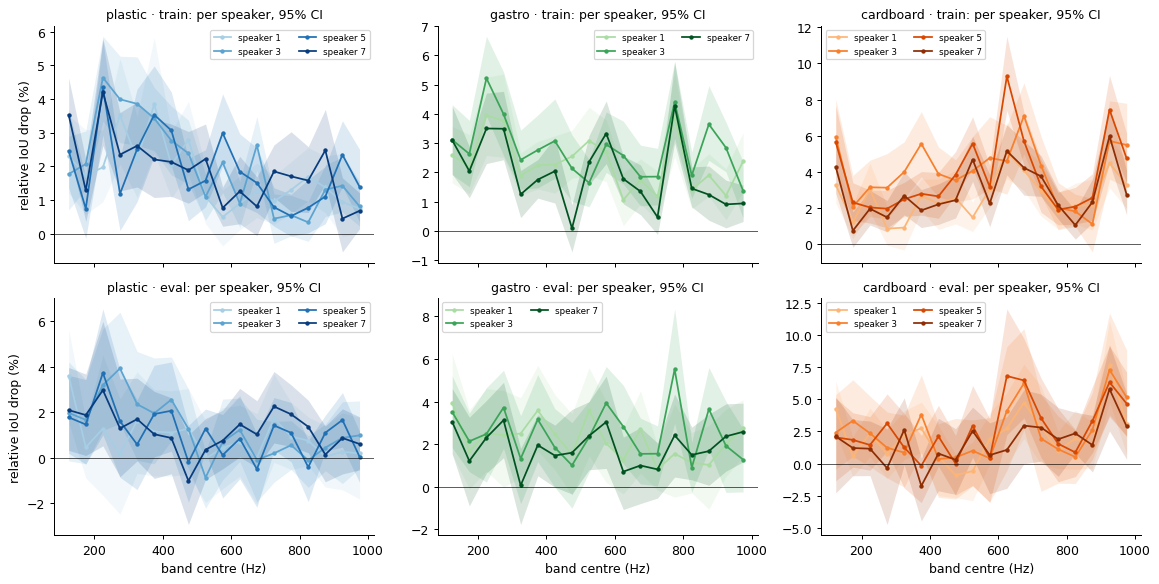

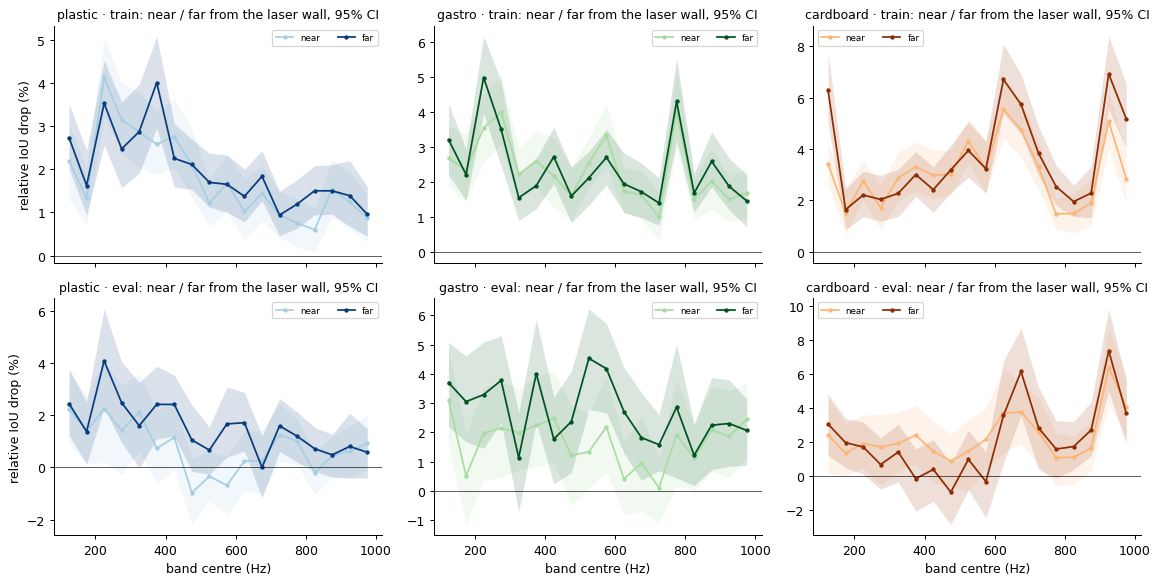

In [35]:
# FQ1.3 · same grouping for speaker and for position region
# region: CoM row of the GT mask; the laser wall is the bottom of the overhead crop (nb96 §9), so near = row above the box's median (per set)
for s in SETS:
    for b in BX: d = FD[s, b]; d["reg"] = np.where(d["row"] > np.median(d["row"]), "near", "far")
print("speaker counts\n", pd.DataFrame({(s, b): pd.Series(FD[s, b]["spk"]).value_counts() for s in SETS for b in BX}).fillna(0).astype(int).to_string())
print("CoM row range per box (64 px):", {(s, b): (FD[s, b]["row"].min().round(1), np.median(FD[s, b]["row"]).round(1), FD[s, b]["row"].max().round(1)) for s in SETS for b in BX})
SPK, RG, rows = {}, {}, []
for s in SETS:
    for b in BX:
        d = FD[s, b]; GS = [k for k in np.unique(d["spk"]) if (d["spk"] == k).sum() >= 15]; k = np.isin(d["spk"], GS); dk = {x: v[k] for x, v in d.items()}
        SPK[s, b], RG[s, b] = gboot(dk, dk["spk"], GS), gboot(d, d["reg"], ["near", "far"])
        for name, dd, g, GG in (("speaker", dk, dk["spk"], GS), ("region", d, d["reg"], ["near", "far"])):
            r, _ = gtest(dd, g, GG, n_perm=500)
            PP = profiles(dd, g, GG)
            rows.append(dict(group=name, set=s, box=b, n_groups=len(GG), **{x: round(v, 3) for x, v in r.items()},
                             peaks=" / ".join(f"{gg}:{HZ[p.argmax()]:.0f}" for gg, p in zip(GG, PP)), wmf=" / ".join(f"{gg}:{wmf(p):.0f}" for gg, p in zip(GG, PP)),
                             lvl=" / ".join(f"{gg}:{100 * p.sum():.0f}" for gg, p in zip(GG, PP))))
U4 = pd.DataFrame(rows); print(U4.drop(columns=["peaks", "wmf", "lvl"]).to_string(index=False)); print(U4[["group", "set", "box", "peaks", "wmf", "lvl"]].to_string(index=False))
lines(SPK, lambda g: f"speaker {g}", "per speaker, 95% CI")
lines(RG, str, "near / far from the laser wall, 95% CI")

**Answer.**
- **Speaker changes the shape on train** (p_ρ .002 / .016 / .002, p_Fz .002 / .040 / .002), e.g. plastic speaker 1 peaks at 375 Hz while the other speakers peak at 225 Hz, and cardboard speaker 7 peaks at 925 Hz vs 625–675 Hz. **On eval it is noise** (p_ρ .51–.82, p_Fz .56–.71). The memorised train regime reads speaker-specific bands; this does not hold on held-out positions.
- **Region: weak.** Shape p_Fz ≥ .23 except cardboard train (.010). Level differs only in gastro eval (near 30% vs far 48%, p_F .042) and cardboard train (p .028). Weighted mean frequency near / far differs by ≤ 46 Hz.

#### FQ1.4 · Physics check: do bigger objects read lower bands?
No masses are stored for candle / red-cube / soap dispenser / vase (only the cylinder series has grams), so size = median GT mask area. Per (set, box, object): importance-weighted mean frequency with bootstrap CI, and overall level.

  set       box            obj  area  clean    wmf  wmf_lo  wmf_hi   lvl
train   plastic         candle 132.5   0.93 467.06  440.80  491.75 25.13
train   plastic       red-cube  36.0   0.93 481.59  446.65  512.10 52.20
train   plastic soap dispenser  62.5   0.93 455.17  421.08  486.99 30.39
train   plastic           vase  77.0   0.92 434.03  396.43  468.03 28.90
train    gastro         candle 113.0   0.92 526.60  505.39  545.76 32.03
train    gastro       red-cube  32.0   0.89 482.21  451.29  512.61 53.34
train    gastro soap dispenser  50.0   0.92 533.52  507.94  560.86 52.12
train    gastro           vase  67.0   0.91 493.35  465.60  517.99 34.94
train cardboard         candle 148.5   0.92 616.17  591.65  642.71 36.66
train cardboard       red-cube  40.0   0.89 553.75  527.97  577.55 93.98
train cardboard soap dispenser  74.0   0.91 582.27  566.89  597.96 69.60
train cardboard           vase  86.0   0.91 580.68  556.44  605.21 43.74
 eval   plastic         candle 135.5   0.81 463.20 

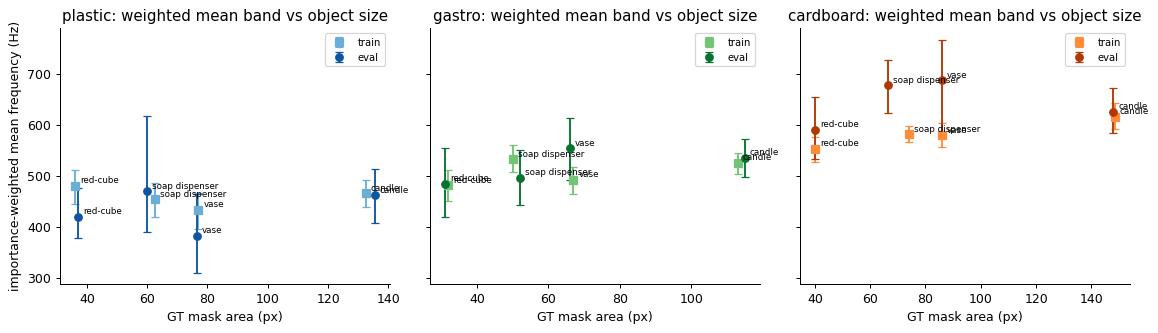

In [36]:
# FQ1.4 · physics check: weighted mean frequency (and total level) per object vs object size
# no masses are stored for these four objects; size = GT mask area (px of 64×64), median over the object's samples in that box (one eval gastro red-cube mask, pos 1255, is the full frame: 4069 px, IoU .02)
rows = []
for s in SETS:
    for b in BX:
        d = FD[s, b]
        for o in OBJ:
            k, bt = d["obj"] == o, OB[s, b][o]; w = wmf(bt)
            rows.append(dict(set=s, box=b, obj=o, area=np.median(d["area"][k]), clean=d["c"][k].mean(), wmf=wmf(relb(d["m"][k], d["c"][k])),
                             wmf_lo=np.percentile(w, 2.5), wmf_hi=np.percentile(w, 97.5), lvl=100 * relb(d["m"][k], d["c"][k]).sum()))
U5 = pd.DataFrame(rows); print(U5.round(2).to_string(index=False))
print("\nSpearman over the 24 (set, box, object) cells:", {c: round(rho(U5.area, U5[c]), 2) for c in ("wmf", "lvl", "clean")})
print("within box (4 objects × 2 sets = 8 points):", {b: {c: round(rho(U5.area[U5.box == b], U5[c][U5.box == b]), 2) for c in ("wmf", "lvl")} for b in BX})
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a, b in zip(ax, BX):
    for i, s in enumerate(SETS):
        t = U5[(U5.box == b) & (U5.set == s)]; col = FCM[b](.5 + .35 * i)
        a.errorbar(t.area, t.wmf, yerr=[t.wmf - t.wmf_lo, t.wmf_hi - t.wmf], fmt="o" if i else "s", c=col, capsize=3, label=s)
        [a.annotate(o, (x, y), fontsize=7, xytext=(4, 2), textcoords="offset points") for o, x, y in zip(t.obj, t.area, t.wmf)]
    a.set_title(f"{b}: weighted mean band vs object size"); a.set_xlabel("GT mask area (px)"); a.legend(fontsize=8)
ax[0].set_ylabel("importance-weighted mean frequency (Hz)"); plt.tight_layout(); plt.show()

**FQ1 answer** (240 samples per box and set, 60 per object).

**Only plastic's peak is stable; the per-box claim should be the weighted mean frequency.**
- **Peaks.** Plastic's 225 Hz peak holds (bootstrap P(peak) .90 train / .78 eval). Gastro's does not: train 225 Hz wins 53% of resamples (775 Hz 42%), eval 125 Hz only 32%, and 16 of 18 band CIs overlap its CI. Cardboard is a near-tie on train (625 Hz 59% / 925 Hz 40%) and decisive on eval (925 Hz 98%). The train → eval "moves" in Q1 are mostly re-rankings of near-tied bands.
- **Weighted mean frequency is the stable box-level quantity:** **train 463 / 508 / 576 Hz, eval 423 / 516 / 639 Hz** (plastic / gastro / cardboard; CIs ±15–40 Hz). It rises **plastic < gastro < cardboard** in both sets. Cardboard's eval rise (CI [604, 680] vs [565, 588] Hz) is the only real shift.
- **Objects do not change the band profile.** The mean pairwise ρ between the 4 object profiles equals the label-shuffle null in every cell (**p .19–.71**; e.g. train .73 / .64 / .84 vs null .75 / .67 / .83). It also equals the within-object split-half ceiling: two random halves of one object disagree as much as two objects do. The same object's train and eval profiles agree no better than different objects' (ρ .33–.49 vs .34–.47).
- **Objects do change the overall sensitivity.** The **red-cube is 1.2–3.6× more band-sensitive** than the mean of the other three objects, in every box and set (Σ drop 47–94% vs 10–70%; dispersion F p ≤ .006, also within speaker). It is the smallest object (≈ 31–41 px), and ρ(area, Σ drop) = −.63. The likely cause is that a small mask's IoU is fragile to any lost evidence, not that the cube reads different bands.
- **No mass-loading size trend.** Over the 24 (set, box, object) cells, ρ(area, weighted mean frequency) = **+.23**, the opposite sign to "larger object → lower bands" (within box −.19 / +.60 / +.37 on 8 points each; per-object CIs ±20–115 Hz overlap). Box stiffness matters far more than the object. Masses are not stored for these four objects, so size stands in for mass.
- **Speaker and position (secondary).** Speakers change the profile shape on train (p_ρ .002–.016) but not on eval (p ≥ .5). Near vs far from the laser wall barely matters (shape p ≥ .23 except cardboard train, p_Fz .010).
- **Data note.** The GT mask of gastro red-cube eval position **1255** is the full frame (4069 of 4096 px, IoU .02): a broken label. It is one of 60 samples and does not change the medians above.

## Summary

| # | question | short answer |
|---|---|---|
| 1 | what is read | spatial pattern across lasers (wall-mean −84%), sharp modal lines (smoothing −39%); half the IoU needs 5–7 of 18 bands / ~35 of 100 lasers; box band specialisation visible only by masking — attention ≈ SVD ≈ input energy (ρ .93–.97), not use |
| 2 | physical signature | object Δ only 1.3–2.8× repeat noise and dominated by drift; IoU rises with cylinder size; unseen cylinders are found (≤1.3 px) but painted 3–15× too big |
| 3 | where position is | linearly in the raw levels (R² .87–.93, every band); the network gives 5× precision (0.75 vs 4.0 px) |
| 4 | latent geometry | context code first (box/speaker/object ≥ 99%), position in PCs 9–32; low-variance tail = memorization |
| 5 | interpolation? | yes: .60 vs NN oracles .37/.32; flat to 3 px from training positions |
| 6 | success predictors | object area, confidence, distance to training, latent novelty (R² .74); edges irrelevant |
| 7 | knows when wrong | mask confidence AUROC .84; masks ~binary, threshold irrelevant |
| 8 | speaker / noise | half the latent is still speaker; ripple ≫ tilt; 10 dB SNR → .15 |
| 9 | laser array | non-local fingerprint, no single laser matters, no equivariance; ±1 cell shift −.06 |
| 10 | off-distribution | two failure modes (too small = low novelty, global box change = high novelty); unseen objects snap to a class size prior |

**Why runs succeed or fail, in one line each.**
- **Success:** a mid-to-large object (≥ 40 px) within ~3 px of training positions, in a box/speaker state the encoder has seen. The model then interpolates a precise (< 1 px) location from a non-local modal fingerprint and pastes a class-size blob.
- **Failure:** the object is small or light (signal under the drift floor), the box state changes globally (lid, speaker 4 in gastro, shifted lasers), or the object's size is far from any training class.

Caveats: single seed / single checkpoint (ep300). The ablation subset is ≤ 30 samples per eval split (per-split numbers ±.05). Occlusion uses the model's own token masks (trained with dropout on 10% of samples, so a drop is in-distribution). Cylinder mass and size are confounded. The mirror / axis-duplication probes are OOD inputs, so they bound reliance but do not give clean attribution.